# O que o total nacional não conta
## Etapa 1 — EDA completa do TCC com Google Meridian

Este notebook reúne **todo o processo exploratório já realizado**, desde a auditoria dos dados até a prontidão para modelagem. Você pode lê-lo como uma investigação contínua: pergunta, explicação, código, evidência e interpretação. Não é necessário abrir outro notebook ou um módulo Python para acompanhar os cálculos.

**Origem preservada:** `MMM_Google_Meridian_Project`, commit `ef39d0a7629e849d31582cea6cefccb581f7a445`. As saídas visíveis foram transportadas dessa versão e as figuras foram incorporadas a partir dos SVGs originais. São **resultados históricos preservados**, não uma declaração de nova execução integral. A consolidação foi verificada separadamente; o registro está no final deste notebook.

**Como usar:** para estudar, leia as células e seus resultados já salvos. Para recalcular, execute de cima para baixo, em Python 3.12+ / Colab CPU novo. A instalação inicial exige internet e pode demandar reinício do runtime. Toda a lógica está aqui; não há clone nem importação de `src`. A base pública é baixada do commit oficial e conferida por SHA-256, ou reutilizada quando disponível localmente.

As pastas guardam cópias exportadas para citação, auditoria e uso nas próximas etapas. O arquivo `docs/EDA_DIDACTIC_GUIDE.md` foi copiado integralmente. Seus links para notebooks antigos são referências históricas; este passa a ser o ponto de entrada executável.

**Limite da etapa:** dados simulados; nenhuma posterior estimada; nenhuma conclusão de ROI, incrementalidade ou orçamento ótimo.

### Percurso

1. Ambiente, origem e instrumentos da investigação.
2. Auditoria: uma semana, um mercado, uma linha.
3. Escala, zeros, extremos e atividade.
4. O movimento nacional e seus limites temporais.
5. Geografia, população, within/between e resíduo geo-temporal.
6. Mix, alocação e calendário de cada canal.
7. Associações, controles, VIF e defasagens.
8. A segunda opinião do Meridian e os seis REVIEW.
9. Síntese, fronteiras e próximas perguntas do TCC.

## Prólogo — A publicidade ajudou?

Imagine cuidar da publicidade de uma empresa que atende muitos mercados. Toda semana chega uma planilha: quanto foi gasto, quantos anúncios foram exibidos e quantas ações os clientes realizaram. A pergunta parece simples. Depois de todo esse investimento, a publicidade ajudou?

Talvez o resultado tenha aumentado. Mas também havia mais gente procurando o produto. Talvez uma promoção tenha coincidido com os anúncios. Talvez a empresa tenha escolhido investir justamente onde já esperava vender mais. Mesmo uma semana sem crescimento pode esconder uma contribuição importante: sem publicidade, o resultado poderia ter sido pior.

Esse último pensamento revela a dificuldade. Vemos o que aconteceu. Não vemos, no mesmo lugar e na mesma semana, o que teria acontecido se a empresa tivesse tomado outra decisão. Comparar o resultado com a semana anterior não resolve automaticamente o problema, porque o mundo também mudou entre as duas semanas.

Agora imagine que alguém entregue apenas o total nacional. Temos uma linha que sobe e desce ao longo dos meses. Ela resume o resultado, mas não conta quem participou de cada movimento. Uma semana estável pode ter sido tranquila em todos os mercados ou ter combinado grandes avanços em alguns com quedas em outros. O mesmo número final pode nascer de histórias diferentes.

É nessa distância entre o número e a história que começa este trabalho. Antes de tentar atribuir resultados à publicidade, precisamos descobrir o que os dados deixam enxergar. Será que guardar o endereço de cada observação oferece pistas que desaparecem quando somamos tudo?

A empresa desta abertura é uma imagem para ajudar a pensar. Os dados que vamos investigar são simulados, publicados pelo projeto Google Meridian. Não pertencem a uma marca real, e os nomes dos mercados não identificam cidades. Podemos observar seus padrões e estudar métodos com eles; não podemos inventar campanhas, feriados ou decisões comerciais para explicar o que encontramos.

## Capítulo 1 — Antes do modelo, o terreno

Para responder à pergunta da publicidade, gostaríamos de acompanhar várias coisas ao mesmo tempo. O resultado da empresa, a presença dos anúncios, as mudanças de demanda e outros fatores capazes de participar da história. Olhar uma coluna isolada seria como tentar entender uma partida acompanhando apenas um jogador.

É para enfrentar esse problema que existe o **Marketing Mix Modeling**, ou **MMM**. Ele usa modelos estatísticos para relacionar a evolução do resultado às ações de marketing e a outros fatores. A ambição é entender a contribuição dessas ações, inclusive o que poderia mudar sob decisões diferentes. Fazer essa passagem exige hipóteses sobre como os dados foram produzidos; ver duas coisas mudarem juntas não demonstra que uma provocou a outra. É essa diferença entre acompanhar e causar que precisamos respeitar quando falamos em efeitos causais. Um modelo não resolve a distinção só porque realiza muitos cálculos.

O Google Meridian é a ferramenta escolhida para a futura modelagem deste TCC. Contudo, ter uma ferramenta disponível não significa que seja hora de utilizá-la para estimar efeitos. Primeiro precisamos saber se temos as peças necessárias para formular uma pergunta que ela consiga enfrentar.

Pense em uma construção. Antes de escolher paredes e acabamentos, precisamos conhecer o terreno. Um desenho pode parecer excelente e ainda ser inadequado ao solo. Aqui, o terreno são os dados: onde existem registros, quanto eles mudam e quais coisas aparecem sempre juntas. A **análise exploratória de dados**, abreviada como **EDA**, é essa investigação anterior à construção.

Se um canal aparece apenas em poucas semanas, teremos uma situação diferente daquela em que ele está presente continuamente. Se todos os canais aumentam juntos, observar o resultado depois do aumento pode não revelar qual deles participou mais. Se mercados maiores apresentam mais publicidade e mais resultados, comparar volumes sem considerar tamanho pode nos conduzir a uma história enganosa.

Não precisamos resolver esses problemas neste primeiro momento. Precisamos aprender a reconhecê-los. Ao final da EDA, queremos saber o que vale a pena perguntar ao modelo, que cuidados ele terá de incorporar e quais respostas ainda estarão fora de alcance.

Para isso, deixaremos a planilha se tornar concreta. Antes de investigar relações entre suas colunas, precisamos conhecer o que cada uma está tentando representar.

## Preparação — manter o experimento reconhecível

Antes de calcular, fixamos a versão do Meridian, a origem da base e a semente. Pense no checksum como a impressão digital do arquivo: se um único byte mudar, a execução deve avisar, em vez de misturar resultados de bases diferentes. A célula não publica arquivos nem altera o GitHub.

O diretório de trabalho será o repositório novo, quando aberto dentro dele; fora dele, será criada uma pasta local `MMM_Google_Meridian_Project2`. A configuração `INSTALL_DEPENDENCIES` pode ser desligada em um ambiente já preparado. O instalador preserva dependências compatíveis e exige a origem fixada do Meridian.

In [ ]:
import os, sys, subprocess, importlib.util, importlib.metadata, json
from pathlib import Path
SOURCE_COMMIT = 'ef39d0a7629e849d31582cea6cefccb581f7a445'
INSTALL_DEPENDENCIES = True
UPSTREAM_COMMIT = '02111531f8661373aa7b6ba31c316c67d72d1dd2'
cwd = Path.cwd()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if p.name == 'MMM_Google_Meridian_Project2'), cwd / 'MMM_Google_Meridian_Project2')
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_ROOT)
os.environ.setdefault('MPLCONFIGDIR', str(PROJECT_ROOT / 'outputs/.mplcache'))
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
REQUIREMENTS = '# Commit oficial verificado. Pin necessário para API, transformações e checks reproduzíveis.\ngoogle-meridian @ git+https://github.com/google/meridian.git@02111531f8661373aa7b6ba31c316c67d72d1dd2\nnbformat>=5\nnbclient>=0.10\nipykernel>=6\npytest>=8\ntabulate>=0.9\n# numpy/pandas/scipy/matplotlib/statsmodels são delimitados pelo próprio Meridian.\n'
SOURCE_METADATA = json.loads('{\n  "dataset": "geo_all_channels.csv",\n  "kind": "simulated",\n  "commit": "02111531f8661373aa7b6ba31c316c67d72d1dd2",\n  "source": "https://raw.githubusercontent.com/google/meridian/02111531f8661373aa7b6ba31c316c67d72d1dd2/meridian/data/simulated_data/csv/geo_all_channels.csv",\n  "sha256": "d9ee016f7cd21f5c90b50da10a794af91a372b69f881d3caa266edd41fdafbf6",\n  "original_rows": 6240,\n  "original_columns": 20,\n  "accessed_utc": "2026-10-03T10:29:33.864348+00:00",\n  "license": "Apache-2.0; see MERIDIAN_LICENSE"\n}')
(PROJECT_ROOT / 'data/metadata').mkdir(parents=True, exist_ok=True)
metadata_path = PROJECT_ROOT / 'data/metadata/source.json'
if metadata_path.exists() and json.loads(metadata_path.read_text()) != SOURCE_METADATA:
    raise RuntimeError('Metadados locais diferentes da fonte fixada; use uma pasta nova.')
metadata_path.write_text(json.dumps(SOURCE_METADATA, indent=2), encoding='utf-8')
needed = ['meridian', 'pandas', 'numpy', 'scipy', 'matplotlib', 'statsmodels', 'tabulate']
missing = any(importlib.util.find_spec(p) is None for p in needed)
try:
    origin = json.loads(importlib.metadata.distribution('google-meridian').read_text('direct_url.json') or '{}')
    correct_origin = origin.get('vcs_info', {}).get('commit_id') == UPSTREAM_COMMIT and origin.get('url', '').rstrip('/') == 'https://github.com/google/meridian.git'
except importlib.metadata.PackageNotFoundError:
    correct_origin = False
if missing or not correct_origin:
    if not INSTALL_DEPENDENCIES:
        raise RuntimeError('Dependências ausentes ou Meridian fora do commit fixado.')
    dependency_file = PROJECT_ROOT / 'requirements.txt'
    dependency_file.write_text(REQUIREMENTS, encoding='utf-8')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(dependency_file)], check=True)
    print('Instalação concluída. Se o runtime já carregou versões diferentes, reinicie-o antes de continuar.')
print('Pasta de execução:', PROJECT_ROOT)
print('Origem analítica preservada:', SOURCE_COMMIT)


## Instrumentos comuns — o que será reutilizado

Uma investigação longa repete operações: conferir colunas, somar com o denominador correto, exportar tabelas e desenhar figuras. As próximas células definem essas ferramentas uma vez. **Definir uma função não executa a análise**: ela descreve a receita que será chamada em cada capítulo. Isso evita reescrever fórmulas e mantém a equivalência com a EDA auditada.

As etapas continuam identificadas internamente por 00–07 para rastrear os resultados antigos; são seções deste único notebook, não arquivos separados.

In [ ]:
"""Configuração auditável; caminhos relativos à raiz do projeto."""

from pathlib import Path

ROOT = PROJECT_ROOT

SEED = 20261003

UPSTREAM_COMMIT = '02111531f8661373aa7b6ba31c316c67d72d1dd2'

SOURCE_PATH = 'meridian/data/simulated_data/csv/geo_all_channels.csv'

DATA_URL = f'https://raw.githubusercontent.com/google/meridian/{UPSTREAM_COMMIT}/{SOURCE_PATH}'

RAW = ROOT / 'data/raw/geo_all_channels.csv'

KPI = 'conversions'

GEO, TIME, POP = 'geo', 'time', 'population'

CONTROLS = ['competitor_sales_control', 'sentiment_score_control']

ORGANIC = ['Organic_channel0_impression']

NON_MEDIA = ['Promo']

REVENUE_PER_KPI = 'revenue_per_conversion'

"""Aquisição, contrato de schema e agregação com semântica explícita."""

import hashlib

import importlib.metadata

import json

import logging

import platform

import re

from datetime import datetime, timezone

from urllib.request import urlopen

import numpy as np

import pandas as pd

"""Estatísticas descritivas sem testes de significância para observações dependentes."""

import numpy as np

import pandas as pd

"""Auditoria antes de calcular estatísticas: nunca imputar ou corrigir silenciosamente."""

import numpy as np

import pandas as pd

"""Gráficos acadêmicos: SVG vetorial versionado e PNG 180 dpi na execução."""

import logging

import re

import json

import pandas as pd

import xml.etree.ElementTree as ET

import numpy as np

import matplotlib

matplotlib.use('Agg')

import matplotlib.pyplot as plt

plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,
                     'figure.dpi':110,'savefig.dpi':180,'svg.fonttype':'none'})

"""Exportação, resultados calculados e checkpoints didáticos."""

import json

import logging

from pathlib import Path

import pandas as pd

"""Investigações localizadas motivadas pela auditoria, sem remoção de dados."""

from pathlib import Path

import numpy as np

import pandas as pd

"""Capítulos 00–02 e 05: integridade, escala, tempo e relações."""

import logging

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

"""Capítulos centrais: heterogeneidade GEO e execução territorial de mídia."""

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

"""Camada independente de auditoria: API Google Meridian 2.1.0 verificada no commit fixado."""

import dataclasses

import importlib.metadata

import json

import warnings

import numpy as np

import pandas as pd

"""Reconciliação independente e revisão localizada, sem alterar thresholds."""

import dataclasses

import numpy as np

import pandas as pd


In [ ]:
def directories() -> None:
    for folder in ['data/raw', 'data/processed', 'data/metadata', 'outputs/tables',
                   'outputs/reports', 'outputs/logs', 'docs']:
        (ROOT / folder).mkdir(parents=True, exist_ok=True)
    for chapter in ['data_audit', 'general', 'temporal', 'geo', 'media_geo', 'relationships']:
        (ROOT / 'outputs/figures' / chapter).mkdir(parents=True, exist_ok=True)


### Proveniência da execução independente

O controle abaixo grava os checksums dos resultados, as versões das bibliotecas e as funções efetivamente carregadas. Antes da conclusão, confere se as etapas anteriores terminaram e se seus arquivos ou funções mudaram. O manifesto se chama `notebook_run_manifest.json`, separado do manifesto histórico copiado do projeto original. Assim, uma saída antiga existente não será aceita como prova de uma etapa recém-executada.

Esta é uma adaptação de infraestrutura: substitui a exigência de clone Git por um registro das funções em memória. Não altera os cálculos. A apresentação também passa a exibir todas as figuras, inclusive as anteriormente remetidas ao apêndice.

In [ ]:
# Adaptação de infraestrutura para execução independente, sem clone obrigatório.
import functools, hashlib, importlib.metadata, inspect, json, marshal, types
from datetime import datetime, timezone
from pathlib import Path
MANIFEST = ROOT / 'outputs/logs/notebook_run_manifest.json'
_active = None
_written = set()

def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix('.tmp')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    temp.replace(path)

def verify_meridian_origin():
    origin = json.loads(importlib.metadata.distribution('google-meridian').read_text('direct_url.json') or '{}')
    if origin.get('vcs_info', {}).get('commit_id') != UPSTREAM_COMMIT or origin.get('url', '').rstrip('/') != 'https://github.com/google/meridian.git':
        raise RuntimeError('Origem/commit Meridian incompatível: instale a dependência fixada no início.')
    return origin

def fingerprint():
    versions = {p: importlib.metadata.version(p) for p in
                ['google-meridian', 'numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'jax', 'tensorflow']}
    return {'raw_sha256': digest(RAW), 'versions': versions,
            'meridian_origin': verify_meridian_origin(),
            'configuration': [SEED, UPSTREAM_COMMIT, KPI, GEO, TIME, POP, CONTROLS, ORGANIC, NON_MEDIA]}

def code_state():
    # Cada etapa registra as funções já definidas. Redefini-las invalida a síntese.
    state = {}
    for name, value in list(globals().items()):
        if isinstance(value, types.FunctionType) and value.__module__ == __name__:
            function = inspect.unwrap(value)
            state[name] = hashlib.sha256(marshal.dumps(function.__code__)).hexdigest()
    return state

def record(path):
    if _active is not None:
        _written.add(str(Path(path).resolve().relative_to(ROOT)))

def require_stages(stages=range(7)):
    if not MANIFEST.exists():
        raise RuntimeError('Manifesto desta execução ausente. Execute o notebook de cima para baixo.')
    manifest = json.loads(MANIFEST.read_text())
    current, code = fingerprint(), code_state()
    for stage in stages:
        info = manifest.get('stages', {}).get(f'{stage:02}', {})
        if info.get('status') != 'complete' or info.get('fingerprint') != current:
            raise RuntimeError(f'Etapa {stage:02} ausente/desatualizada; reexecute.')
        if any(code.get(k) != v for k, v in info.get('code_hashes', {}).items()):
            raise RuntimeError(f'Código alterado após a etapa {stage:02}; reexecute desde o início.')
        for name, checksum in info['files'].items():
            if not (ROOT/name).exists() or digest(ROOT/name) != checksum:
                raise RuntimeError(f'Output alterado/ausente: {name}')
    return manifest

def tracked(stage):
    def decorate(function):
        @functools.wraps(function)
        def wrapped(*args, **kwargs):
            global _active, _written
            if _active is not None:
                raise RuntimeError('Etapas aninhadas não suportadas')
            _active, _written = stage, set()
            manifest = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {'stages': {}}
            info = {'status': 'running', 'started_utc': datetime.now(timezone.utc).isoformat(),
                    'original_source_commit': SOURCE_COMMIT, 'fingerprint': fingerprint(),
                    'code_hashes': code_state()}
            manifest['stages'][stage] = info
            write_json(MANIFEST, manifest)
            try:
                result = function(*args, **kwargs)
                if fingerprint() != info['fingerprint']:
                    raise RuntimeError('Dados/configuração/ambiente mudaram durante a etapa.')
                info.update(status='complete', finished_utc=datetime.now(timezone.utc).isoformat(),
                            files={p: digest(ROOT/p) for p in sorted(_written)})
                return result
            except Exception as exc:
                info.update(status='failed', error=str(exc))
                raise
            finally:
                manifest['stages'][stage] = info
                write_json(MANIFEST, manifest)
                _active, _written = None, set()
        return wrapped
    return decorate

def show(report, part='all'):
    from IPython.display import display, Markdown, Image
    if part in ['all', 'summary']:
        display(Markdown(report['narrative']))
    if part == 'summary':
        return
    for name, frame in report['tables'].items():
        display(Markdown(f'**{name}** — {len(frame)} linhas.'))
        with pd.option_context('display.max_rows', 60, 'display.max_columns', None):
            if len(frame) <= 50:
                display(frame)
            else:
                display(Markdown('Primeiras 12 linhas; a síntese interpreta a tabela completa. O CSV integral é exportado automaticamente.'))
                display(frame.head(12))
    for path in report['figures']:
        display(Markdown(figure_comment(path)))
        display(Image(filename=str(path), width=950))


### Ler a base sem mudar sua história

Se `raw` já existir, verificamos sua assinatura. Caso contrário, baixamos a fonte fixada. Retiramos apenas o índice exportado validado e ordenamos geo e data. Na agregação nacional, somamos conversões, impressões e gasto; controles e Promo usam média ponderada por população. Uma média de índices e uma soma de volumes respondem perguntas diferentes.

Código original de `src/data.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def channels(frame: pd.DataFrame) -> list[str]:
    """Descobre os pares reais de impressão/gasto; rejeita pares incompletos."""
    found = sorted(c.removesuffix('_impression') for c in frame
                   if re.fullmatch(r'Channel\d+_impression', c))
    if not found or any(f'{c}_spend' not in frame for c in found):
        raise ValueError('Schema de mídia paga inesperado; revisar mapeamento oficial.')
    if set(c.removesuffix('_spend') for c in frame if c.endswith('_spend')) != set(found):
        raise ValueError('Gasto sem correspondente de mídia.')
    return found

def roles(frame: pd.DataFrame) -> dict[str, str]:
    mapped = {GEO:'geo', TIME:'time', KPI:'kpi', POP:'population',
              REVENUE_PER_KPI:'revenue_per_kpi', 'Unnamed: 0':'export_index'}
    for group, names in [('control',CONTROLS), ('organic_media',ORGANIC), ('non_media_treatment',NON_MEDIA)]:
        mapped.update(dict.fromkeys(names, group))
    for channel in channels(frame):
        mapped[channel+'_impression'] = 'media'
        mapped[channel+'_spend'] = 'spend'
    unknown = set(frame) - set(mapped)
    missing = set(mapped) - {'Unnamed: 0'} - set(frame)
    if unknown or missing:
        raise ValueError(f'Schema mudou: desconhecidas={unknown}; ausentes={missing}')
    return {c:mapped[c] for c in frame}

def load_panel() -> pd.DataFrame:
    """Mantém raw imutável e verifica o checksum de referência antes da análise."""
    directories()
    logging.basicConfig(filename=ROOT/'outputs/logs/execution.log', level=logging.INFO,
                        format='%(asctime)s %(levelname)s %(message)s', force=True)
    if not RAW.exists():
        with urlopen(DATA_URL, timeout=60) as response:
            payload = response.read()
        reference = json.loads((ROOT/'data/metadata/source.json').read_text())
        if hashlib.sha256(payload).hexdigest() != reference['sha256']:
            raise ValueError('Download diverge do checksum documentado.')
        RAW.write_bytes(payload)
    checksum = hashlib.sha256(RAW.read_bytes()).hexdigest()
    reference = json.loads((ROOT/'data/metadata/source.json').read_text())
    if checksum != reference['sha256']:
        raise ValueError('Arquivo raw alterado; restaurar a versão documentada.')
    panel = pd.read_csv(RAW)
    roles(panel)
    if 'Unnamed: 0' in panel:
        if not np.array_equal(panel['Unnamed: 0'].to_numpy(), np.arange(len(panel))):
            raise ValueError('Índice exportado inesperado; não remover automaticamente.')
        panel = panel.drop(columns='Unnamed: 0')
    panel[TIME] = pd.to_datetime(panel[TIME], errors='raise')
    panel = panel.sort_values([GEO,TIME]).reset_index(drop=True)
    panel.to_csv(ROOT/'data/processed/geo_time_panel.csv', index=False)
    versions = {'python':platform.python_version()}
    for package in ['google-meridian','numpy','pandas','scipy','matplotlib','statsmodels',
                    'jax','tensorflow','nbformat','nbclient']:
        try: versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError: versions[package] = 'not installed'
    execution = {'accessed_utc':datetime.now(timezone.utc).isoformat(), 'versions':versions,
                 'sha256':checksum, 'rows':len(panel), 'geos':panel[GEO].nunique(),
                 'periods':panel[TIME].nunique(), 'seed':SEED}
    (ROOT/'data/metadata/execution.json').write_text(json.dumps(execution,indent=2))
    logging.info('Dataset carregado e checksum validado: %s',execution)
    return panel

def analytical_columns(panel: pd.DataFrame) -> list[str]:
    return [KPI] + [c+'_impression' for c in channels(panel)] + [c+'_spend' for c in channels(panel)] + ORGANIC + CONTROLS + NON_MEDIA

def national(panel: pd.DataFrame) -> pd.DataFrame:
    """Soma contagens/gastos; controles e promoção usam média ponderada por população.

    A unidade original dos controles sintéticos é desconhecida. A média ponderada
    é uma lente descritiva explícita, não uma soma de vendas de concorrentes.
    """
    additive = [KPI] + [c+'_impression' for c in channels(panel)] + [c+'_spend' for c in channels(panel)] + ORGANIC
    result = panel.groupby(TIME)[additive].sum(min_count=1)
    population = panel.groupby(TIME)[POP].sum(min_count=1)
    for col in CONTROLS + NON_MEDIA:
        result[col] = (panel[col]*panel[POP]).groupby(panel[TIME]).sum(min_count=1)/population
    result['revenue_derived'] = (panel[KPI]*panel[REVENUE_PER_KPI]).groupby(panel[TIME]).sum(min_count=1)
    result[REVENUE_PER_KPI] = result['revenue_derived']/result[KPI].replace(0,np.nan)
    result[POP] = population
    return result


### O contrato da ficha semanal

Antes de interpretar um zero como ausência de mídia, verificamos que a ficha existe, que não está duplicada e que seus domínios são válidos. Uma violação interrompe a análise depois de registrar a auditoria.

Código original de `src/validation.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def audit(panel: pd.DataFrame) -> pd.DataFrame:
    roles(panel)
    dates=pd.DatetimeIndex(sorted(panel[TIME].unique()))
    complete=pd.MultiIndex.from_product([sorted(panel[GEO].unique()), dates],names=[GEO,TIME])
    present=pd.MultiIndex.from_frame(panel[[GEO,TIME]])
    nonnegative=[KPI,POP,REVENUE_PER_KPI]+[c for c,r in roles(panel).items() if r in ['media','spend','organic_media']]
    gaps=dates.to_series().diff().dropna().dt.days
    checks={
        'rows':len(panel),'geos':panel[GEO].nunique(),'periods':panel[TIME].nunique(),
        'expected_rows':len(complete),'unique_geo_time':len(present.unique()),
        'panel_completeness':len(present.unique())/len(complete),
        'duplicate_keys':int(panel.duplicated([GEO,TIME]).sum()),
        'missing_geo_time':len(complete.difference(present)),
        'missing_cells':int(panel.isna().sum().sum()),
        'nonfinite_numeric':int((~np.isfinite(panel.select_dtypes('number'))).sum().sum()),
        'negative_domain_values':int((panel[nonnegative]<0).sum().sum()),
        'nonpositive_population':int((panel[POP]<=0).sum()),
        'population_varying_geos':int((panel.groupby(GEO)[POP].nunique()>1).sum()),
        'regular_weekly_grid':bool(len(gaps)>0 and gaps.eq(7).all()),
        'first_date':str(dates.min().date()),'last_date':str(dates.max().date()),
        'paid_channels':len(channels(panel)),'controls':len(CONTROLS),
        'reach_frequency_present':False,
    }
    for channel in channels(panel):
        media,spend=panel[channel+'_impression'],panel[channel+'_spend']
        checks[channel+'_media_positive_spend_zero']=int(((media>0)&(spend==0)).sum())
        checks[channel+'_media_zero_spend_positive']=int(((media==0)&(spend>0)).sum())
    return pd.DataFrame({'metric':checks.keys(),'value':checks.values()})

def require_valid_panel(panel: pd.DataFrame) -> None:
    checks=audit(panel).set_index('metric').value
    fatal=['duplicate_keys','missing_geo_time','missing_cells','nonfinite_numeric',
           'negative_domain_values','nonpositive_population','population_varying_geos']
    failures=[k for k in fatal if checks[k]!=0]
    if not checks['regular_weekly_grid']: failures.append('regular_weekly_grid')
    if failures: raise ValueError(f'Contrato falhou; consultar auditoria, sem imputação: {failures}')

def dictionary(panel: pd.DataFrame) -> pd.DataFrame:
    rows=[]
    for col,role in roles(panel).items():
        x=panel[col]; num=pd.api.types.is_numeric_dtype(x)
        unit={'kpi':'conversões sintéticas (contínuas)', 'population':'população simulada',
              'media':'impressões', 'organic_media':'impressões orgânicas',
              'spend':'unidade monetária não especificada', 'control':'escala sintética; unidade não especificada',
              'revenue_per_kpi':'moeda não especificada/conversão','non_media_treatment':'tratamento contínuo com massa em zero'}.get(role,role)
        rows.append(dict(variable=col,role=role,dtype=str(x.dtype),dimension={'geo':'coordenada geo','time':'coordenada time','population':'geo'}.get(role,'geo × time'),paired_variable=col.replace('_impression','_spend') if role=='media' else col.replace('_spend','_impression') if role=='spend' else '',
                         unit=unit,missing=x.isna().sum(),zeros=x.eq(0).sum() if num else np.nan,
                         min=x.min(),max=x.max(),mean=x.mean() if num else np.nan,std=x.std(ddof=0) if num else np.nan))
    return pd.DataFrame(rows)


### Resumir com o denominador explícito

Usamos variância populacional (`ddof=0`) nos resumos. Uma divisão por zero permanece indefinida. O CV divide desvio padrão pela média e só é interpretável quando a escala permite essa comparação; índices centrados exigem outra leitura.

Código original de `src/statistics.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def safe_divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)

def describe(series: pd.Series) -> dict:
    x = series.dropna()
    q = x.quantile([.01,.05,.25,.5,.75,.95,.99])
    mean, std = x.mean(), x.std(ddof=0)
    return dict(n=len(x),mean=mean,median=x.median(),std=std,variance=x.var(ddof=0),
                min=x.min(),max=x.max(),**{f'p{int(p*100):02}':v for p,v in q.items()},
                iqr=q.loc[.75]-q.loc[.25],cv=std/mean if mean != 0 else np.nan,
                zeros=int(x.eq(0).sum()),zero_share=x.eq(0).mean())


### Gráficos comparáveis e exportáveis

As figuras são salvas em SVG vetorial e PNG. Os heatmaps registram a ordem das linhas e colunas; isso permite detectar uma troca de mercados que poderia parecer um padrão novo. Escalas de cor são próprias de cada figura.

Código original de `src/plots.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def save(fig, chapter: str, name: str):
    folder=ROOT/'outputs/figures'/chapter; folder.mkdir(parents=True,exist_ok=True)
    fig.text(.01,.006,'Fonte: Google Meridian · dados simulados · análise descritiva',fontsize=7,color='#555555')
    fig.tight_layout(rect=(0,.025,1,1))
    for suffix in ['svg','png']:
        path=folder/f'{name}.{suffix}'
        temporary=path.with_suffix('.tmp')
        fig.savefig(temporary,format=suffix,bbox_inches='tight')
        if suffix=='svg':
            if temporary.stat().st_size<500:raise ValueError('SVG vazio')
            ET.parse(temporary)
        temporary.replace(path)
        if suffix=='svg':record(path)
        logging.info('Figura: %s',path)
    plt.close(fig)
    return folder/f'{name}.png'

def heatmap(frame,chapter,name,title,cmap='viridis',vmin=None,vmax=None):
    fig,ax=plt.subplots(figsize=(13,max(4,min(12,len(frame)*.23))))
    im=ax.imshow(frame.to_numpy(dtype=float),aspect='auto',cmap=cmap,vmin=vmin,vmax=vmax,interpolation='nearest')
    ax.set_yticks(np.arange(len(frame)),frame.index.astype(str),fontsize=7)
    is_time=isinstance(frame.columns,pd.DatetimeIndex)
    n=len(frame.columns); ticks=np.unique(np.linspace(0,n-1,min(n,8)).astype(int)) if is_time else np.arange(n)
    ax.set_xticks(ticks,[str(frame.columns[i])[:10] if is_time else str(frame.columns[i]).replace('_impression',' (imp.)').replace('_spend',' (gasto)') for i in ticks],rotation=45,ha='right',fontsize=8)
    path=ROOT/'outputs/logs/heatmap_axes.json';axes=json.loads(path.read_text()) if path.exists() else {}
    axes[f'{chapter}/{name}']={'index':frame.index.astype(str).tolist(),'columns':frame.columns.astype(str).tolist()}
    write_json(path,axes)
    ax.set_title(title);ax.set_xlabel('Semana' if is_time else 'Variável / canal');ax.set_ylabel('GEO' if frame.index.name=='geo' else 'Variável / GEO')
    fig.colorbar(im,ax=ax,shrink=.75)
    return save(fig,chapter,name)

def bars(series,chapter,name,title,ylabel):
    fig,ax=plt.subplots(figsize=(max(8,len(series)*.22),4.8))
    series.plot.bar(ax=ax,color='#245b78');ax.set_title(title);ax.set_ylabel(ylabel)
    ax.tick_params(axis='x',labelsize=8)
    return save(fig,chapter,name)

def lines(frame,chapter,name,title,ylabel):
    fig,ax=plt.subplots(figsize=(12,4))
    xlabel={'time':'Semana','rank':'Posição no ranking de geos','lag_weeks':'Defasagem (semanas)'}.get(frame.index.name,frame.index.name or 'Semana')
    frame.plot(ax=ax);ax.set_title(title);ax.set_ylabel(ylabel);ax.set_xlabel(xlabel)
    return save(fig,chapter,name)

def scatter(x,y,chapter,name,title,xlabel,ylabel):
    fig,ax=plt.subplots(figsize=(6.5,5))
    ax.scatter(x,y,s=28,alpha=.7);ax.set(title=title,xlabel=xlabel,ylabel=ylabel)
    return save(fig,chapter,name)


### Registrar evidências e limites

A exportação preserva todas as linhas em CSV e inclui checkpoints com descobertas, riscos e próxima pergunta. A função `result` chama os aprofundamentos da auditoria quando cada etapa termina.

Código original de `src/reporting.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def table(frame, name: str, index: bool=True):
    if isinstance(frame,pd.Series): frame=frame.to_frame()
    path=ROOT/'outputs/tables'/f'{name}.csv'
    frame=frame.copy()
    if 'cv' in frame.columns:
        names=frame['variable'] if 'variable' in frame else pd.Series(frame.index,index=frame.index)
        mask=names.isin(['competitor_sales_control','sentiment_score_control','Promo'])
        frame['cv_interpretation']='razão descritiva; verificar domínio'
        frame.loc[mask,'cv']=float('nan');frame.loc[mask,'cv_interpretation']='não interpretável: índice centrado/tratamento zero-inflado'
    frame.to_csv(path,index=index)
    record(path)
    logging.info('Tabela: %s (%s linhas)',path,len(frame))
    return frame

def result(chapter: str, text: str, tables: dict, figures: list, next_step: str):
    extra=enrich(chapter)
    text+='\n\n'+extra['text'];tables.update(extra['tables']);figures.extend(extra['figures'])
    if chapter.startswith('07'):
        for name in ['findings.md','eda_story.md']:
            path=ROOT/'docs'/name;path.write_text(path.read_text()+'\n\n## Revisão após auditoria\n\n'+extra['text']);record(path)
    narrative=f'''### Resultado observado e conclusão parcial

{text}

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** {extra['text'].split(chr(10)+chr(10))[0]}
- **Quais problemas apareceram?** {extra['limitation']}
- **O que falta investigar?** {next_step}
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.
'''
    (ROOT/'outputs/reports'/f'{chapter}.md').write_text(narrative,encoding='utf-8')
    record(ROOT/'outputs/reports'/f'{chapter}.md')
    return dict(chapter=chapter,narrative=narrative,tables=tables,figures=figures)


### Conectar os aprofundamentos da auditoria

Essas funções encaminham cada etapa aos estudos de extremos, atividade, diferenças de escala e prontidão. As funções específicas serão apresentadas antes da etapa que as utiliza. As mensagens e conclusões calculadas são as originais.

Código original de `src/investigation.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def read(name,**kw):return pd.read_csv(ROOT/'outputs/tables'/f'{name}.csv',**kw)

def export(frame,name,index=False):
    return table(frame,name,index)

def iqr_flags(x):
    q1,q3=x.quantile([.25,.75]);d=q3-q1
    return (x<q1-1.5*d)|(x>q3+1.5*d)

def enrich(chapter):
    p=pd.read_csv(ROOT/'data/processed/geo_time_panel.csv',parse_dates=[TIME]);stage=chapter[:2];tables={};figures=[]
    if stage=='00':
        text='**Decisão de estrutura:** chave, grade, domínios e população validados. CPMU indefinido em zero atividade permanece NaN. Coordenadas e pares mídia/gasto estão explícitos no dicionário.';limitation='Integridade estrutural não certifica plausibilidade dos extremos; investigar nos capítulos 01 e 06.'
    elif stage=='01':
        groups,cases=outlier_investigation(p);support,activity,zeros=activity_investigation(p);a=activity.set_index('channel');c2=a.loc['Channel2'];c3=a.loc['Channel3']
        tables={'Revisão por grupo':groups,'Casos selecionados':cases,'Atividade versus intensidade':activity,'Semanas nacionais sem mídia':zeros,'Channel2: menor suporte por GEO':support[support.channel=='Channel2'].nsmallest(5,'active_share')}
        text=f"**Channel2 versus Channel3:** atividade por geo entre {c2.active_share_min:.1%} e {c2.active_share_max:.1%}; maior sequência de zeros {c2.max_zero_streak:.0f} semanas. Channel3 tem sequência ativa máxima de {c3.max_active_streak:.0f} semanas. Zeros nacionais de Channel2: {', '.join(zeros[zeros.channel=='Channel2'].time.astype(str).str[:10])}.\n\n**Atividade e intensidade:** Var(X)=p Var(X|X>0)+p(1−p)E(X|X>0)². A alternância zero/positivo corresponde a {c2.within_variance_activity_share:.1%} da variância within em Channel2, contra {c3.within_variance_activity_share:.1%} em Channel3. CV mediano de Channel2: {c2.median_unconditional_cv:.2f} geral e {c2.median_positive_cv:.2f} entre valores positivos. Essa identidade não decompõe o resíduo two-way nem estima eficácia.\n\n**Extremos:** {groups.custom_iqr_or_mad.sum()} pares triados; até três casos por variável com comparação bruto/per capita/dentro do geo e janelas de ±2 semanas. Promo é contínuo com massa em zero, não binário. Os grupos e as justificativas estão nas tabelas; dados simulados são preservados, sem validação comercial presumida."
        limitation='Sparsity limita suporte em janelas específicas; não inventar calendário de campanhas.'
    elif stage=='02':
        t,controls=temporal_investigation(p);r=t.iloc[0];tables={'Leitura temporal':t,'Controles individualizados':controls}
        text=f'**Trajetória:** tendência STL de {r.first_trend:,.0f} a {r.last_trend:,.0f} ({r.trend_change_percent:+.2f}%). Maior mudança semanal em {r.largest_weekly_change_date}: {r.largest_weekly_change:+,.0f}. ACF nos lags 1/13/52: {r.acf_lag1:.3f}/{r.acf_lag13:.3f}/{r.acf_lag52:.3f}. Forças descritivas sazonal/tendência: {r.seasonal_strength:.3f}/{r.trend_strength:.3f}, calculadas por 1−Var(resíduo)/Var(componente+resíduo), truncadas em zero; não são parcelas aditivas ou testes.'
        for _,r in controls.iterrows():text+=f"\n\n{r.variable}: amplitude [{r['min']:.3f},{r['max']:.3f}], desvio {r['std']:.3f}, {r.distinct} valores distintos; maior mudança nacional ponderada em {str(r.largest_national_change_date)[:10]} ({r.largest_national_change:+.3f}). Não é quase constante na escala observada; CV não é interpretável."
        limitation='Somente três ciclos; STL/ACF não confirmam sazonalidade de negócio nem quebras causais.'
    elif stage=='03':
        corr=read('geo_kpi_correlation',index_col=0);pairs=pd.DataFrame([dict(geo_a=g,geo_b=h,correlation=corr.loc[g,h]) for i,g in enumerate(corr.index) for h in corr.columns[i+1:]]).sort_values('correlation');export(pairs,'geo_synchronization_pairs')
        summary=export(pd.DataFrame([dict(n_pairs=len(pairs),minimum=pairs.correlation.min(),median=pairs.correlation.median(),maximum=pairs.correlation.max(),q25=pairs.correlation.quantile(.25),q75=pairs.correlation.quantile(.75))]),'geo_synchronization_summary');tables={'Sincronização':summary,'Pares extremos':pd.concat([pairs.head(3),pairs.tail(3)])}
        text=f'**Sincronização:** {len(pairs)} pares, mediana {pairs.correlation.median():.4f}, mínimo {pairs.correlation.min():.4f} ({pairs.iloc[0].geo_a} × {pairs.iloc[0].geo_b}), máximo {pairs.correlation.max():.4f} ({pairs.iloc[-1].geo_a} × {pairs.iloc[-1].geo_b}). Baixa sincronização linear não demonstra independência. Small multiples cobrem extremos de volume/CV e usam escalas Y próprias.';limitation='Geos fictícios não permitem inventar contextos territoriais.'
    elif stage=='04':
        summary,figures=media_investigation(p);tables={'Mix, população e resíduo por canal':summary};text='**Mix relativamente semelhante:** dispersões são expressas em pontos percentuais; o gráfico de desvios do nacional expõe pequenas diferenças sem sugerir forte heterogeneidade acumulada.'
        for r in summary.itertuples():text+=f'\n\n{r.channel}: mix {r.mix_min_percent:.2f}%–{r.mix_max_percent:.2f}%, amplitude {r.mix_range_pp:.2f} p.p., desvio {r.mix_std_pp:.2f} p.p.; Spearman população×volume {r.population_corr_raw:.3f}, população×intensidade {r.population_corr_per_capita:.3f}; R² GEO bruto/per capita {r.r2_geo_raw:.3f}/{r.r2_geo_per_capita:.3f}; resíduo per capita {r.residual_per_capita:.3f}.'
        limitation='Resíduo pode conter alternância de atividade e ruído, não apenas sinal causal.'
    elif stage=='05':
        pairs,controls=relationship_investigation(p);tables={'Pares substantivos':pairs[pairs.method=='pearson'].head(10),'Controles e cuidados':controls};r=pairs[(pairs.left=='Channel2_impression')&(pairs.right=='Channel3_impression')&(pairs.method=='pearson')].iloc[0]
        text=f'**Channel2 × Channel3:** nacional {r.national:.4f}, within {r.within:.4f}, two-way {r.two_way:.4f}. Parte do movimento conjunto acompanha composição/tempo comum, mas há associação residual. O ranking exclui gasto–impressões do mesmo canal.'
        for r in controls.itertuples():text+=f'\n\n{r.variable}: R² tempo {r.r2_time:.3f}; VIF within {r.vif_within:.2f}; maior associação two-way com {r.strongest_two_way_peer} ({r.strongest_two_way_correlation:+.3f}). {r.implication}'
        limitation='VIF moderado não resolve confundimento nem colinearidade após adstock/saturação.'
    elif stage=='06':
        reviews=read('official_review_resolution');tables={n:read(n) for n in ['official_review_resolution','official_outlier_selected_cases','official_outlier_reconciliation','official_correlation_reconciliation','official_vif_reconciliation','official_thresholds']}
        text=f'**Revisão localizada:** {len(reviews)} REVIEW têm localizações, magnitude, decisão e limite residual documentados. A severidade oficial permanece REVIEW. Correlação/VIF são reconciliados na mesma escala; IQR compara todas as chaves geo–variável–semana. CPMU tem casos nos arquivos official_cpmu_cases_geo/national. Controles/Promo nacionais oficiais usam soma por default; a EDA própria pondera por população, explicando diferenças entre escalas.';limitation='Guardrails oficiais extremos não são certificados de qualidade. Preservação no exemplo não certifica plausibilidade econômica.'
    else:
        integrated,gates=integrated_review();tables={'Fichas integradas':integrated,'Ações verificáveis':gates};text='**Prontidão revisada:** casos e alertas possuem decisão descritiva. Avançar ao desenho da especificação, mantendo os dados. DAG, controles, priors e validação temporal pertencem à próxima fase. Colab real continua pendente externa.'
        for r in integrated.itertuples():text+=f'\n\n**{r.channel}:** zeros {r.zero_share:.1%}; CV positivo {r.median_positive_cv:.2f}; sequência zero {r.max_zero_streak:.0f}; amplitude mix {r.mix_range_pp:.2f} p.p.; R² GEO bruto/per capita {r.r2_geo_raw:.3f}/{r.r2_geo_per_capita:.3f}; resíduo per capita {r.residual_per_capita:.3f}; VIF within {r.vif_within:.2f}; maior associação two-way {r.strongest_two_way_peer} ({r.strongest_two_way_correlation:.3f}). Risco: {r.risk}. Ação: {r.action}.'
        path=ROOT/'docs/channel_review.md';path.write_text('# Síntese por canal e critérios de avanço\n\n'+text+'\n\n'+gates.to_markdown(index=False));record(path)
        limitation='Colab real não comprovado; EDA não demonstra identificação causal ou superioridade preditiva.'
    return dict(text=text,limitation=limitation,tables=tables,figures=figures)

def figure_comment(path):
    name=Path(path).stem
    if name.startswith('Channel'):
        c=name.split('_')[0];r=read('channel_summary').set_index('channel').loc[c]
        return f'**{c}:** {r.zero_share:.1%} das células sem mídia; {r.spend_share:.1%} do gasto. Confronte com a ficha de suporte. CPMU microscópico não representa variação econômica; cores de painéis distintos exigem leitura da escala.'
    notes={'mix_deviations_pp':'Diferenças em pontos percentuais; mix acumulado semelhante pode coexistir com execução semanal diferente.','geo_correlation':'A distribuição dos 780 pares contextualiza a matriz; baixa correlação não prova independência.','kpi_small_multiples':'Comparar dinâmica com atenção às escalas Y próprias; datas anuais permitem leitura sem sobreposição.','kpi_stl_52':'Apenas três ciclos; confrontar ACF, forças descritivas e datas na síntese.','readiness_dashboard':'Partes de variância são descritivas; contagem INFO/REVIEW não substitui decisões por alerta.'}
    return '**Como ler — '+name.replace('_',' ')+':** '+notes.get(name,'Compare com os resultados numéricos e a interpretação do capítulo. Unidade e denominador delimitam a leitura; associação não demonstra eficácia.')


In [ ]:
directories()
import numpy as np
np.random.seed(SEED)
geo_time_panel = load_panel()
print("Painel:", geo_time_panel.shape)
print("SHA-256 validado:", digest(RAW))


---
## Seção executável 00 — Auditoria estrutural

## Capítulo 2 — Uma semana, um mercado, uma linha

Imagine uma ficha semanal para cada mercado da empresa. Nela registramos o resultado daquela semana e as condições que o acompanharam. Na semana seguinte, fazemos outra ficha para o mesmo lugar. Repetindo esse processo para todos os mercados, conseguimos acompanhar tanto suas diferenças quanto suas mudanças.

A base deste projeto tem exatamente essa organização. São **40 mercados**, identificados de `Geo0` a `Geo39`, acompanhados durante **156 semanas**, de 25 de janeiro de 2021 a 15 de janeiro de 2024. Cada linha corresponde a um mercado em uma semana. A palavra `geo` funciona como o endereço da ficha, embora seja um endereço fictício, sem coordenadas que autorizem desenhar um mapa real.

O resultado que queremos compreender está na coluna `conversions`. Em marketing, uma conversão costuma ser uma ação desejada, como uma compra ou um cadastro. Aqui, porém, temos valores sintéticos, inclusive decimais. Não sabemos qual ação comercial concreta estaria sendo contada. Portanto, vamos chamá-los de conversões simuladas. Esse é o indicador central que acompanhamos — o **KPI**, sigla usada para um indicador de interesse do negócio.

Ao lado do resultado aparecem cinco canais pagos, `Channel0` a `Channel4`. Um canal é uma via pela qual a publicidade chega ao público. Em uma empresa real poderia ser uma plataforma ou modalidade de mídia, mas a base não informa essas identidades. Não há fundamento para renomear `Channel2` como Search ou `Channel3` como TV.

Cada canal pago tem duas colunas que cumprem papéis diferentes. Uma registra o dinheiro gasto, indicado pelo sufixo `spend`. A outra registra a quantidade de exposições, com o sufixo `impression`. Uma impressão representa uma exibição; não equivale necessariamente a uma pessoa diferente. Alguém pode ver várias exibições. A base não permite separar quantas pessoas únicas foram alcançadas e quantas vezes cada uma foi exposta.

A distinção entre dinheiro e exposição será importante. Comprar dois espaços publicitários caros pode custar o mesmo que comprar quatro baratos. Saber quanto se pagou não informa sozinho quanto de mídia apareceu. Nos dados, a moeda também não é especificada; atribuir reais, dólares ou euros aos valores criaria uma informação que não recebemos.

Existe ainda uma medida de exposição orgânica, `Organic_channel0_impression`, sem uma coluna de gasto pago correspondente. Há uma coluna de população para representar o tamanho de cada mercado. E há uma medida de receita por conversão, que permitiria construir uma receita sintética; isso não transforma automaticamente conversões em dinheiro, nem nos informa quanto desse dinheiro veio da publicidade.

Por fim, outros personagens podem acompanhar o resultado: `competitor_sales_control`, `sentiment_score_control` e `Promo`. Os dois primeiros têm nomes que sugerem concorrência e sentimento, mas seus valores são índices simulados, sem unidade comercial especificada. São candidatos a representar fatores que precisamos considerar além da mídia; é nesse sentido que recebem o nome de **controles**. `Promo` representa um tratamento não ligado à mídia. Apesar do nome, não é simplesmente uma coluna de “sim” ou “não”: possui valores contínuos e muitos zeros.

O [dicionário dos dados](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/docs/data_dictionary.md) guarda os detalhes de cada coluna. Por enquanto, a imagem essencial é a ficha semanal: resultado, publicidade, tamanho do mercado e outros fatores. Antes de confiar na história que essas fichas parecem contar, precisamos verificar se alguma está faltando ou foi contada duas vezes.

## Capítulo 3 — Todas as peças estão sobre a mesa?

Um mercado sem registro em determinada semana pode parecer um mercado sem atividade. Uma linha repetida pode fazer um resultado parecer duas vezes maior. Esses problemas nascem antes de qualquer interpretação estatística. Se não forem percebidos, podemos gastar páginas explicando um padrão que foi criado pela própria organização do arquivo.

Por isso, a primeira investigação procurou todas as combinações esperadas de mercado e semana. Encontramos **6.240 registros**, exatamente o necessário para acompanhar os 40 mercados nas 156 semanas. Não há pares repetidos nem semanas ausentes para um mercado. Quando acompanhamos as mesmas unidades ao longo do tempo, chamamos essa organização de **painel**; neste caso, ele está completo e balanceado, porque todos têm o mesmo conjunto de semanas.

Também não foram encontradas células sem valor. Essa ausência de dados, frequentemente chamada de *missing*, é diferente de um zero registrado. Um zero de exposição informa que, segundo a base, não houve mídia naquela combinação de lugar e semana. Uma célula vazia deixaria a situação desconhecida. Preservar a diferença será decisivo quando encontrarmos um canal que entra e sai de atividade.

As datas foram interpretadas como datas, e a distância entre semanas consecutivas é regular. As verificações numéricas não encontraram valores inválidos, como infinito, nem números negativos nas grandezas para as quais isso seria inválido. A população é positiva e permanece constante dentro de cada mercado. Os índices de controle podem assumir valores negativos na escala fornecida; tratá-los como vendas físicas e apagar esses valores seria aplicar uma regra ao personagem errado.

Havia também uma pergunta concreta sobre cada canal pago: aparecia gasto sem exposição, ou exposição positiva com gasto zero? Nenhuma dessas inconsistências foi encontrada nos cinco canais. Isso não prova que toda quantia seja comercialmente plausível, mas afasta uma incoerência básica entre as duas faces do registro de mídia.

Antes dessas verificações, a cópia original foi identificada por sua origem e por uma assinatura digital do arquivo. A transformação remove apenas uma coluna de índice exportado, depois de verificar sua sequência, e organiza as datas na cópia de trabalho. O original é preservado. Assim, conseguimos distinguir o que veio da fonte do que foi preparado para análise. Os registros estão na [origem documentada](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/data/metadata/source.json) e na [auditoria estrutural](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/data_audit.csv).

Há uma fronteira importante nessa conclusão. Uma base completa pode conter valores raros. Mais adiante precisaremos perguntar se eles são apenas incomuns ou se exigem outra explicação. Aqui estabelecemos algo mais limitado: não há buracos, duplicações ou violações detectadas nas regras estruturais verificadas.

Agora podemos olhar os movimentos sem confundir ausência de ficha com ausência de atividade. Começaremos pela visão mais simples: juntar os resultados de todos os mercados e acompanhar uma única semana nacional de cada vez.

Depois de identificar cada personagem da base, verificamos a ficha. O resultado esperado é um contrato consistente, não um selo de verdade econômica. O CPMU divide gasto por impressões: quando ambos são zero, a razão é indefinida e permanece assim.

### Código completo desta etapa

A implementação abaixo foi transportada de `src/eda.py` (`data_audit`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('00')
def data_audit(panel):
    audit_table=table(audit(panel),'data_audit',False)
    dictionary_table=table(dictionary(panel),'data_dictionary',False)
    (ROOT/'docs/data_dictionary.md').write_text('# Dicionário dos dados\n\nDados simulados. Reach/frequency não estão presentes. Channel0–4 não identificam plataformas reais.\n\n'+dictionary_table.to_markdown(index=False),encoding='utf-8')
    missing=table(panel.isna().sum().rename('missing'),'missing_summary')
    table(panel.isna().groupby(panel[GEO]).sum(),'missing_by_geo')
    table(panel.isna().groupby(panel[TIME]).sum(),'missing_by_time')
    table(panel[[c+'_impression' for c in channels(panel)]].isna().sum().rename('missing'),'missing_by_channel')
    duplicates=table(panel[panel.duplicated([GEO,TIME],keep=False)],'duplicate_summary',False)
    presence=panel.assign(present=1).pivot_table(index=GEO,columns=TIME,values='present',aggfunc='sum')
    presence=presence.reindex(columns=pd.date_range(panel[TIME].min(),panel[TIME].max(),freq='7D')).fillna(0)
    figures=[heatmap(presence,'data_audit','panel_completeness','Presença de observações GEO × semana',vmin=0,vmax=1)]
    figures.append(bars(missing['missing'],'data_audit','missing_values','Valores ausentes por variável','Células ausentes'))
    # Persistir auditoria antes de interromper diante de contrato inválido.
    require_valid_panel(panel)
    cpmu=[]
    for channel in channels(panel):
        cost=safe_divide(panel[channel+'_spend'],panel[channel+'_impression'])
        cpmu.append(dict(channel=channel,undefined=int(cost.isna().sum()),**describe(cost)))
    costs=table(pd.DataFrame(cpmu),'cost_per_media_unit',False)
    text=f'''Recebemos {len(panel):,} registros, {panel[GEO].nunique()} geos e {panel[TIME].nunique()} semanas, de {panel[TIME].min().date()} a {panel[TIME].max().date()}. A grade é semanal, completa e sem duplicatas, nulos ou violações de domínio verificadas. População é constante dentro de cada geo.

O CSV original tem uma coluna de índice exportado, validada como 0…N−1 e removida apenas da cópia processada. Conversões são valores contínuos simulados; controles podem ser negativos na escala fornecida. Há {len(channels(panel))} canais pagos, uma mídia orgânica e Promo. Não há reach/frequency; nenhuma variável desse tipo foi inventada.

CPMU = gasto/impressões. {int(costs.undefined.sum())} razões são indefinidas por ausência de impressões e permanecem NaN. Conferir os contadores de inconsistências na auditoria. Isso distingue zero atividade de custo zero.'''
    return result('00_data_audit',text,{'data_audit':audit_table,'dictionary':dictionary_table,'CPMU':costs},figures,'Distribuições, concentração de investimento, zeros e extremos.')


In [ ]:
report_00 = data_audit(geo_time_panel)
show(report_00, part="summary")


### Resultado observado e conclusão parcial

Recebemos 6,240 registros, 40 geos e 156 semanas, de 2021-01-25 a 2024-01-15. A grade é semanal, completa e sem duplicatas, nulos ou violações de domínio verificadas. População é constante dentro de cada geo.

O CSV original tem uma coluna de índice exportado, validada como 0…N−1 e removida apenas da cópia processada. Conversões são valores contínuos simulados; controles podem ser negativos na escala fornecida. Há 5 canais pagos, uma mídia orgânica e Promo. Não há reach/frequency; nenhuma variável desse tipo foi inventada.

CPMU = gasto/impressões. 7496 razões são indefinidas por ausência de impressões e permanecem NaN. Conferir os contadores de inconsistências na auditoria. Isso distingue zero atividade de custo zero.

**Decisão de estrutura:** chave, grade, domínios e população validados. CPMU indefinido em zero atividade permanece NaN. Coordenadas e pares mídia/gasto estão explícitos no dicionário.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Decisão de estrutura:** chave, grade, domínios e população validados. CPMU indefinido em zero atividade permanece NaN. Coordenadas e pares mídia/gasto estão explícitos no dicionário.
- **Quais problemas apareceram?** Integridade estrutural não certifica plausibilidade dos extremos; investigar nos capítulos 01 e 06.
- **O que falta investigar?** Distribuições, concentração de investimento, zeros e extremos.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

**data_audit** — 29 linhas; CSV completo em `outputs/tables/`.

,metric,value
0,rows,6240
1,geos,40
2,periods,156
3,expected_rows,6240
4,unique_geo_time,6240
5,panel_completeness,1.0
6,duplicate_keys,0
7,missing_geo_time,0
8,missing_cells,0
9,nonfinite_numeric,0


**dictionary** — 19 linhas; CSV completo em `outputs/tables/`.

,variable,role,dtype,dimension,paired_variable,unit,missing,zeros,min,max,mean,std
0,geo,geo,object,coordenada geo,,geo,0,NaN,Geo0,Geo9,NaN,NaN
1,time,time,datetime64[ns],coordenada time,,time,0,NaN,2021-01-25 00:00:00,2024-01-15 00:00:00,NaN,NaN
2,Channel0_impression,media,int64,geo × time,Channel0_spend,impressões,0,755.0,0,5192032,8.851635e+05,8.192795e+05
3,Channel1_impression,media,int64,geo × time,Channel1_spend,impressões,0,1742.0,0,4397540,5.206055e+05,6.205734e+05
4,Channel2_impression,media,int64,geo × time,Channel2_spend,impressões,0,4010.0,0,5610156,2.605050e+05,5.551397e+05
5,Channel3_impression,media,int64,geo × time,Channel3_spend,impressões,0,169.0,0,7635147,1.806810e+06,1.304714e+06
6,Channel4_impression,media,int64,geo × time,Channel4_spend,impressões,0,820.0,0,6975542,9.816780e+05,9.141036e+05
7,competitor_sales_control,control,float64,geo × time,,escala sintética; unidade não especificada,0,0.0,-4.825634,3.924682,-4.441200e-02,1.210067e+00
8,sentiment_score_control,control,float64,geo × time,,escala sintética; unidade não especificada,0,0.0,-4.230392,4.320259,-3.367510e-02,1.175478e+00
9,Channel0_spend,spend,float64,geo × time,Channel0_impression,unidade monetária não especificada,0,755.0,0.0,38071.73,6.490659e+03,6.007550e+03


**CPMU** — 5 linhas; CSV completo em `outputs/tables/`.

,channel,undefined,n,mean,median,std,variance,min,max,p01,p05,p25,p50,p75,p95,p99,iqr,cv,zeros,zero_share,cv_interpretation
0,Channel0,755,5485,0.007333,0.007333,2.433514e-10,5.921988e-20,0.007333,0.007333,0.007333,0.007333,0.007333,0.007333,0.007333,0.007333,0.007333,3.470033e-10,3.318704e-08,0,0.0,razão descritiva; verificar domínio
1,Channel1,1742,4498,0.009641,0.009641,3.226900e-10,1.041288e-19,0.009641,0.009641,0.009641,0.009641,0.009641,0.009641,0.009641,0.009641,0.009641,4.495688e-10,3.346979e-08,0,0.0,razão descritiva; verificar domínio
2,Channel2,4010,2230,0.007431,0.007431,2.582488e-10,6.669246e-20,0.007431,0.007431,0.007431,0.007431,0.007431,0.007431,0.007431,0.007431,0.007431,3.643462e-10,3.475326e-08,0,0.0,razão descritiva; verificar domínio
3,Channel3,169,6071,0.007793,0.007793,2.581763e-10,6.665502e-20,0.007793,0.007793,0.007793,0.007793,0.007793,0.007793,0.007793,0.007793,0.007793,3.653120e-10,3.312994e-08,0,0.0,razão descritiva; verificar domínio
4,Channel4,820,5420,0.007792,0.007792,2.578769e-10,6.650050e-20,0.007792,0.007792,0.007792,0.007792,0.007792,0.007792,0.007792,0.007792,0.007792,3.683969e-10,3.309546e-08,0,0.0,razão descritiva; verificar domínio


[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

**missing_values** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

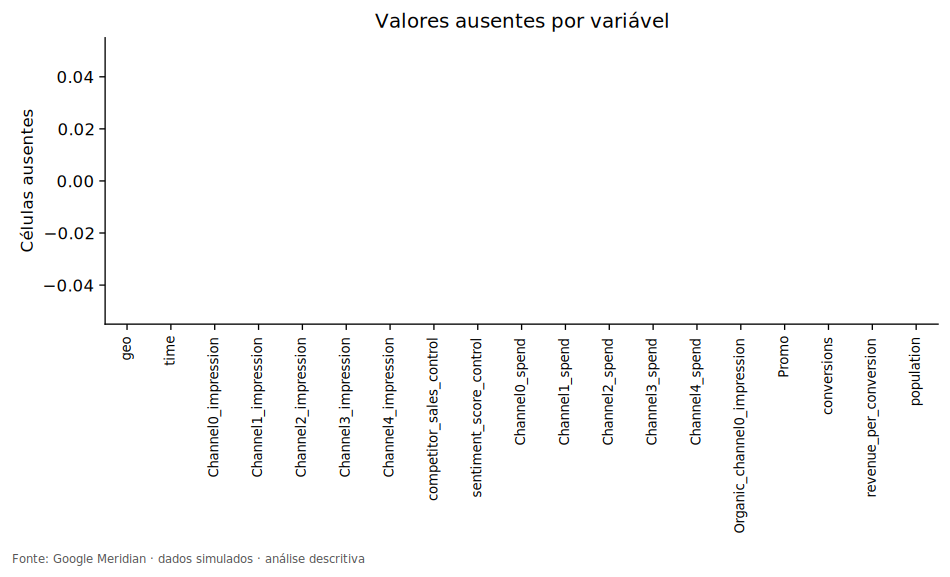

**panel_completeness** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

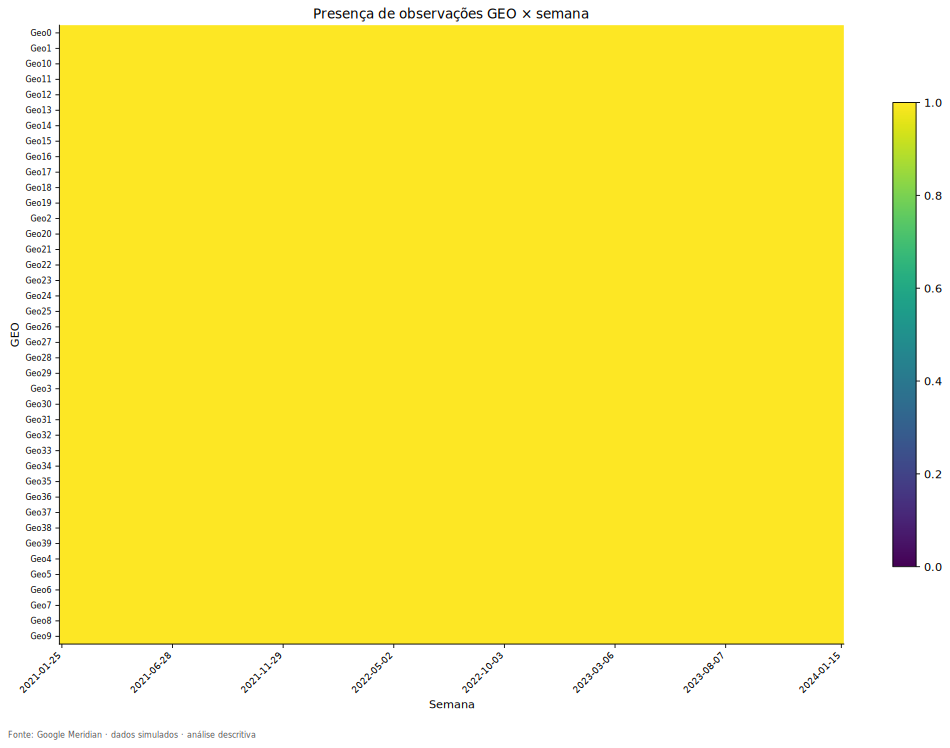

In [ ]:
show(report_00, part="evidence")


---
## Seção executável 01 — Visão geral, extremos e atividade

## Escala e atividade — quanto aparece e por quanto tempo?

Agora que as fichas estão completas, podemos contar o que ocorre nelas. Primeiro somamos o país por semana para conhecer a escala do KPI. Em seguida medimos o peso de cada canal no orçamento, sua presença local e as sequências de zeros. O mesmo percentual de zeros pode esconder pequenas interrupções dispersas ou um longo período sem exposição; por isso calculamos as duas coisas.

Uma marca de outlier é um pedido de investigação, não de exclusão. Confrontamos a escala bruta com a escala por população e com o histórico do próprio mercado. A janela de duas semanas de cada lado ajuda a localizar o caso, sem inventar uma causa comercial.

Para separar liga/desliga de intensidade, usamos a identidade, com $p=P(X>0)$:

$$\operatorname{Var}(X)=p\operatorname{Var}(X\mid X>0)+p(1-p)E(X\mid X>0)^2.$$

O primeiro termo descreve a variação quando há exposição; o segundo, a alternância entre ausência e presença. A decomposição é feita dentro de cada geo e depois somada. Ela não é a decomposição two-way e não estima eficácia.

### Triar extremos sem apagá-los

A regra IQR usa 1,5 vezes a amplitude interquartil. O escore MAD usa a mediana; se MAD for zero, o escore fica indefinido.

Código original de `src/statistics.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def outliers(panel: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    records=[]
    for col in columns:
        x=panel[col]
        q1,q3=x.quantile([.25,.75]); iqr=q3-q1
        median=x.median(); mad=(x-median).abs().median()
        score=.67448975*(x-median)/mad if mad>0 else pd.Series(np.nan,index=x.index)
        flags=(x<q1-1.5*iqr)|(x>q3+1.5*iqr)
        for i in panel.index[flags | (score.abs()>3.5)]:
            records.append(dict(geo=panel.loc[i,'geo'],time=panel.loc[i,'time'],variable=col,
                                value=x.loc[i],iqr_flag=bool(flags.loc[i]),modified_z=score.loc[i],
                                decision='preservar; investigar contexto e escala populacional'))
    return pd.DataFrame(records,columns=['geo','time','variable','value','iqr_flag','modified_z','decision'])


### Abrir os casos e o calendário de atividade

Mantemos as investigações acrescentadas depois da auditoria: escalas alternativas, janelas locais, sequências, suporte e atividade versus intensidade.

Código original de `src/investigation.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def outlier_investigation(p):
    original=read('outliers');groups=[];cases=[];windows=[]
    for col in analytical_columns(p):
        x=p[col];raw=iqr_flags(x);additive=col not in CONTROLS+NON_MEDIA
        scaled=x/p[POP]*1000 if additive else x;normalized=iqr_flags(scaled)
        within=p.groupby(GEO)[col].transform(iqr_flags).astype(bool)
        flagged=original[original.variable==col]
        reason=(f'Promo contínuo: {x.nunique()} valores distintos, {x.eq(0).mean():.1%} zeros; não binário.' if col=='Promo' else
                'Índice sintético centrado; valores negativos admissíveis, sem unidade comercial validada.' if col in CONTROLS else
                f'IQR bruto: {raw.sum()}; per capita: {normalized.sum()}; interseção: {(raw&normalized).sum()}. Escala e cauda devem ser distinguidas.')
        groups.append(dict(variable=col,custom_iqr_or_mad=len(flagged),raw_iqr=raw.sum(),per_capita_iqr=normalized.sum() if additive else np.nan,within_geo_iqr=within.sum(),overlap_raw_normalized=(raw&normalized).sum(),investigation=reason,decision='manter no estudo simulado; domínio válido, sem evidência de corrupção'))
        eligible=pd.MultiIndex.from_frame(p[[GEO,TIME]]).isin(pd.MultiIndex.from_frame(flagged.assign(time=pd.to_datetime(flagged.time))[[GEO,TIME]]))
        selected=(x-x.median()).abs().where(eligible).dropna().nlargest(3).index
        for i in selected:
            r=p.loc[i];g=p[p.geo==r.geo]
            cases.append(dict(variable=col,geo=r.geo,time=r.time,value=x[i],population=r[POP],per_1000=scaled[i] if additive else np.nan,raw_iqr=bool(raw[i]),normalized_iqr=bool(normalized[i]),within_geo_iqr=bool(within[i]),geo_percentile=g[col].rank(pct=True).loc[i],context=reason,decision='preservar: localizado e comparado por escala/geo; sem evidência de erro',limitation='plausibilidade comercial não demonstrada; influência pertence à modelagem'))
            for _,near in g[(g.time-r.time).abs()<=pd.Timedelta(weeks=2)].iterrows():windows.append(dict(variable=col,case_geo=r.geo,case_time=r.time,time=near.time,value=near[col],is_case=near.time==r.time))
    export(pd.DataFrame(windows),'outlier_case_windows')
    coincident=original.groupby([GEO,TIME]).variable.agg(count='size',variables=lambda x:', '.join(sorted(x))).reset_index().sort_values('count',ascending=False)
    export(coincident,'outlier_coincidence')
    return export(pd.DataFrame(groups),'outlier_group_review'),export(pd.DataFrame(cases),'outlier_case_review')

def activity_investigation(p):
    runs=read('activity_runs');rows=[];zeros=[];summaries=[]
    for c in channels(p):
        for geo,g in p.groupby(GEO):
            x=g.sort_values(TIME)[c+'_impression'];positive=x[x>0];prob=x.gt(0).mean();r=runs[(runs.channel==c)&(runs.geo==geo)]
            intensity=prob*positive.var(ddof=0) if len(positive) else 0.;switch=prob*(1-prob)*positive.mean()**2 if len(positive) else 0.
            rows.append(dict(channel=c,geo=geo,active_share=prob,positive_n=len(positive),positive_cv=positive.std(ddof=0)/positive.mean(),unconditional_cv=x.std(ddof=0)/x.mean(),max_zero_streak=r.loc[~r.active,'weeks'].max(),max_active_streak=r.loc[r.active,'weeks'].max(),minimum_active_in_13_weeks=x.gt(0).rolling(13).sum().min(),within_variance=x.var(ddof=0),activity_variance=switch,intensity_variance=intensity))
        total=p.groupby(TIME)[c+'_impression'].sum()
        zeros.extend(dict(channel=c,time=t) for t in total[total.eq(0)].index)
    support=export(pd.DataFrame(rows).fillna({'max_zero_streak':0,'max_active_streak':0}),'activity_support_by_geo')
    for c,g in support.groupby('channel'):
        if not np.allclose(g.within_variance,g.activity_variance+g.intensity_variance):raise ValueError('Identidade atividade/intensidade falhou')
        summaries.append(dict(channel=c,active_share_min=g.active_share.min(),active_share_max=g.active_share.max(),median_positive_cv=g.positive_cv.median(),median_unconditional_cv=g.unconditional_cv.median(),max_zero_streak=g.max_zero_streak.max(),max_active_streak=g.max_active_streak.max(),minimum_active_in_13_weeks=g.minimum_active_in_13_weeks.min(),within_variance_activity_share=g.activity_variance.sum()/g.within_variance.sum(),within_variance_intensity_share=g.intensity_variance.sum()/g.within_variance.sum()))
    return support,export(pd.DataFrame(summaries),'activity_intensity_summary'),export(pd.DataFrame(zeros,columns=['channel','time']),'national_zero_media_weeks')


### Código completo desta etapa

A implementação abaixo foi transportada de `src/eda.py` (`general`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('01')
def general(panel):
    require_valid_panel(panel)
    nat=national(panel)
    desc=table(pd.DataFrame({c:describe(nat[c]) for c in analytical_columns(panel)}).T,'national_descriptive')
    total_spend=panel[[c+'_spend' for c in channels(panel)]].sum().sum()
    summaries=[];activities=[];runs=[]
    for channel in channels(panel):
        media=panel[channel+'_impression'];spend=panel[channel+'_spend']
        active=media>0
        summaries.append(dict(channel=channel,total_media_units=media.sum(),total_spend=spend.sum(),spend_share=spend.sum()/total_spend,
                              active_periods=panel.loc[active,TIME].nunique(),active_geos=panel.loc[active,GEO].nunique(),
                              cpmu=spend.sum()/media.sum() if media.sum()>0 else np.nan,**describe(media)))
        for geo,group in panel.groupby(GEO,sort=True):
            indicator=group[channel+'_impression']>0
            ids=indicator.ne(indicator.shift()).cumsum()
            for _,segment in group.assign(active=indicator,run=ids).groupby('run'):
                runs.append(dict(channel=channel,geo=geo,active=bool(segment.active.iloc[0]),start=segment[TIME].min(),end=segment[TIME].max(),weeks=len(segment)))
        activities.append(dict(channel=channel,active_cells=int(active.sum()),zero_cells=int((~active).sum()),active_share=active.mean(),
                               active_periods=panel.loc[active,TIME].nunique(),active_geos=panel.loc[active,GEO].nunique()))
    summary=table(pd.DataFrame(summaries).set_index('channel'),'channel_summary')
    activity=table(pd.DataFrame(activities).set_index('channel'),'channel_activity')
    run_table=table(pd.DataFrame(runs),'activity_runs',False)
    table(run_table.groupby(['channel','active']).weeks.agg(['count','mean','max']),'activity_streaks')
    extremes=table(outliers(panel,analytical_columns(panel)),'outliers',False)
    table(summary[['total_spend','spend_share']],'spend_share')
    figs=[lines(nat[[KPI]],'general','national_kpi','Conversões nacionais por semana','Conversões sintéticas'),
          bars(summary.spend_share.sort_values(ascending=False),'general','spend_share','Participação no investimento total','Fração do gasto'),
          bars(activity.active_share,'general','channel_activity','Atividade dos canais no painel','Fração de células com mídia > 0')]
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    axes[0].hist(nat[KPI],bins=20,color='#245b78');axes[0].set(xlabel='Conversões nacionais/semana',ylabel='Semanas',title='Distribuição nacional do KPI')
    axes[1].boxplot(nat[KPI]);axes[1].set(ylabel='Conversões nacionais/semana',title='Boxplot do KPI')
    figs.append(save(fig,'general','kpi_distribution'))
    text=f'''O KPI nacional tem média semanal de {nat[KPI].mean():,.0f} conversões sintéticas e CV de {desc.loc[KPI,'cv']:.1%}. O agregado nacional soma conversões entre geos; não soma taxas.

O maior share de gasto é de {summary.spend_share.idxmax()} ({summary.spend_share.max():.1%}). Share mede alocação, não retorno. A atividade varia de {activity.active_share.min():.1%} a {activity.active_share.max():.1%} das células GEO × semana. Exportamos todas as sequências de atividade e zeros, sem classificar com limiares arbitrários.

Foram sinalizados {len(extremes)} pares observação/variável por IQR (1,5×) ou MAD (|z modificado|>3,5). São regras de triagem, não critérios de remoção. Séries esparsas e geos grandes podem ser sinalizados legitimamente. Quando MAD é zero o escore fica indefinido. Nenhum extremo foi removido.'''
    return result('01_eda_general',text,{'national_descriptive':desc,'channel_summary':summary,'activity':activity},figs,'Dinâmica temporal dos sinais e seus controles.')


In [ ]:
report_01 = general(geo_time_panel)
show(report_01, part="summary")


### Resultado observado e conclusão parcial

O KPI nacional tem média semanal de 422,632,783 conversões sintéticas e CV de 6.9%. O agregado nacional soma conversões entre geos; não soma taxas.

O maior share de gasto é de Channel3 (40.0%). Share mede alocação, não retorno. A atividade varia de 35.7% a 97.3% das células GEO × semana. Exportamos todas as sequências de atividade e zeros, sem classificar com limiares arbitrários.

Foram sinalizados 6039 pares observação/variável por IQR (1,5×) ou MAD (|z modificado|>3,5). São regras de triagem, não critérios de remoção. Séries esparsas e geos grandes podem ser sinalizados legitimamente. Quando MAD é zero o escore fica indefinido. Nenhum extremo foi removido.

**Channel2 versus Channel3:** atividade por geo entre 28.2% e 44.2%; maior sequência de zeros 27 semanas. Channel3 tem sequência ativa máxima de 127 semanas. Zeros nacionais de Channel2: 2021-04-26, 2022-07-25, 2023-05-15, 2023-06-19.

**Atividade e intensidade:** Var(X)=p Var(X|X>0)+p(1−p)E(X|X>0)². A alternância zero/positivo corresponde a 50.5% da variância within em Channel2, contra 10.5% em Channel3. CV mediano de Channel2: 1.88 geral e 0.81 entre valores positivos. Essa identidade não decompõe o resíduo two-way nem estima eficácia.

**Extremos:** 6039 pares triados; até três casos por variável com comparação bruto/per capita/dentro do geo e janelas de ±2 semanas. Promo é contínuo com massa em zero, não binário. Os grupos e as justificativas estão nas tabelas; dados simulados são preservados, sem validação comercial presumida.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Channel2 versus Channel3:** atividade por geo entre 28.2% e 44.2%; maior sequência de zeros 27 semanas. Channel3 tem sequência ativa máxima de 127 semanas. Zeros nacionais de Channel2: 2021-04-26, 2022-07-25, 2023-05-15, 2023-06-19.
- **Quais problemas apareceram?** Sparsity limita suporte em janelas específicas; não inventar calendário de campanhas.
- **O que falta investigar?** Dinâmica temporal dos sinais e seus controles.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

**national_descriptive** — 15 linhas; CSV completo em `outputs/tables/`.

,n,mean,median,std,variance,min,max,p01,p05,p25,p50,p75,p95,p99,iqr,cv,zeros,zero_share,cv_interpretation
conversions,156.0,4.226328e+08,4.227034e+08,2.911830e+07,8.478753e+14,3.402833e+08,4.912874e+08,3.553039e+08,3.736850e+08,4.053507e+08,4.227034e+08,4.404787e+08,4.687004e+08,4.888518e+08,3.512797e+07,0.068897,0.0,0.000000,razão descritiva; verificar domínio
Channel0_impression,156.0,3.540654e+07,3.496160e+07,1.210007e+07,1.464118e+14,7.851189e+06,6.386554e+07,1.015168e+07,1.569336e+07,2.704481e+07,3.496160e+07,4.495542e+07,5.706419e+07,6.225383e+07,1.791061e+07,0.341747,0.0,0.000000,razão descritiva; verificar domínio
Channel1_impression,156.0,2.082422e+07,1.937102e+07,1.017229e+07,1.034756e+14,2.729719e+06,5.236681e+07,4.864523e+06,7.073937e+06,1.340884e+07,1.937102e+07,2.684337e+07,4.052737e+07,5.030103e+07,1.343453e+07,0.488484,0.0,0.000000,razão descritiva; verificar domínio
Channel2_impression,156.0,1.042020e+07,8.122188e+06,9.076909e+06,8.239028e+13,0.000000e+00,4.608557e+07,0.000000e+00,6.173670e+05,3.297471e+06,8.122188e+06,1.566935e+07,2.866586e+07,3.890450e+07,1.237188e+07,0.871088,4.0,0.025641,razão descritiva; verificar domínio
Channel3_impression,156.0,7.227242e+07,7.085189e+07,2.220926e+07,4.932513e+14,1.796734e+07,1.402645e+08,2.699388e+07,4.020701e+07,5.635578e+07,7.085189e+07,8.414181e+07,1.085364e+08,1.272496e+08,2.778603e+07,0.307299,0.0,0.000000,razão descritiva; verificar domínio
Channel4_impression,156.0,3.926712e+07,3.773983e+07,1.596923e+07,2.550163e+14,6.971125e+06,8.370790e+07,8.949558e+06,1.448040e+07,2.745158e+07,3.773983e+07,4.983927e+07,6.684530e+07,7.740700e+07,2.238769e+07,0.406682,0.0,0.000000,razão descritiva; verificar domínio
Channel0_spend,156.0,2.596264e+05,2.563638e+05,8.872649e+04,7.872390e+09,5.757060e+04,4.683083e+05,7.443948e+04,1.150750e+05,1.983121e+05,2.563638e+05,3.296456e+05,4.184359e+05,4.564901e+05,1.313335e+05,0.341747,0.0,0.000000,razão descritiva; verificar domínio
Channel1_spend,156.0,2.007711e+05,1.867605e+05,9.807345e+04,9.618401e+09,2.631785e+04,5.048806e+05,4.690000e+04,6.820147e+04,1.292777e+05,1.867605e+05,2.588031e+05,3.907338e+05,4.849639e+05,1.295254e+05,0.488484,0.0,0.000000,razão descritiva; verificar domínio
Channel2_spend,156.0,7.743173e+04,6.035536e+04,6.744983e+04,4.549479e+09,0.000000e+00,3.424584e+05,0.000000e+00,4.587608e+03,2.450326e+04,6.035536e+04,1.164378e+05,2.130138e+05,2.890964e+05,9.193452e+04,0.871088,4.0,0.025641,razão descritiva; verificar domínio
Channel3_spend,156.0,5.632074e+05,5.521375e+05,1.730732e+05,2.995434e+10,1.400167e+05,1.093059e+06,2.103590e+05,3.133268e+05,4.391716e+05,5.521375e+05,6.557037e+05,8.458071e+05,9.916360e+05,2.165321e+05,0.307299,0.0,0.000000,razão descritiva; verificar domínio


**channel_summary** — 5 linhas; CSV completo em `outputs/tables/`.

,total_media_units,total_spend,spend_share,active_periods,active_geos,cpmu,n,mean,median,std,variance,min,max,p01,p05,p25,p50,p75,p95,p99,iqr,cv,zeros,zero_share,cv_interpretation
channel,,,,,,,,,,,,,,,,,,,,,,,,,
Channel0,5523420467,4.050171e+07,0.184524,156,40,0.007333,6240,8.851635e+05,679670.5,8.192795e+05,6.712189e+11,0,5192032,0.0,0.0,253645.75,679670.5,1324174.25,2527659.25,3458103.74,1070528.50,0.925569,755,0.120994,razão descritiva; verificar domínio
Channel1,3248578573,3.132030e+07,0.142694,156,40,0.009641,6240,5.206055e+05,310652.5,6.205734e+05,3.851114e+11,0,4397540,0.0,0.0,0.00,310652.5,807552.50,1825045.65,2604638.15,807552.50,1.192022,1742,0.279167,razão descritiva; verificar domínio
Channel2,1625551369,1.207935e+07,0.055033,152,40,0.007431,6240,2.605050e+05,0.0,5.551397e+05,3.081801e+11,0,5610156,0.0,0.0,0.00,0.0,254734.00,1425716.35,2614612.82,254734.00,2.131013,4010,0.642628,razão descritiva; verificar domínio
Channel3,11274497204,8.786036e+07,0.400289,156,40,0.007793,6240,1.806810e+06,1505379.0,1.304714e+06,1.702277e+12,0,7635147,0.0,168567.8,808356.50,1505379.0,2566118.25,4282815.55,5741464.61,1757761.75,0.722109,169,0.027083,razão descritiva; verificar domínio
Channel4,6125670562,4.773068e+07,0.217459,156,40,0.007792,6240,9.816780e+05,746247.5,9.141036e+05,8.355853e+11,0,6975542,0.0,0.0,267594.50,746247.5,1476707.75,2788040.00,3776701.79,1209113.25,0.931164,820,0.131410,razão descritiva; verificar domínio


**activity** — 5 linhas; CSV completo em `outputs/tables/`.

...

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

**channel_activity** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

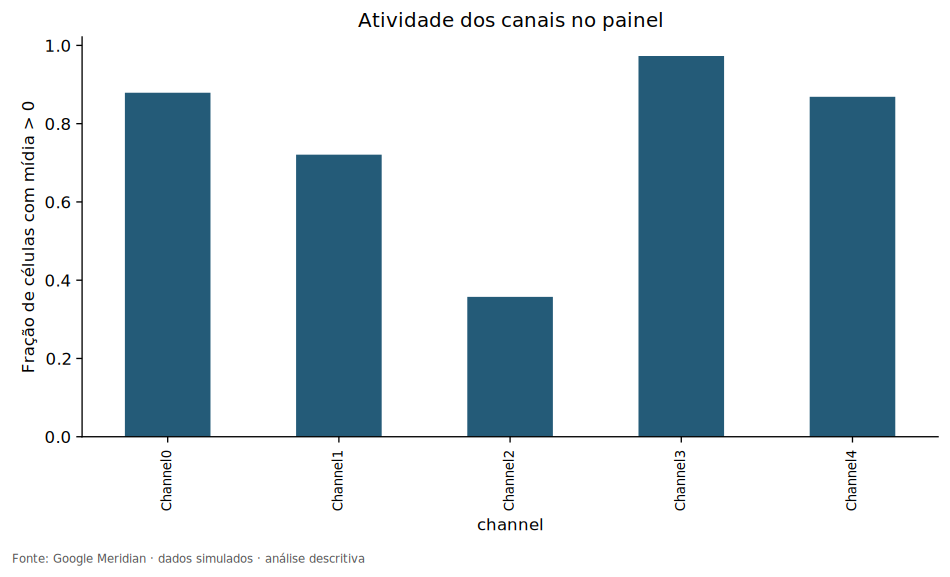

**kpi_distribution** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

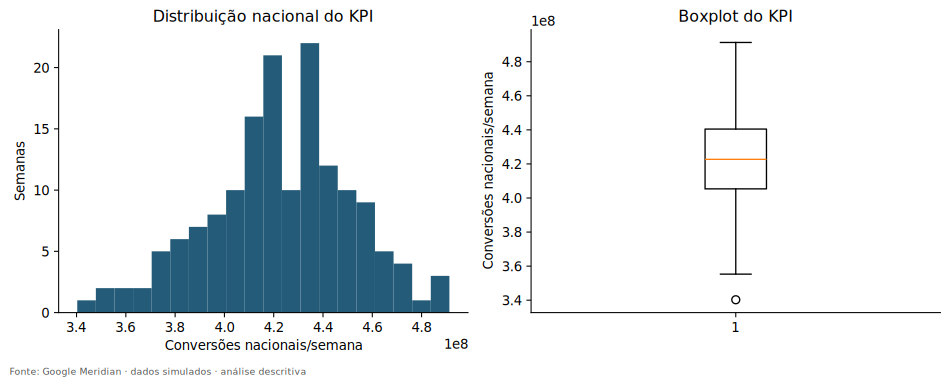

**national_kpi** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

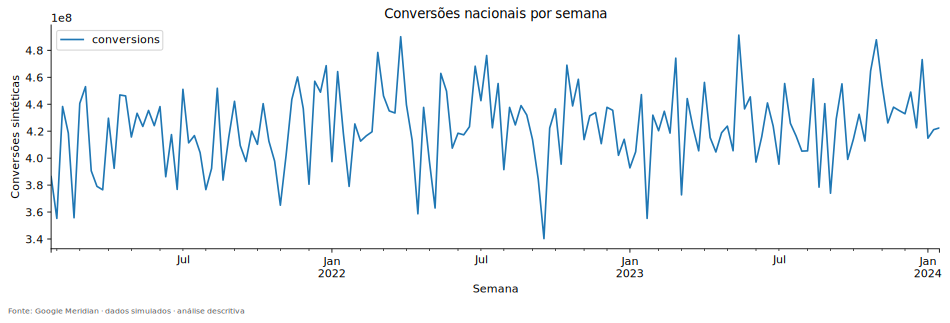

**spend_share** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

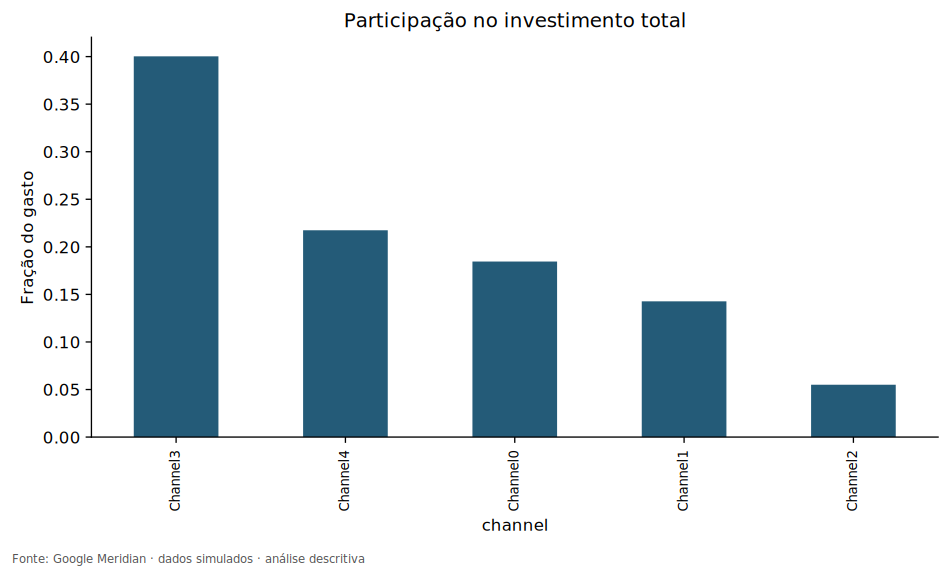

In [ ]:
show(report_01, part="evidence")


---
## Seção executável 02 — Tempo

## Capítulo 4 — A primeira linha no tempo

Ao somar as conversões dos 40 mercados em cada semana, passamos de milhares de fichas a uma sequência de 156 resultados nacionais. O eixo horizontal do gráfico acompanha as semanas; a altura da linha mostra quantas conversões simuladas foram registradas no conjunto dos mercados. Pela primeira vez, podemos enxergar o ritmo do todo. A marca `1e8` no eixo apenas abrevia a escala: o número 4 corresponde a 400 milhões de conversões.

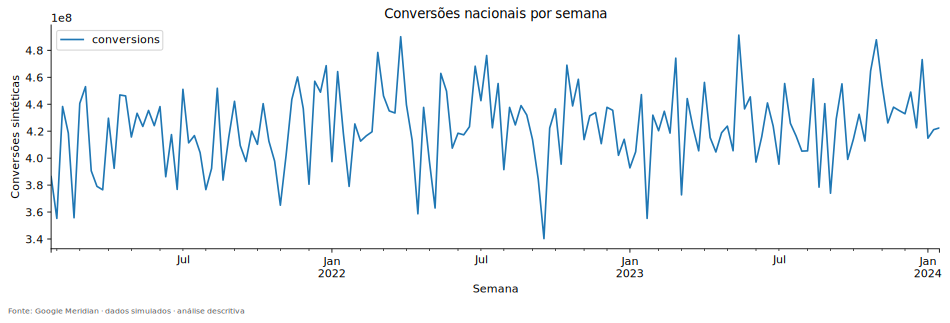

O resultado se move em torno de **423 milhões de conversões por semana**. Essa escala é uma característica da simulação, não uma estimativa de vendas de uma empresa conhecida. O menor valor está perto de 340 milhões e o maior, de 491 milhões. Há movimento suficiente para que uma semana não seja uma simples repetição da outra, mas a sequência também não conta uma história de crescimento contínuo e acentuado.

A linha ajuda a localizar acontecimentos no tempo. Para entender o que é habitual, podemos fazer outra pergunta: se juntássemos semanas de resultados semelhantes, em quais faixas haveria mais semanas? No gráfico seguinte, as barras à esquerda fazem esse agrupamento. À direita, uma caixa resume a região central, com uma linha indicando a mediana, o ponto que divide as semanas em duas metades.

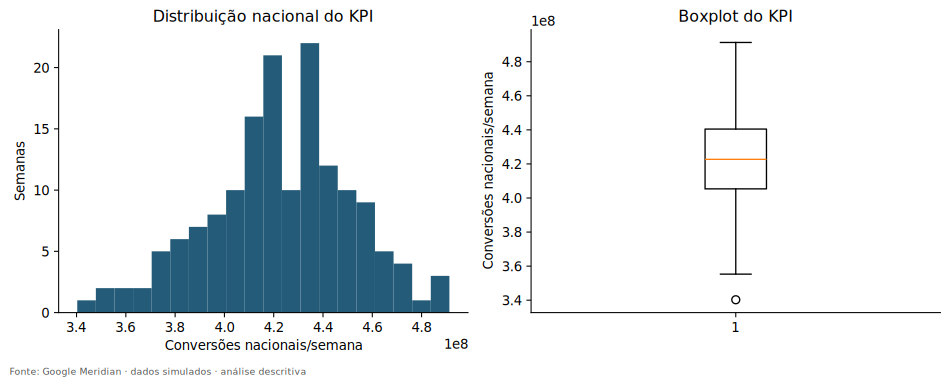

A metade central das semanas fica aproximadamente entre **405 e 440 milhões**. A proximidade entre média e mediana confirma que o centro está perto de 423 milhões, sem exigir que a distribuição seja perfeitamente simétrica. O ponto baixo destacado pelo boxplot chama atenção porque está distante desse miolo.

Um ponto distante dos demais recebe frequentemente o nome de **outlier**. Isso é uma descrição de raridade em relação a uma referência, não uma sentença de erro. A semana de 19 de setembro de 2022, que reaparecerá na revisão oficial, não deve ser apagada apenas por ser baixa. Precisamos saber qual regra a destacou, em qual escala e se existe evidência de corrupção do registro.

A série também tem oscilações rápidas que dificultam perceber mudanças lentas. O projeto calculou uma média das 13 semanas mais recentes para suavizar esse movimento. Ela usa o passado disponível, sem antecipar semanas futuras. Depois, separou uma trajetória lenta, um desenho que pode se repetir aproximadamente a cada ano e o que resta dessa separação. Essa decomposição recebe o nome de **STL**.

No próximo gráfico, os painéis mostram a série observada e essas três partes. A trajetória lenta aparece separada justamente para não confundir uma oscilação semanal com crescimento sustentado. A parte sazonal procura repetição aproximada a cada 52 semanas; o último painel guarda o que a divisão não acomodou.

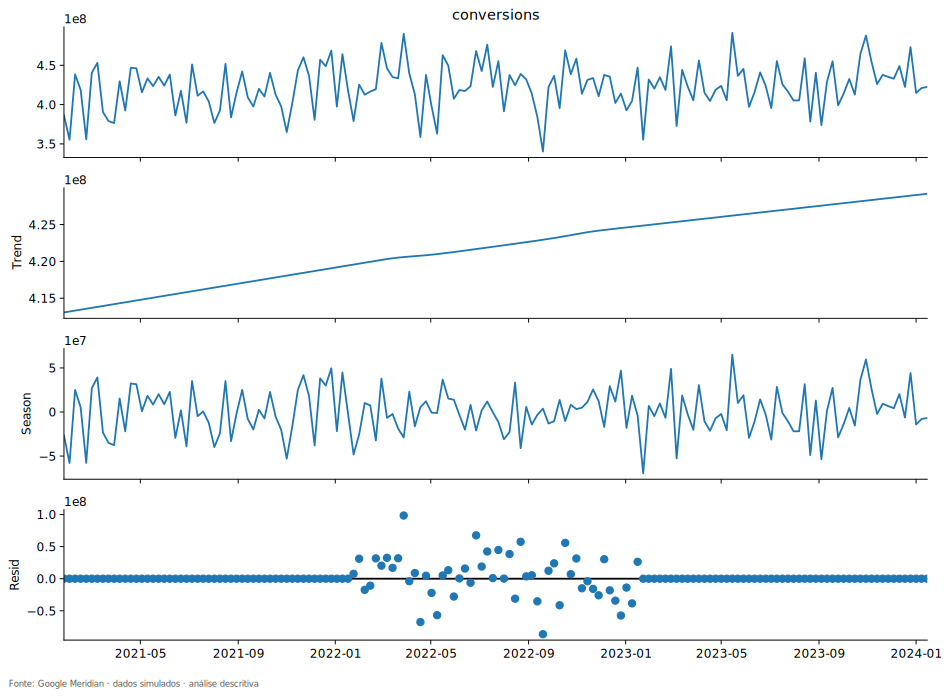

A trajetória lenta termina cerca de **3,9%** acima de onde começou. Isso descreve os extremos da curva suavizada, não a diferença entre a primeira e a última semana observadas. As medidas auxiliares da decomposição dão mais destaque ao componente sazonal que à tendência. Há, porém, somente cerca de três ciclos anuais, e um calendário civil não cabe exatamente em blocos de 52 semanas. Não podemos transformar esse desenho em uma história comprovada de festas, promoções ou hábitos de consumo.

Outra maneira de procurar repetição é comparar a série consigo mesma, deslocada no tempo. Essa semelhança recebe o nome de **autocorrelação**. A comparação com uma semana antes está perto de zero; com 52 semanas antes, também é pequena, cerca de 0,03. Isso recomenda prudência antes de declarar uma repetição anual forte. Não contradiz automaticamente a STL: separar uma curva periódica e medir uma semelhança linear em uma distância específica são operações diferentes.

A [síntese temporal](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/temporal_interpretation.csv) registra esses resultados, inclusive a maior mudança entre semanas consecutivas: uma queda próxima de 101 milhões em 6 de março de 2023. Não conhecemos sua causa empresarial. Temos uma localização que pode ser investigada, não uma campanha que possamos narrar.

Aprendemos que existe movimento nacional e que ele não se resume a uma tendência simples. Mas a soma eliminou os endereços. Para descobrir como esse movimento se distribui, precisamos recuperá-los.

### Como traduzimos o tempo em operações

A média móvel usa somente as 13 semanas anteriores, incluindo a atual. A STL é uma decomposição exploratória da série completa, não um filtro projetado para prever sem olhar o futuro. Essa diferença importa para a futura validação: o desenho do holdout ainda não foi feito. A ACF compara a série com versões defasadas dela; poucas repetições anuais impedem transformar um desenho visual em calendário comercial comprovado.

### Ler a STL em contexto

As forças de tendência e sazonalidade são resumos descritivos separados, não parcelas aditivas nem testes de significância.

Código original de `src/investigation.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def temporal_investigation(p):
    stl=read('kpi_stl_52');acf=read('kpi_acf').set_index('lag').acf;change=read('kpi_level_changes').iloc[0];v=stl.residuo.var(ddof=0)
    summary=export(pd.DataFrame([dict(first_trend=stl.tendencia.iloc[0],last_trend=stl.tendencia.iloc[-1],trend_change_percent=100*(stl.tendencia.iloc[-1]/stl.tendencia.iloc[0]-1),seasonal_strength=max(0,1-v/(stl.residuo+stl.sazonal).var(ddof=0)),trend_strength=max(0,1-v/(stl.residuo+stl.tendencia).var(ddof=0)),acf_lag1=acf.loc[1],acf_lag13=acf.loc[13],acf_lag52=acf.loc[52],largest_weekly_change_date=change.time,largest_weekly_change=change.difference)]),'temporal_interpretation')
    rows=[]
    for col in CONTROLS+NON_MEDIA:
        x=p[col];d=national(p)[col].diff();date=d.abs().idxmax()
        rows.append(dict(variable=col,min=x.min(),max=x.max(),std=x.std(ddof=0),distinct=x.nunique(),zero_share=x.eq(0).mean(),std_over_range=x.std(ddof=0)/(x.max()-x.min()),largest_national_change_date=date,largest_national_change=d.loc[date],cv_interpretation='não usar em índice centrado/zero-inflado'))
    return summary,export(pd.DataFrame(rows),'control_detailed_profile')


### Código completo desta etapa

A implementação abaixo foi transportada de `src/eda.py` (`temporal`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('02')
def temporal(panel):
    from statsmodels.tsa.seasonal import STL
    from statsmodels.tsa.stattools import acf
    nat=national(panel);table(nat,'national_timeseries')
    figs=[]
    smooth=nat[[KPI]].assign(media_movel_13_semanas=nat[KPI].rolling(13,min_periods=13).mean())
    figs.append(lines(smooth,'temporal','kpi_trend','KPI e média móvel retrospectiva (13 semanas)','Conversões sintéticas'))
    stl=STL(nat[KPI],period=52,robust=True).fit()
    stl_frame=pd.DataFrame({'observado':nat[KPI],'tendencia':stl.trend,'sazonal':stl.seasonal,'residuo':stl.resid},index=nat.index)
    table(stl_frame,'kpi_stl_52')
    fig=stl.plot();fig.set_size_inches(11,8);figs.append(save(fig,'temporal','kpi_stl_52'))
    changes=nat[[KPI]].assign(difference=nat[KPI].diff(),pct_change=nat[KPI].pct_change())
    table(changes.reindex(changes.difference.abs().sort_values(ascending=False).index),'kpi_level_changes')
    table(pd.DataFrame({'lag':np.arange(53),'acf':acf(nat[KPI],nlags=52)}),'kpi_acf',False)
    cost_rows=[]
    for channel in channels(panel):
        media=nat[channel+'_impression'];spend=nat[channel+'_spend'];cost=safe_divide(spend,media)
        fig,axes=plt.subplots(3,1,figsize=(11,7),sharex=True)
        for ax,series,label in zip(axes,[media,spend,cost],['Impressões','Gasto (moeda não especificada)','Gasto / impressão']):
            ax.plot(series.index,series);ax.set_ylabel(label)
        axes[2].set_ylim(0,cost.max()*1.08);axes[2].ticklabel_format(axis='y',style='plain',useOffset=False)
        axes[2].text(.01,.78,f'CV relativo={cost.std(ddof=0)/cost.mean():.2e}; variação microscópica',transform=axes[2].transAxes,fontsize=8)
        axes[0].set_title(f'{channel}: volumes, gasto e CPMU nacionais');axes[-1].set_xlabel('Semana')
        figs.append(save(fig,'temporal',channel+'_timeseries'))
        z=nat[[KPI,channel+'_impression']].apply(lambda x:(x-x.mean())/x.std(ddof=0))
        figs.append(lines(z,'temporal',channel+'_kpi_z',f'{channel} × KPI: co-movimento descritivo','Desvios padrão da própria série'))
        cost_rows.append(cost.rename(channel))
    table(pd.concat(cost_rows,axis=1),'national_cpmu')
    control_stats=[]
    for col in CONTROLS+NON_MEDIA+ORGANIC:
        figs.append(lines(nat[[col]],'temporal',col+'_time',f'{col}: trajetória nacional', 'Impressões' if col in ORGANIC else 'Média ponderada por população'))
        fig,ax=plt.subplots(figsize=(7,4));ax.hist(panel[col],bins=25);ax.set(title=f'{col}: distribuição GEO × semana',xlabel='Valor na escala fornecida',ylabel='Observações')
        figs.append(save(fig,'temporal',col+'_distribution'))
        control_stats.append(dict(variable=col,unique=panel[col].nunique(),range=panel[col].max()-panel[col].min(),**describe(panel[col])))
    control_stats=table(pd.DataFrame(control_stats),'control_temporal_summary',False)
    peak=nat[KPI].idxmax(); low=nat[KPI].idxmin()
    text=f'''O máximo nacional ocorre em {peak.date()} ({nat.loc[peak,KPI]:,.0f}) e o mínimo em {low.date()} ({nat.loc[low,KPI]:,.0f}). A média móvel de 13 semanas suaviza a série sem antecipar valores futuros; é apenas visual.

A decomposição STL usa período 52 como aproximação anual para dados semanais. Há apenas {len(nat)/52:.1f} ciclos: tendência, sazonalidade e mudanças de nível não são evidência confirmatória de mecanismos de negócio. Nenhum teste formal de quebra foi feito. As maiores mudanças e a ACF foram exportadas.

Todos os canais têm gráficos separados de impressões, gasto, CPMU e comparação padronizada com KPI. Controles e Promo são agregados por média ponderada por população porque somar índices sintéticos não tem interpretação. A mídia orgânica é somada. Existem {int((control_stats['std']==0).sum())} variáveis constantes entre os controles/tratamentos apresentados. Valores próximos de constantes devem ser avaliados na sua escala, sem corte universal.'''
    return result('02_eda_temporal',text,{'control_temporal_summary':control_stats,'national_timeseries':nat},figs,'Heterogeneidade entre geos e decomposição within/between.')


In [ ]:
report_02 = temporal(geo_time_panel)
show(report_02, part="summary")


### Resultado observado e conclusão parcial

O máximo nacional ocorre em 2023-05-15 (491,287,369) e o mínimo em 2022-09-19 (340,283,293). A média móvel de 13 semanas suaviza a série sem antecipar valores futuros; é apenas visual.

A decomposição STL usa período 52 como aproximação anual para dados semanais. Há apenas 3.0 ciclos: tendência, sazonalidade e mudanças de nível não são evidência confirmatória de mecanismos de negócio. Nenhum teste formal de quebra foi feito. As maiores mudanças e a ACF foram exportadas.

Todos os canais têm gráficos separados de impressões, gasto, CPMU e comparação padronizada com KPI. Controles e Promo são agregados por média ponderada por população porque somar índices sintéticos não tem interpretação. A mídia orgânica é somada. Existem 0 variáveis constantes entre os controles/tratamentos apresentados. Valores próximos de constantes devem ser avaliados na sua escala, sem corte universal.

**Trajetória:** tendência STL de 413,074,059 a 429,184,890 (+3.90%). Maior mudança semanal em 2023-03-06: -101,396,624. ACF nos lags 1/13/52: 0.008/0.090/0.032. Forças descritivas sazonal/tendência: 0.503/0.034, calculadas por 1−Var(resíduo)/Var(componente+resíduo), truncadas em zero; não são parcelas aditivas ou testes.

competitor_sales_control: amplitude [-4.826,3.925], desvio 1.210, 6240 valores distintos; maior mudança nacional ponderada em 2022-05-16 (-2.382). Não é quase constante na escala observada; CV não é interpretável.

sentiment_score_control: amplitude [-4.230,4.320], desvio 1.175, 6239 valores distintos; maior mudança nacional ponderada em 2021-12-13 (+2.357). Não é quase constante na escala observada; CV não é interpretável.

Promo: amplitude [0.000,4.801], desvio 0.694, 3319 valores distintos; maior mudança nacional ponderada em 2023-08-21 (-1.133). Não é quase constante na escala observada; CV não é interpretável.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Trajetória:** tendência STL de 413,074,059 a 429,184,890 (+3.90%). Maior mudança semanal em 2023-03-06: -101,396,624. ACF nos lags 1/13/52: 0.008/0.090/0.032. Forças descritivas sazonal/tendência: 0.503/0.034, calculadas por 1−Var(resíduo)/Var(componente+resíduo), truncadas em zero; não são parcelas aditivas ou testes.
- **Quais problemas apareceram?** Somente três ciclos; STL/ACF não confirmam sazonalidade de negócio nem quebras causais.
- **O que falta investigar?** Heterogeneidade entre geos e decomposição within/between.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

**control_temporal_summary** — 4 linhas; CSV completo em `outputs/tables/`.

,variable,unique,range,n,mean,median,std,variance,min,max,p01,p05,p25,p50,p75,p95,p99,iqr,cv,zeros,zero_share,cv_interpretation
0,competitor_sales_control,6240,8.750317e+00,6240,-0.044412,-0.050346,1.210067,1.464262e+00,-4.825634,3.924682e+00,-2.819445,-1.995962,-0.872736,-0.050346,0.743633,1.987068e+00,2.869632e+00,1.616369,NaN,0,0.000000,não interpretável: índice centrado/tratamento ...
1,sentiment_score_control,6239,8.550651e+00,6240,-0.033675,-0.036433,1.175478,1.381749e+00,-4.230392,4.320259e+00,-2.818955,-1.940917,-0.808085,-0.036433,0.739391,1.891985e+00,2.756426e+00,1.547475,NaN,0,0.000000,não interpretável: índice centrado/tratamento ...
2,Promo,3319,4.800555e+00,6240,0.492528,0.084382,0.694224,4.819467e-01,0.000000,4.800555e+00,0.000000,0.000000,0.000000,0.084382,0.832968,1.962645e+00,2.697505e+00,0.832968,NaN,2922,0.468269,não interpretável: índice centrado/tratamento ...
3,Organic_channel0_impression,4164,5.801781e+06,6240,532466.670513,269958.000000,696134.901248,4.846038e+11,0.000000,5.801781e+06,0.000000,0.000000,0.000000,269958.000000,799699.250000,1.971783e+06,3.005490e+06,799699.250000,1.307377,2075,0.332532,razão descritiva; verificar domínio


**national_timeseries** — 156 linhas; CSV completo em `outputs/tables/`.

Amostra das primeiras 12 linhas; sínteses selecionadas abaixo e CSV integral disponível.

,conversions,Channel0_impression,Channel1_impression,Channel2_impression,Channel3_impression,Channel4_impression,Channel0_spend,Channel1_spend,Channel2_spend,Channel3_spend,Channel4_spend,Organic_channel0_impression,competitor_sales_control,sentiment_score_control,Promo,revenue_derived,revenue_per_conversion,population
time,,,,,,,,,,,,,,,,,,
2021-01-25,3.863009e+08,44340630,10537596,6501889,66738506,53026011,325137.568300,101595.404270,48315.045180,520082.52420,413173.984050,24028870,-0.032438,-0.342020,0.272211,7.731975e+06,0.020015,21696753.31
2021-02-01,3.553039e+08,47391940,30857600,7966320,79000018,27592214,347511.968090,297505.263890,59197.121480,615634.54030,214996.093200,29188267,0.312002,0.807150,0.151264,7.104532e+06,0.019996,21696753.31
2021-02-08,4.383089e+08,28960185,23144749,4637739,68442555,20057461,212357.019450,223143.885196,34462.687700,533361.91650,156285.964472,12051369,-1.243697,-0.152005,0.596395,8.762589e+06,0.019992,21696753.31
2021-02-15,4.186124e+08,38126016,10667077,3029637,70601091,37246623,279567.522900,102843.758830,22513.003350,550183.03800,290222.395240,9595212,-0.019225,-0.377523,0.341224,8.363356e+06,0.019979,21696753.31
2021-02-22,3.557853e+08,46890794,17925961,10486840,81842660,56259530,343837.209200,172828.342330,77926.915300,637786.80240,438369.280950,9288846,0.344244,0.034181,0.366063,7.109799e+06,0.019983,21696753.31
2021-03-01,4.406152e+08,31496378,19099596,3713252,58861970,26886668,230954.220330,184143.627600,27592.895000,458701.94280,209498.541240,13711117,-0.691891,-0.554818,0.371434,8.813679e+06,0.020003,21696753.31
2021-03-08,4.530552e+08,25772939,4734654,7271164,68725846,37615253,188985.826030,45647.895670,54031.470175,535569.55042,293094.728570,13763654,-0.848894,-0.373470,0.091544,9.050774e+06,0.019977,21696753.31
2021-03-15,3.905958e+08,35435485,17853348,8084840,73628817,40915556,259838.598400,172128.262440,60077.836005,573777.62510,318810.394260,17933987,0.454243,0.151022,0.012450,7.804657e+06,0.019981,21696753.31
2021-03-22,3.790501e+08,28273144,27489089,6237490,64406105,56582012,207319.137090,265028.672380,46350.316360,501906.50854,440882.035900,31799726,0.560951,-1.544945,0.928034,7.584097e+06,0.020008,21696753.31


...

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

**Channel0_kpi_z** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

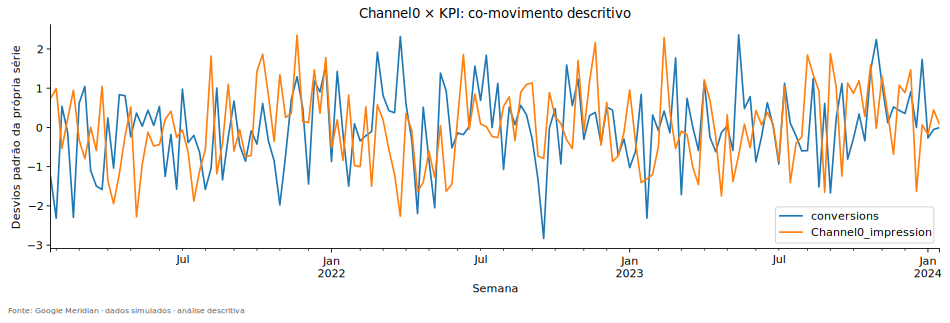

**Channel0_timeseries** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

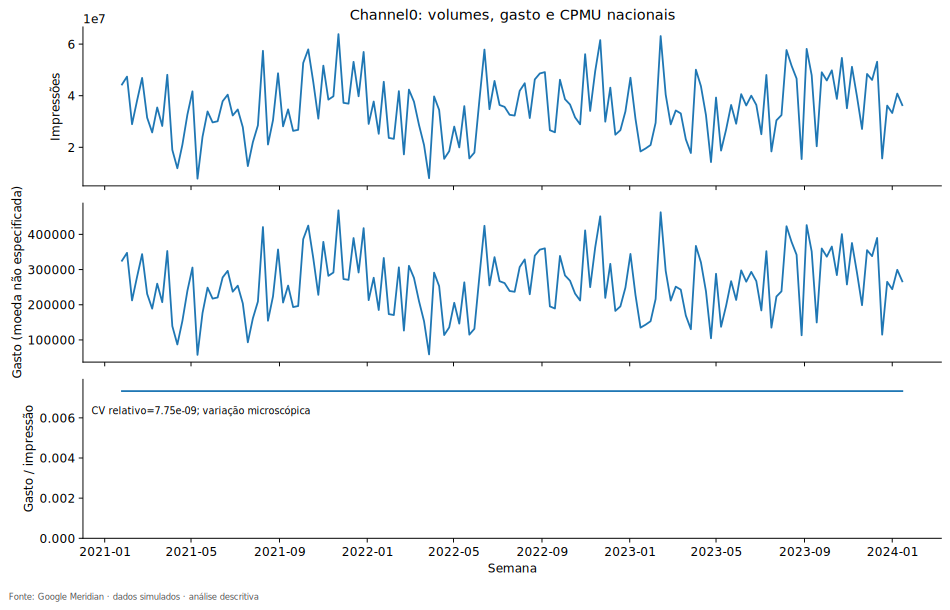

**Channel1_kpi_z** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

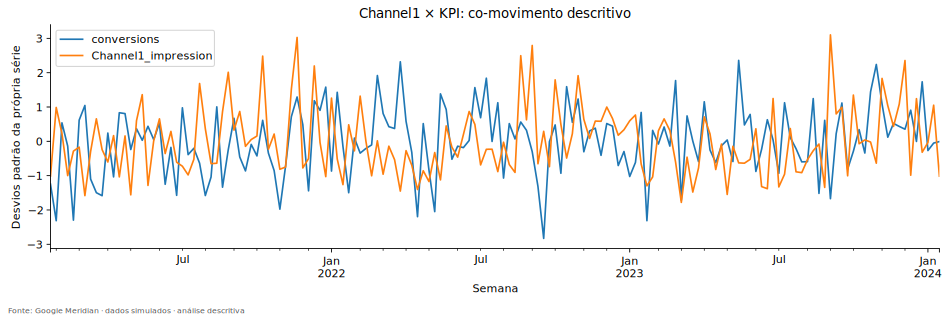

**Channel1_timeseries** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

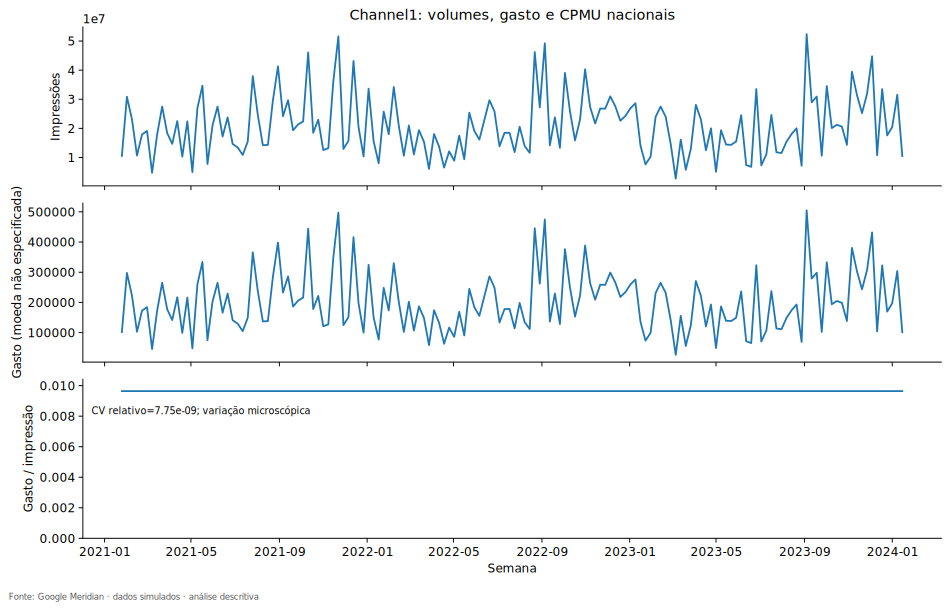

**Channel2_kpi_z** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

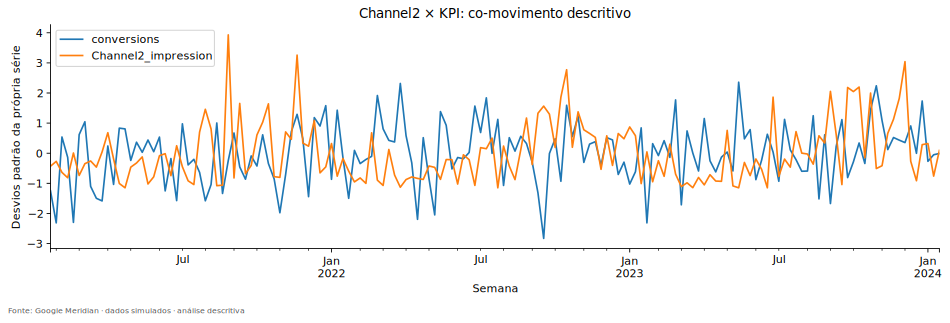

**Channel2_timeseries** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

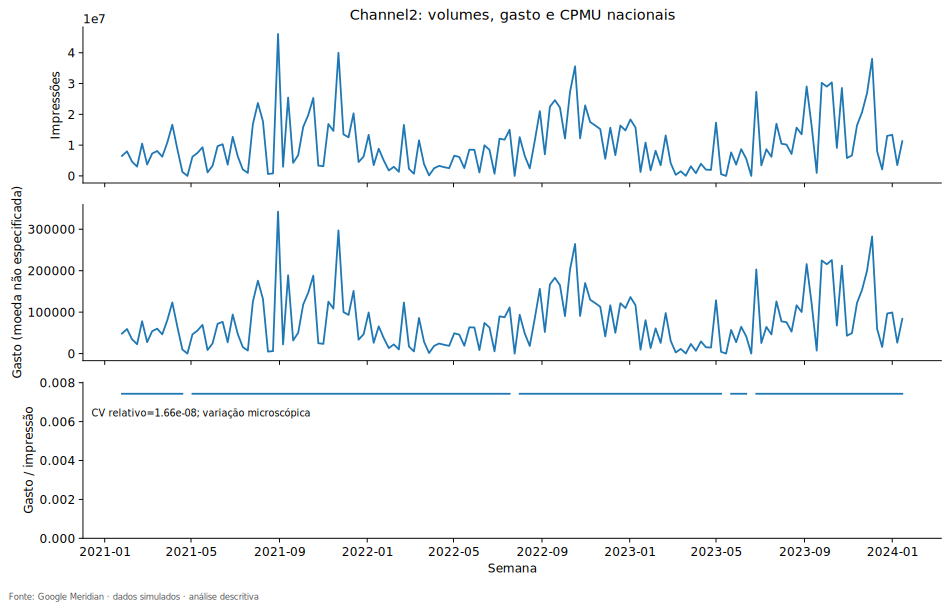

**Channel3_kpi_z** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

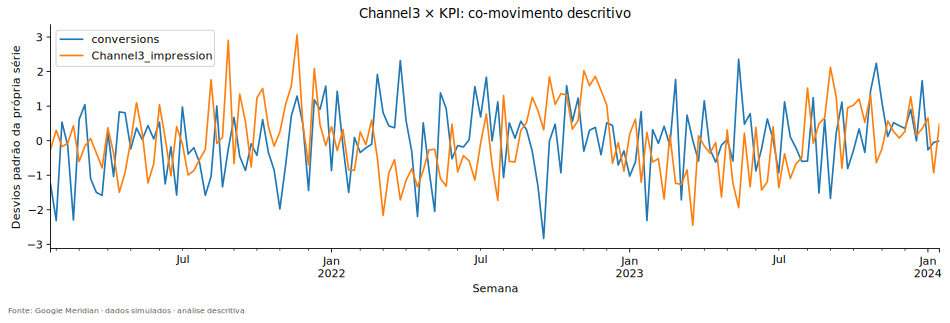

**Channel3_timeseries** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

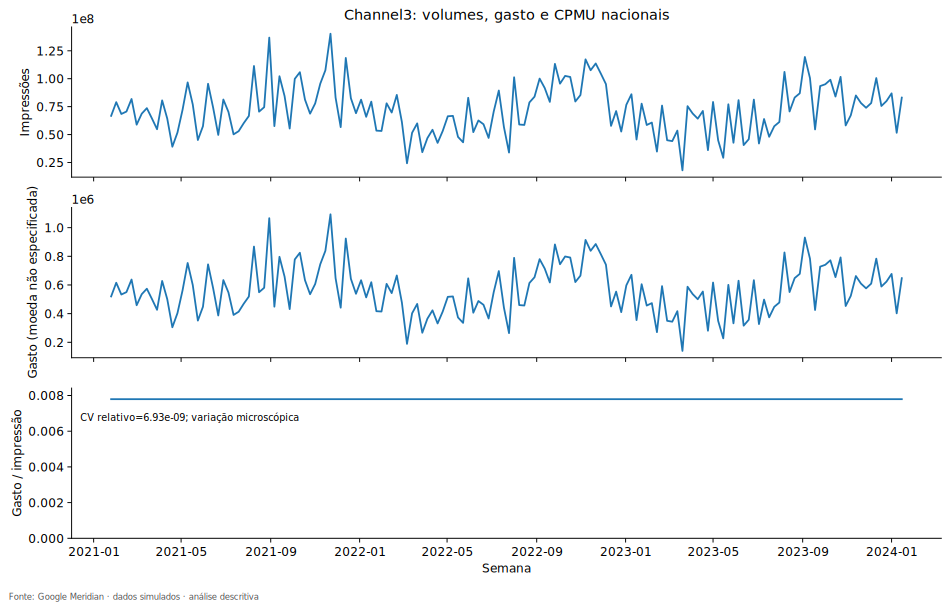

**Channel4_kpi_z** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

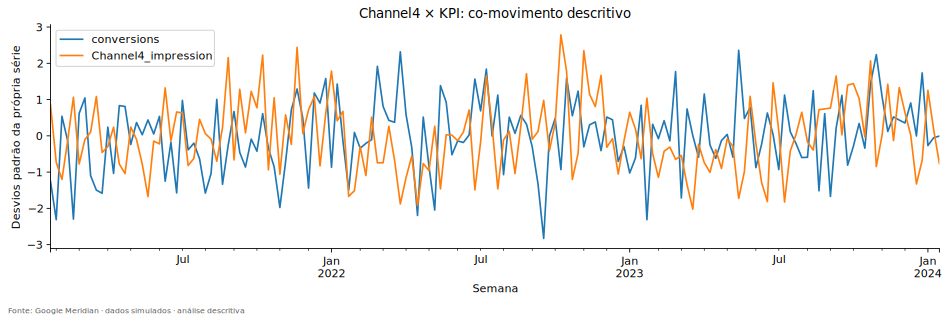

**Channel4_timeseries** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

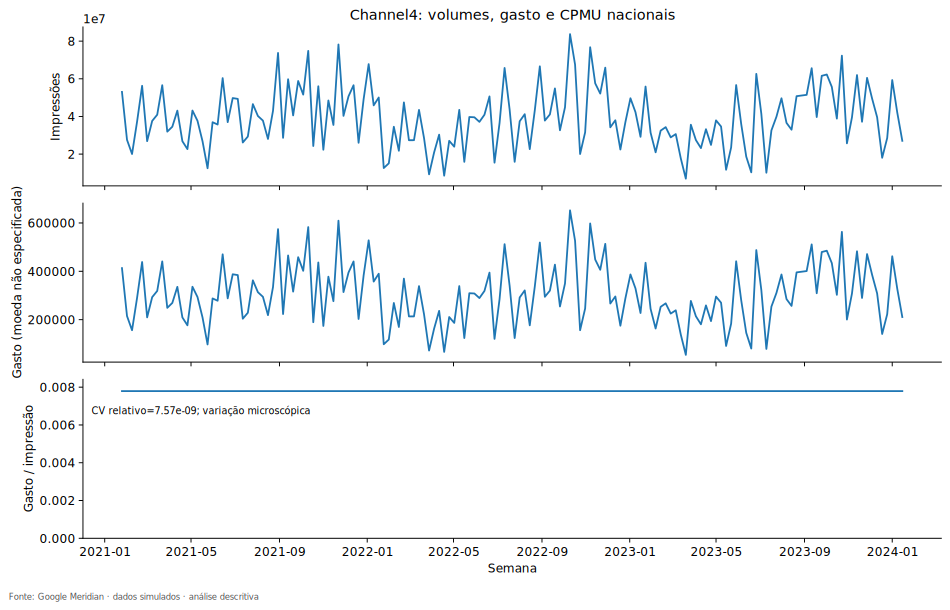

**Organic_channel0_impression_distribution** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

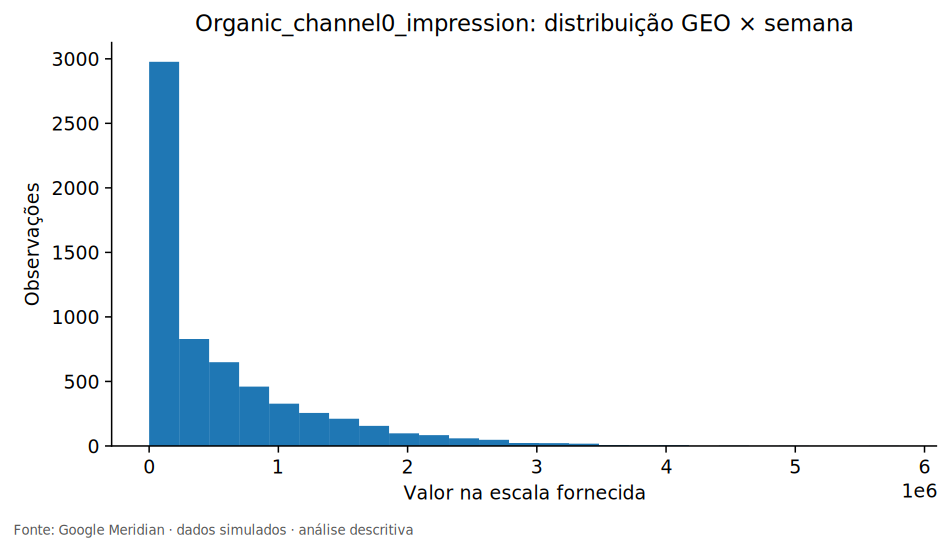

**Organic_channel0_impression_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

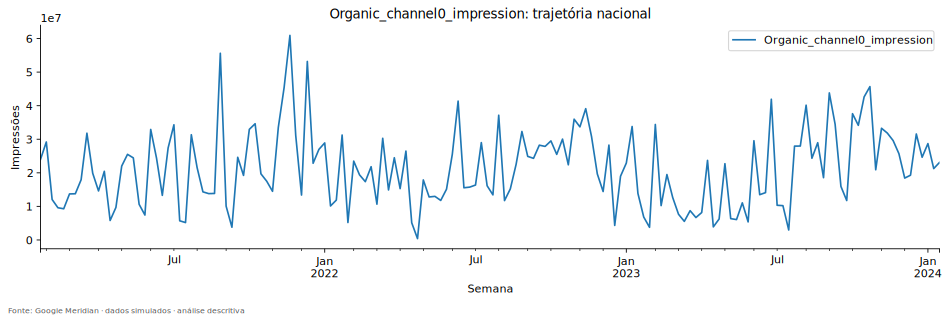

**Promo_distribution** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

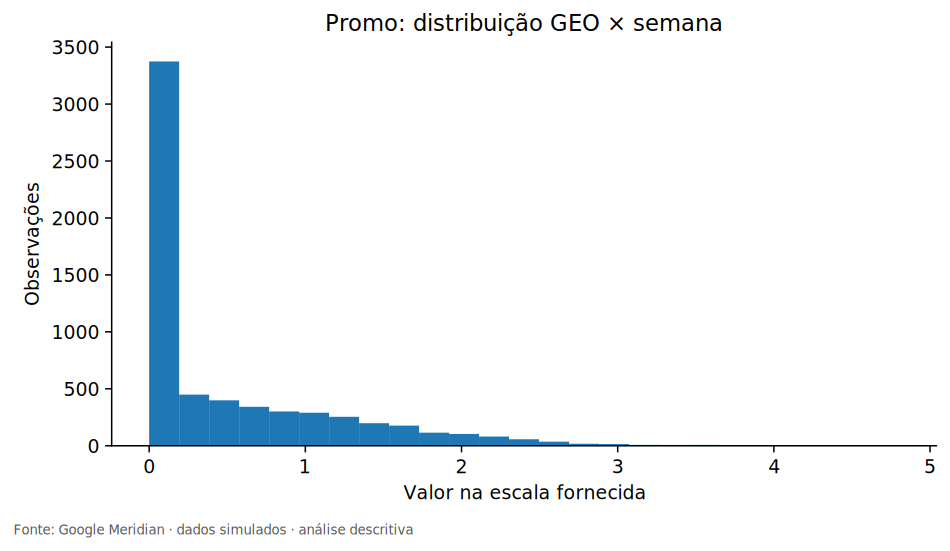

**Promo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

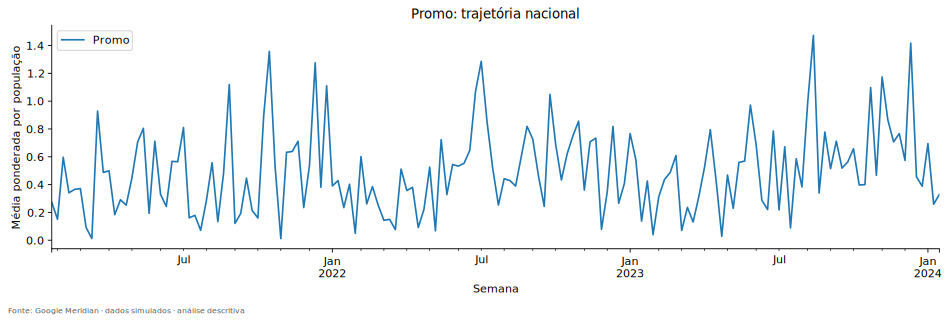

**competitor_sales_control_distribution** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

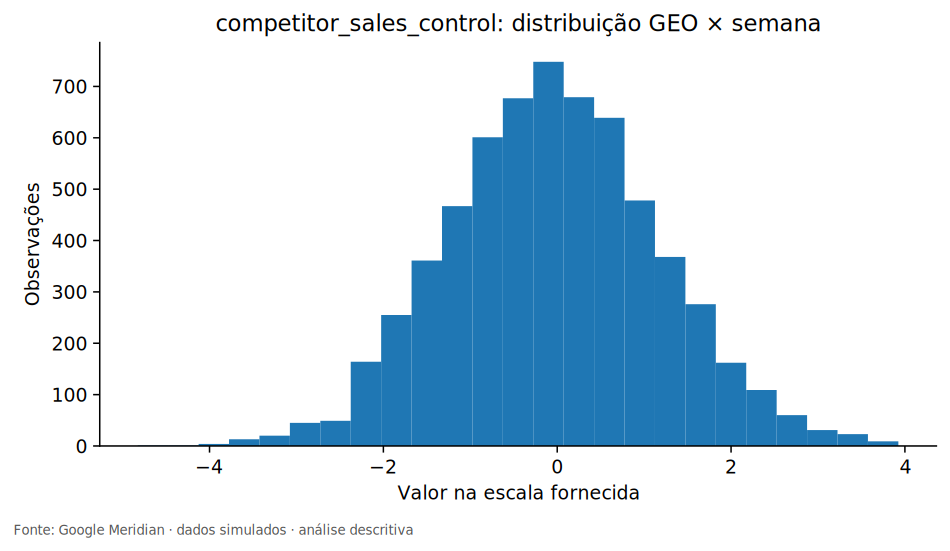

**competitor_sales_control_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

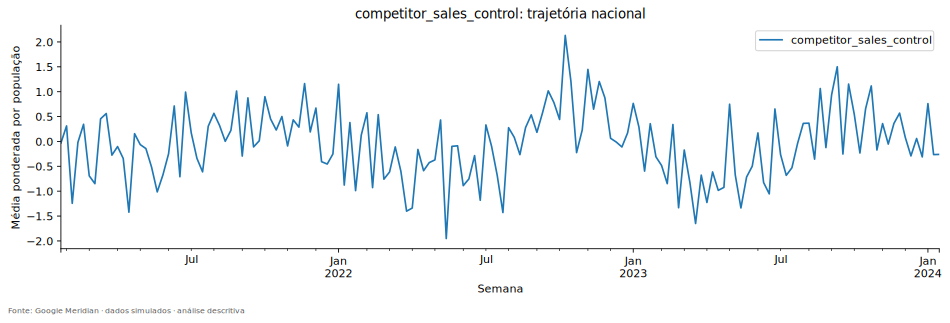

**kpi_stl_52** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

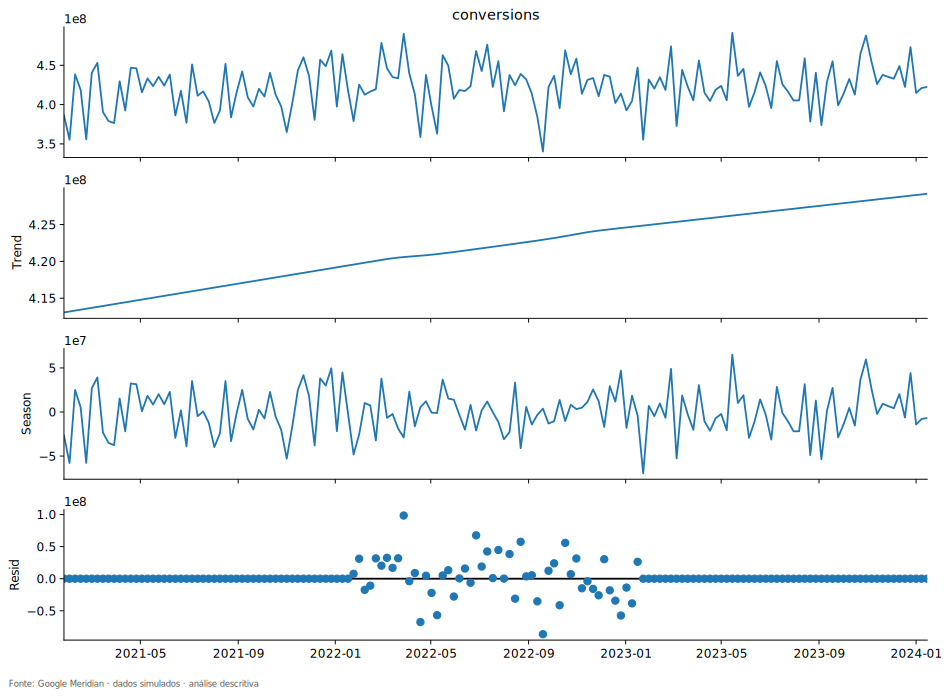

**kpi_trend** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

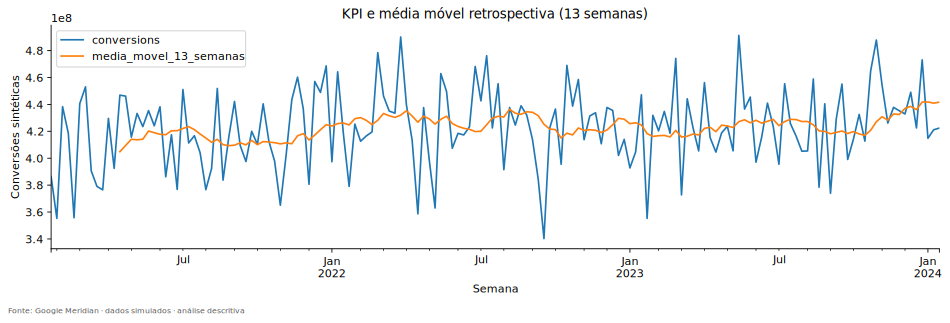

**sentiment_score_control_distribution** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

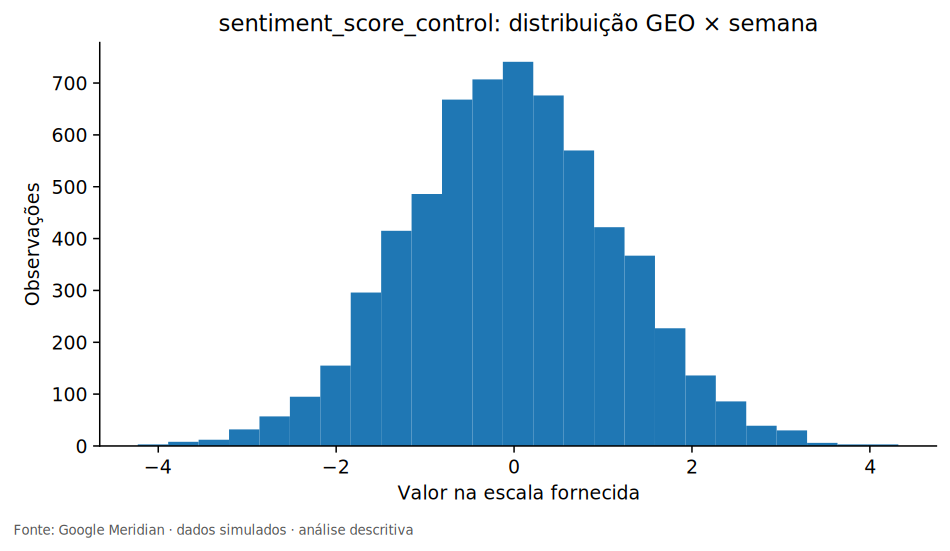

**sentiment_score_control_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

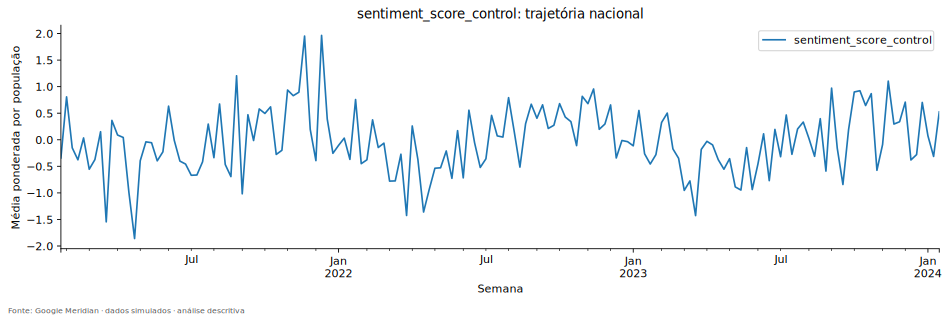

In [ ]:
show(report_02, part="evidence")


---
## Seção executável 03 — Geografia e fontes da variação

## Capítulo 5 — O preço de somar tudo

Imagine duas regiões. Em uma, o resultado sobe; na outra, cai na mesma quantidade. O total não muda. Se guardarmos apenas esse total, a semana parecerá estável, embora tenha sido bastante diferente para cada região. Esse é um exemplo imaginado, mas expõe uma limitação real da operação que acabamos de fazer.

A visão **nacional**, ou *national-level*, preserva a evolução do conjunto. Quando mantemos uma observação para cada lugar e semana, trabalhamos em **geo-level**. Não se trata apenas de acrescentar uma coluna a uma tabela. Preservamos a possibilidade de distinguir histórias que se anulam ou se misturam na soma.

Antes de acompanhar essas histórias no tempo, vale conhecer seus tamanhos. O gráfico abaixo soma todas as semanas de cada mercado e coloca os mercados em ordem de volume acumulado. Cada barra pertence a um endereço, e sua altura responde quanto ele contribuiu para o total do período.

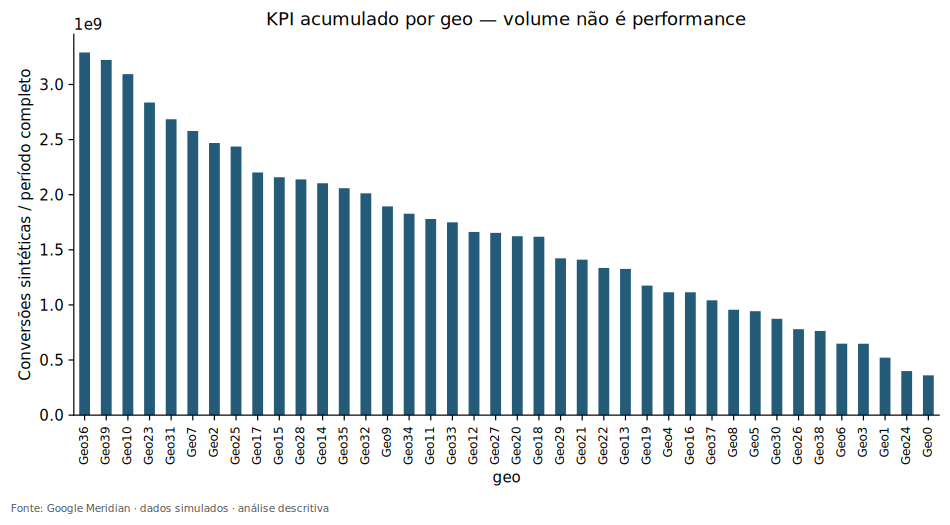

`Geo36` aparece no topo, com aproximadamente **5% do KPI acumulado**. `Geo39` vem logo depois. Existe uma diferença visível entre os maiores e os menores mercados, mas não temos um único lugar que praticamente substitua todos os outros. A [tabela por mercado](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/geo_kpi_summary.csv) permite conferir cada participação; a [curva de concentração](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/geo/kpi_concentration.svg) mostra quanto do total acumulamos ao incluir os maiores, um após outro.

Seria tentador chamar a barra mais alta de “melhor mercado”. Ainda não podemos. O gráfico mede volume, e o volume depende de quantas pessoas estão naquele lugar, entre outras coisas. Uma rede pode vender mais em um mercado maior sem que cada pessoa compre mais, e sem que sua publicidade funcione melhor ali.

A distinção importa porque queremos descobrir o que a geografia acrescenta. Se todos os mercados fossem cópias de uma mesma trajetória, multiplicadas apenas por seu tamanho, guardar os endereços nos daria uma informação diferente daquela oferecida por trajetórias realmente distintas. Precisamos examinar essa explicação simples antes de atribuir significado às diferenças.

O próximo passo, portanto, nasce da própria barra mais alta: ela é alta porque o mercado se comporta de modo particular ou porque há mais pessoas por trás dela?

## Capítulo 6 — O tamanho muda a história

Para comparar mercados, precisamos oferecer uma chance à hipótese mais simples: lugares maiores produzem volumes maiores. A população nos dá uma medida de tamanho, embora não conte tudo sobre demanda, renda ou comportamento.

No gráfico seguinte, cada ponto é um mercado. Sua posição horizontal mostra a população simulada, e a vertical, as conversões acumuladas. Se o tamanho acompanhasse pouco o resultado, os pontos não precisariam formar uma direção clara. Se mercados mais populosos concentrassem mais conversões, veríamos uma subida conjunta.

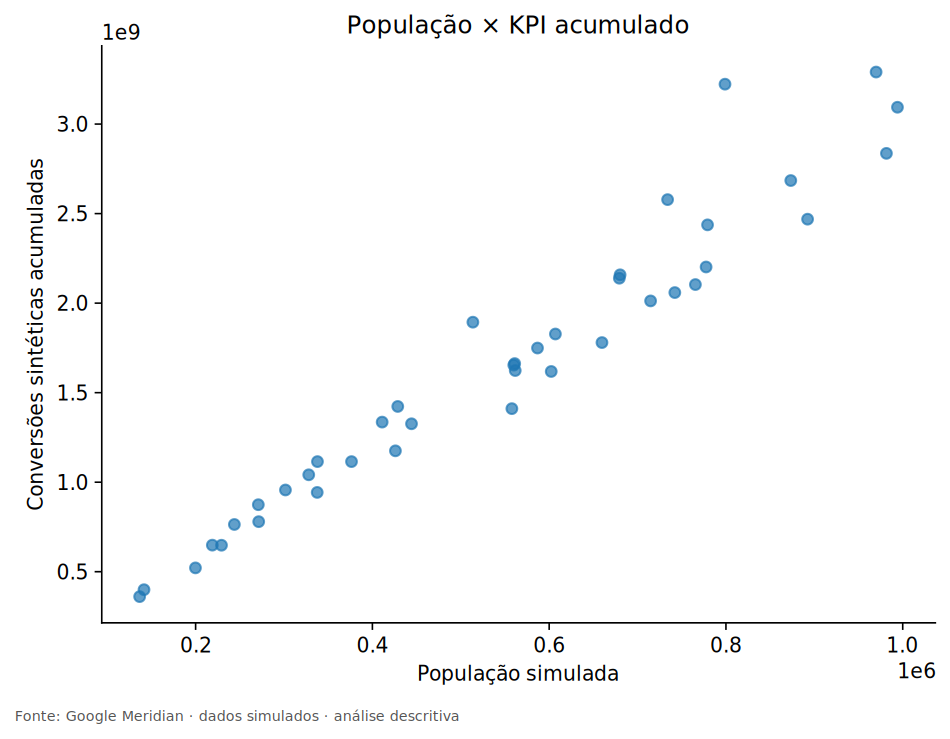

A subida é forte. Ao resumir essa associação linear, encontramos aproximadamente **0,97** em uma escala que vai de −1 a 1. Essa medida é a **correlação de Pearson**: valores positivos próximos de 1 indicam que as duas grandezas acompanham uma direção crescente muito marcada. Ela não demonstra que população seja a única explicação do resultado, mas mostra por que o ranking de volumes precisava desse contexto.

Também foi conferida a concordância dos rankings, sem exigir que a relação siga uma linha reta. Essa outra lente, chamada **correlação de Spearman**, fica próxima de 0,98. Neste caso, as duas medidas contam uma história compatível: os mercados maiores tendem a ocupar posições elevadas no resultado acumulado. Os valores completos estão na [comparação populacional](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/population_kpi_correlation.csv).

Para enxergar o que o volume pode esconder, passamos a comparar conversões em uma mesma base de população: quanto corresponderia a cada grupo de mil habitantes. Esse modo de olhar recebe o nome de **per capita**, aqui expresso por mil pessoas. Usamos a população de cada mercado uma vez como denominador, não a soma das 156 repetições dessa população na base.

O [ranking por mil habitantes](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/geo/kpi_per_capita.svg) muda a pergunta. `Geo36`, que liderava em volume total, apresenta cerca de 21,7 mil conversões simuladas por mil habitantes por semana. `Geo39` fica perto de 25,9 mil. A inversão entre esses dois mercados mostra que liderança em volume e intensidade relativa não são a mesma coisa.

Esses valores não representam a porcentagem de pessoas que comprou. Conversões não são pessoas únicas, e, nesta base, também são grandezas simuladas. Interpretar uma razão elevada como “mais de 100% dos habitantes converteram” misturaria unidades que não medem a mesma coisa.

O mesmo cuidado foi levado à mídia e ao gasto. Comparar exposição por mil habitantes ajuda a distinguir volume associado ao tamanho de intensidade relativa. Isso não altera os dados originais nem decide como o Meridian deverá recebê-los. É uma lente da investigação, não uma correção universal.

O tamanho explicou por que parte do mapa parecia tão desigual. Entretanto, ainda estamos comparando resumos de todo o período. Duas regiões podem ter médias parecidas e passar por semanas muito diferentes. Para continuar, precisamos abrir os históricos que essas médias comprimiram.

## Capítulo 7 — Cada endereço tem um histórico

Saber o tamanho médio de um mercado não revela quando ele teve semanas boas ou ruins. Para recuperar essa informação, podemos desenhar uma pequena série para cada lugar. Em vez de sobrepor quarenta linhas numa única figura, abrimos algumas histórias lado a lado.

Os painéis abaixo foram escolhidos por critérios registrados: mercados dos extremos e do centro do ranking de volume, além de extremos de oscilação relativa. Essa técnica de pequenas figuras comparáveis é conhecida como **small multiples**. O eixo do tempo é comum, mas cada painel possui sua própria escala vertical. Por isso, linhas com alturas visuais semelhantes não significam volumes semelhantes.

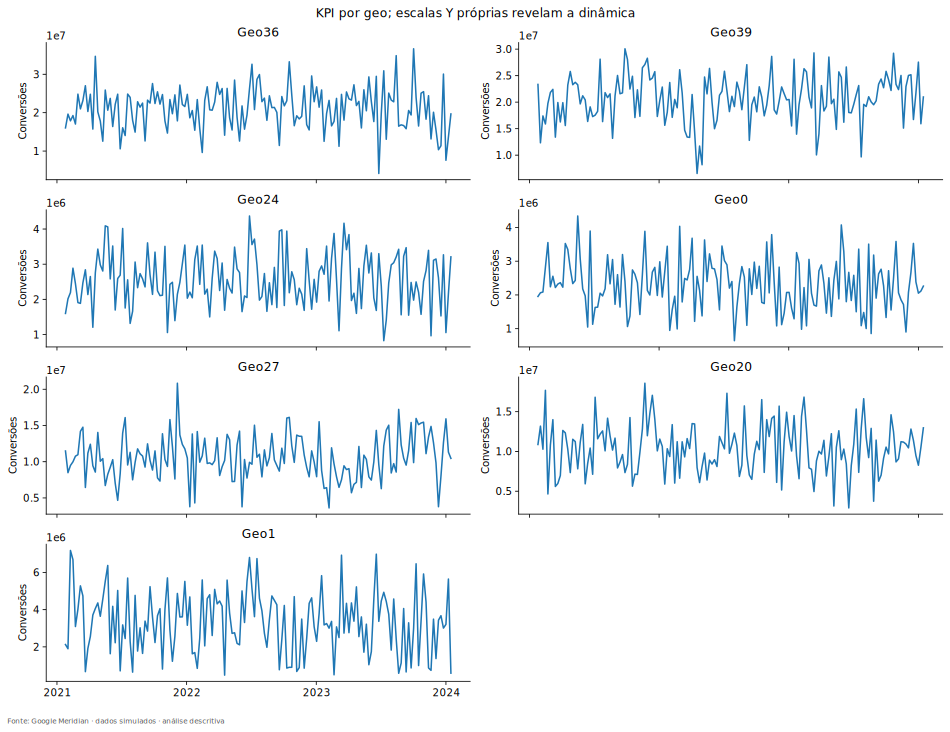

`Geo36` e `Geo39`, já conhecidos pelo volume, aparecem ao lado de mercados menores, como `Geo0` e `Geo24`. A seleção permite enxergar movimentos sem que as curvas dos menores fiquem achatadas pela escala dos maiores. Ao percorrer os painéis, interessa menos decorar a data de cada pico e mais perceber se as subidas e descidas parecem ocorrer todas juntas.

A impressão visual precisa ser conferida além dos mercados selecionados. Então comparamos os históricos de cada par de mercados. Para essa pergunta usamos a mesma ideia de correlação: agora as duas sequências são as conversões semanais de dois lugares diferentes. O [quadro completo](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/geo/geo_correlation.svg) cruza todos os mercados; sua diagonal compara cada um consigo mesmo e, por isso, não traz descoberta sobre sincronização.

Fora dessa diagonal existem **780 pares distintos**. A correlação mediana é aproximadamente **0,03**, e mesmo o maior valor está perto de **0,28**. A [síntese desses pares](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/geo_synchronization_summary.csv) mostra que não estamos diante de quarenta séries caminhando quase em perfeita sintonia. Há diferenças de dinâmica que a linha nacional não exibia.

Isso não prova que os mercados sejam independentes. Dependência pode assumir formas que uma medida linear contemporânea não captura, e a própria simulação pode conter fatores compartilhados. Também não autoriza separar os mercados em grupos comerciais inventados. O que encontramos foi mais específico: pouca sincronização linear nos históricos de conversões observados.

Agora temos duas pistas. Os mercados diferem em tamanho, e suas trajetórias não são cópias perfeitamente sincronizadas. Mas essas pistas ainda estão misturadas quando medimos a variação de todas as linhas da base. Precisamos distinguir a distância entre os mercados da mudança que acontece dentro de cada um.

## Capítulo 8 — Duas maneiras de ser diferente

Imagine primeiro uma rede em que um mercado registra sempre muito resultado e outro, sempre pouco. A tabela parecerá bastante variada quando juntarmos todas as linhas, mesmo que nada mude dentro de cada mercado. Agora imagine outra rede em que os mercados têm médias semelhantes, mas todos passam por semanas muito diferentes. Também haverá variação, só que de outra natureza.

Um modelo encontra pistas distintas nessas duas situações. Comparar um mercado permanentemente grande com outro permanentemente pequeno envolve diferenças de população e de características locais. Comparar um mercado consigo mesmo ao longo das semanas evita algumas diferenças persistentes, mas abre outras perguntas sobre o que mudou naquela semana.

A primeira fonte de diferença é chamada de **between**, porque está *entre* os mercados. A segunda é chamada de **within**, porque acontece *dentro* de cada mercado ao longo do tempo. Não são dois tipos de dados. São duas formas de olhar a dispersão das mesmas observações.

Para fazer a separação, o projeto compara as médias dos mercados entre si e, depois, as observações de cada mercado com sua própria média. A medida de dispersão usada nessa organização é a **variância**. No nosso painel completo, com os pesos adotados, essas duas parcelas recompõem a dispersão total. A explicação matemática está na [metodologia](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/docs/methodology_eda.md); aqui, a ideia importante é distinguir “esse lugar costuma ser maior” de “essa semana foi diferente do habitual desse lugar”.

No gráfico abaixo, cada barra tem a mesma altura total, representando toda a variância de uma variável. A parte azul mostra as diferenças entre mercados, e a laranja, as mudanças dentro deles. Um valor de 0,8 no eixo representa 80% da variância. `conversions` é o resultado; os nomes terminados em `impression` indicam exposição e os terminados em `spend`, gasto.

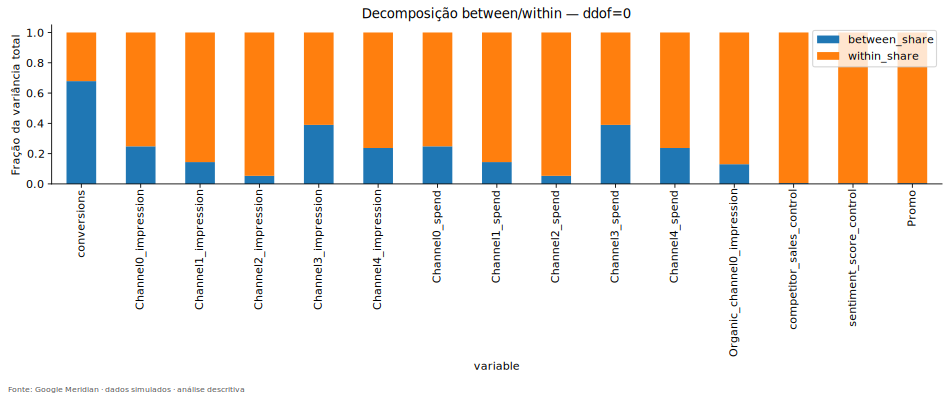

Nas conversões, aproximadamente **68%** da variação bruta está entre mercados e **32%** dentro deles. Isso combina com o que vimos: há diferenças persistentes de nível, fortemente associadas ao tamanho, mas também há semanas diferentes dentro de cada endereço.

A mídia conta outra história. Em `Channel2`, cerca de **95%** da variação de exposição está dentro dos mercados. Em `Channel3`, essa parcela é menor, aproximadamente **61%**, embora continue majoritária. Seria errado concluir que `Channel2` é o melhor canal para o modelo apenas porque apresenta um número maior. Ainda precisamos descobrir como essa variação é produzida: por mudanças graduais de intensidade, por muitos períodos zerados ou por acontecimentos compartilhados.

Esse último ponto impõe uma pausa. Suponha que todos os mercados aumentem a publicidade na mesma semana. Haverá mudança dentro de cada mercado, mas boa parte dela poderá ser vista também na série nacional. Portanto, encontrar muito *within* não responde sozinho à nossa pergunta sobre o que os endereços acrescentam.

Até aqui separamos diferenças persistentes de movimentos internos. A próxima investigação precisa separar, dentro do movimento, aquilo que acompanha o calendário comum. Só então poderemos examinar o que sobra de particular em cada combinação de lugar e semana.

## Capítulo 9 — O endereço e o calendário

Pense em alguém tentando antecipar o valor de uma ficha sem ver todas as suas colunas. Primeiro, essa pessoa recebe apenas o nome do mercado. Se cada lugar mantiver um nível característico, o endereço já ajudará bastante. Depois, fazemos outra tentativa: mostramos apenas a semana. Se muitos lugares passarem por um movimento comum naquele período, o calendário será informativo.

Podemos medir quanto cada uma dessas informações ajuda a descrever a variação observada. O resumo baseado no endereço é chamado de **R² GEO**. O resumo baseado na semana é chamado de **R² TIME**. Não estamos avaliando aqui a previsão de semanas novas; estamos descrevendo quanto das diferenças existentes acompanha as médias dos mercados ou as médias das semanas.

No gráfico seguinte, cada ponto é uma variável. Os eixos expressam frações: 0,4 corresponde a 40% da variância. Mais à direita significa maior participação das diferenças persistentes entre mercados. Mais acima significa maior participação das diferenças comuns entre semanas. Um ponto perto da origem pode variar muito: sua variação apenas não é bem resumida por essas duas informações isoladas. O gráfico usa a escala bruta, antes da divisão por população.

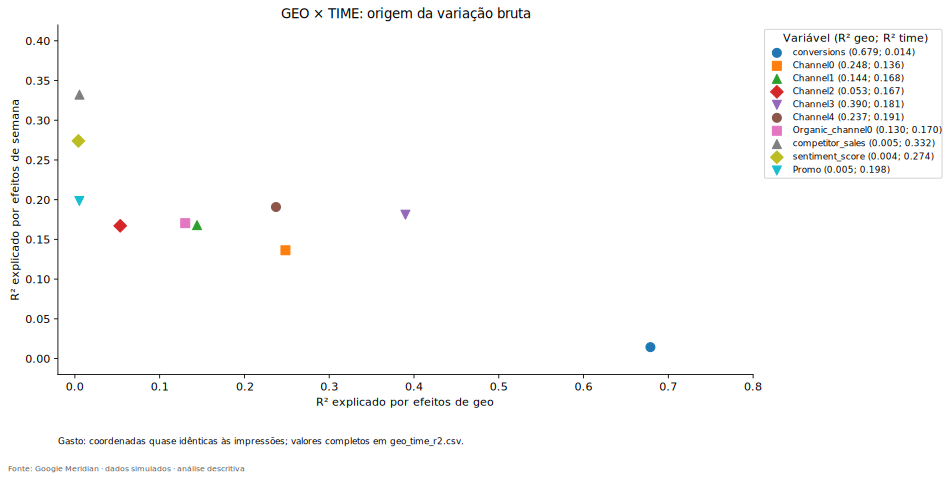

As conversões aparecem bem à direita e perto da base. Saber o mercado acompanha cerca de **68%** de sua variância bruta; saber a semana, apenas cerca de **1,4%**. Isso é compatível com diferenças importantes de nível e com a baixa sincronização que encontramos entre os históricos dos mercados.

`Channel3` também está mais à direita que `Channel2`. O primeiro tem cerca de **39%** de componente geográfico, enquanto o segundo tem aproximadamente **5%**. Os dois, porém, têm um componente temporal próximo de 17% a 18%. O posicionamento sintetiza a distinção anterior: os canais não carregam a mesma combinação de diferenças persistentes e movimentos no tempo.

Podemos dar mais um passo. Em cada ficha, retiramos o nível habitual do mercado e o movimento médio daquela semana. O que sobra é um desvio que não foi acomodado por essas duas explicações aditivas. A palavra **resíduo** designa essa sobra. Quando fazemos a retirada nas duas direções, mercado e tempo, encontramos nos arquivos a expressão **two-way**.

Para a mídia paga, sobra entre **43% e 78% da variância bruta**, dependendo do canal. Essa é uma pista importante: os registros não se resumem a um nível fixo para cada mercado mais uma mesma curva para todos. Mas ainda existe uma armadilha. Se mercados grandes reproduzem um mesmo movimento proporcional numa escala maior, uma retirada aditiva pode deixar sobras mesmo sem uma execução territorial realmente diferente em termos relativos.

É por isso que a população precisava entrar na história antes desta conclusão. Repetindo a análise por mil habitantes, a parcela geográfica persistente das mídias pagas cai para menos de **0,6%** em todos os canais. O contraste é especialmente claro em `Channel3`: de quase 39% na escala bruta para aproximadamente 0,5% na escala relativa. Boa parte da impressão de diferenças permanentes de mídia acompanha o tamanho dos lugares.

Ainda assim, na escala por habitante permanece um resíduo entre **65% e 79%** da variância de mídia paga. As [decomposições bruta](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/geo_time_r2.csv) e [por habitante](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/geo_time_r2_per_capita.csv) sustentam uma conclusão mais precisa: a diferença territorial não está principalmente em mercados com intensidades médias radicalmente distintas, mas há movimentos locais ao longo do tempo que uma única trajetória comum não descreve.

Essas porcentagens se referem à variância de cada variável em sua respectiva escala. Não são porcentagens de vendas explicadas pela publicidade. Tampouco permitem chamar toda sobra de informação útil: ela pode incluir ruído e outros fatores não medidos. O que conseguimos foi localizar uma estrutura que vale investigar.

Agora precisamos aproximar essa estrutura de algo concreto. Se o movimento de mídia não é uma simples cópia nacional, como o dinheiro foi distribuído entre canais e mercados?

### A ponte entre a imagem e a fórmula

Para cada variável $x_{g,t}$, distinguimos a média geral $\bar x$, a média de cada geo $\bar x_g$ e a média de cada semana $\bar x_t$. O desvio dentro do geo é $x_{g,t}-\bar x_g$. O resíduo nas duas direções é:

$$r_{g,t}=x_{g,t}-\bar x_g-\bar x_t+\bar x.$$

Somamos a média geral de volta porque ela foi retirada duas vezes. É como separar o patamar habitual do endereço e o movimento comum do calendário, mantendo a referência no lugar certo. No painel balanceado, com peso igual por observação e `ddof=0`, as parcelas são ortogonais e:

$$R^2_{geo}+R^2_{time}+\frac{\operatorname{Var}(r)}{\operatorname{Var}(x)}=1.$$

O código exige painel completo antes de usar essa identidade. Uma parcela residual alta se refere à variação **da variável analisada**; não é a parcela de conversões causada pela mídia. Dividir por população muda a variável e sua variância, por isso repetimos a decomposição, em vez de interpretar as duas escalas como intercambiáveis.

### Decompor sem perder a identidade

A função confere balanceamento e valores finitos antes de calcular between, within, R² e o resíduo two-way.

Código original de `src/statistics.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def variance_decomposition(panel: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Decomposição ponderada por observação (ddof=0); identidade total=between+within.

    R² two-way via double demeaning só é utilizado com painel completo/balanceado.
    O resíduo é interação/desvio geo-temporal, não efeito causal identificável.
    """
    if panel.duplicated(['geo','time']).any() or len(panel) != panel.geo.nunique()*panel.time.nunique():
        raise ValueError('Decomposição two-way exige painel balanceado sem duplicatas.')
    records=[]
    for col in columns:
        x=panel[col].astype(float)
        if not np.isfinite(x).all(): raise ValueError(f'{col}: valores não finitos.')
        grand=x.mean()
        g=x.groupby(panel.geo).transform('mean')
        t=x.groupby(panel.time).transform('mean')
        total=np.mean((x-grand)**2)
        between=np.mean((g-grand)**2)
        within=np.mean((x-g)**2)
        time=np.mean((t-grand)**2)
        residual=np.mean((x-g-t+grand)**2)
        ratio=lambda value: value/total if total>0 else np.nan
        records.append(dict(variable=col,total_variance=total,between_geo=between,
                            within_geo=within,between_share=ratio(between),within_share=ratio(within),
                            r2_geo=ratio(between),r2_time=ratio(time),
                            r2_geo_time=ratio(between+time),residual_geo_time_share=ratio(residual)))
    return pd.DataFrame(records).set_index('variable')


### Código completo desta etapa

A implementação abaixo foi transportada de `src/geo_analysis.py` (`geo_analysis`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('03')
def geo_analysis(panel):
    grouped=panel.groupby(GEO)
    geo=grouped[KPI].agg(['sum','mean','std','min','max']).rename(columns={'sum':'kpi_total'})
    geo[POP]=grouped[POP].first()
    geo['kpi_share']=geo.kpi_total/geo.kpi_total.sum()
    geo['population_share']=geo[POP]/geo[POP].sum()
    geo['kpi_per_1000_per_week']=geo['mean']/geo[POP]*1000
    geo=geo.sort_values('kpi_total',ascending=False)
    table(geo,'geo_kpi_summary');table(geo[[POP,'population_share']],'population_summary')
    decomposition=variance_decomposition(panel,analytical_columns(panel))
    table(decomposition,'within_between_variance');table(decomposition[['r2_geo','r2_time','r2_geo_time','residual_geo_time_share']],'geo_time_r2')
    per_capita=panel.copy()
    pc_cols=[KPI]+[c+'_impression' for c in channels(panel)]+[c+'_spend' for c in channels(panel)]+ORGANIC
    per_capita[pc_cols]=panel[pc_cols].div(panel[POP],axis=0)*1000
    pc_decomp=table(variance_decomposition(per_capita,pc_cols),'geo_time_r2_per_capita')
    table(per_capita[[GEO,TIME]+pc_cols],'per_capita_panel',False)
    pop_corr=pd.DataFrame([{'method':method,'correlation':geo[POP].corr(geo.kpi_total,method=method)} for method in ['pearson','spearman']])
    table(pop_corr,'population_kpi_correlation',False)
    concentration=pd.DataFrame({'rank':np.arange(1,len(geo)+1),'geo':geo.index,'cumulative_kpi_share':geo.kpi_share.cumsum().values})
    table(concentration,'kpi_concentration',False)
    figures=[bars(geo.kpi_total,'geo','kpi_by_geo','KPI acumulado por geo — volume não é performance','Conversões sintéticas / período completo'),
             bars(geo[POP].sort_values(ascending=False),'geo','population_by_geo','População simulada por geo','População'),
             bars(geo.kpi_per_1000_per_week.sort_values(ascending=False),'geo','kpi_per_capita','KPI médio semanal por 1.000 habitantes','Conversões / 1.000 habitantes / semana'),
             scatter(geo[POP],geo.kpi_total,'geo','population_kpi','População × KPI acumulado','População simulada','Conversões sintéticas acumuladas')]
    figures.append(lines(concentration.set_index('rank')[['cumulative_kpi_share']],'geo','kpi_concentration','Concentração cumulativa do KPI (geos ordenados)','Fração acumulada'))
    pivot=panel.pivot(index=TIME,columns=GEO,values=KPI).reindex(columns=geo.index)
    figures.append(heatmap(pivot.corr(),'geo','geo_correlation','Sincronização do KPI entre geos (Pearson)','RdBu_r',-1,1))
    table(pivot.corr(),'geo_kpi_correlation')
    # Seleção determinística: extremos de volume, centro do ranking e extremos de volatilidade.
    cv=grouped[KPI].std(ddof=0)/grouped[KPI].mean().replace(0,np.nan)
    selected=list(dict.fromkeys(list(geo.index[:2])+list(geo.index[-2:])+list(geo.index[len(geo)//2-1:len(geo)//2+1])+[cv.idxmin(),cv.idxmax()]))
    table(pd.DataFrame({'geo':selected,'criterion':'união: top2/bottom2/centro de volume e min/max CV'}),'geo_plot_selection',False)
    fig,axes=plt.subplots(4,2,figsize=(13,10),sharex=True)
    for ax,g in zip(axes.flat,selected):
        ax.plot(pivot.index,pivot[g]);ax.set(title=g,ylabel='Conversões')
        import matplotlib.dates as mdates
        ax.xaxis.set_major_locator(mdates.YearLocator());ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    for ax in list(axes.flat)[len(selected):]:ax.set_visible(False)
    fig.suptitle('KPI por geo; escalas Y próprias revelam a dinâmica')
    figures.append(save(fig,'geo','kpi_small_multiples'))
    fig,ax=plt.subplots(figsize=(12,5))
    decomposition[['between_share','within_share']].plot.bar(stacked=True,ax=ax)
    ax.set(title='Decomposição between/within — ddof=0',ylabel='Fração da variância total')
    figures.append(save(fig,'geo','variance_decomposition'))
    fig,ax=plt.subplots(figsize=(12,6))
    plotted=decomposition.loc[[c for c in decomposition.index if not c.endswith('_spend')]]
    for i,(var,row) in enumerate(plotted.iterrows()):
        label=var.removesuffix('_impression').replace('_control','')
        ax.scatter(row.r2_geo,row.r2_time,s=65,marker=['o','s','^','D','v'][i%5],
                   label=f'{label} ({row.r2_geo:.3f}; {row.r2_time:.3f})')
    ax.legend(title='Variável (R² geo; R² time)',loc='upper left',bbox_to_anchor=(1.01,1),fontsize=8)
    ax.set(xlabel='R² explicado por efeitos de geo',ylabel='R² explicado por efeitos de semana',
           title='GEO × TIME: origem da variação bruta',xlim=(-.02,.8),ylim=(-.02,.42))
    ax.text(0,-.2,'Gasto: coordenadas quase idênticas às impressões; valores completos em geo_time_r2.csv.',transform=ax.transAxes,fontsize=8)
    figures.append(save(fig,'geo','geo_time_r2'))
    for col in [KPI]+CONTROLS:
        matrix=panel.pivot(index=GEO,columns=TIME,values=col).reindex(geo.index)
        figures.append(heatmap(matrix,'geo',col+'_geo_time',f'{col}: GEO × semana'))
    matrix=per_capita.pivot(index=GEO,columns=TIME,values=KPI).reindex(geo.index)
    figures.append(heatmap(matrix,'geo','kpi_pc_geo_time','Conversões semanais / 1.000 habitantes'))
    text=f'''O maior geo responde por {geo.kpi_share.max():.1%} do KPI acumulado; os cinco maiores por {geo.kpi_share.head(5).sum():.1%}. A correlação populacional com KPI total é {pop_corr.loc[pop_corr.method=='spearman','correlation'].iloc[0]:.3f} (Spearman). A escala populacional precisa ser considerada antes de interpretar rankings.

O KPI tem {decomposition.loc[KPI,'between_share']:.1%} da variância between-geo e {decomposition.loc[KPI,'within_share']:.1%} within-geo. A identidade usa momentos populacionais (ddof=0), com peso igual por observação. R²_geo equivale à parcela between; R²_time quantifica semanas comuns. No painel balanceado, a parcela residual two-way do KPI é {decomposition.loc[KPI,'residual_geo_time_share']:.1%}; por habitante é {pc_decomp.loc[KPI,'residual_geo_time_share']:.1%}.

Within não significa automaticamente sinal geográfico novo: inclui choques temporais nacionais. Por isso apresentamos também o resíduo após remover simultaneamente geo e tempo. Essa decomposição é descritiva e depende da escala. Os small multiples usam geos escolhidos por critérios registrados; os cálculos e heatmaps incluem todos os geos. Geo0…Geo39 são rótulos sintéticos, sem fronteiras para um mapa geográfico real.'''
    return result('03_eda_geo',text,{'geo_summary':geo,'decomposition':decomposition,'per_capita_decomposition':pc_decomp},figures,'Mix, alocação territorial, concentração e variação de cada canal dentro dos geos.')


In [ ]:
report_03 = geo_analysis(geo_time_panel)
show(report_03, part="summary")


### Resultado observado e conclusão parcial

O maior geo responde por 5.0% do KPI acumulado; os cinco maiores por 22.9%. A correlação populacional com KPI total é 0.978 (Spearman). A escala populacional precisa ser considerada antes de interpretar rankings.

O KPI tem 67.9% da variância between-geo e 32.1% within-geo. A identidade usa momentos populacionais (ddof=0), com peso igual por observação. R²_geo equivale à parcela between; R²_time quantifica semanas comuns. No painel balanceado, a parcela residual two-way do KPI é 30.7%; por habitante é 86.1%.

Within não significa automaticamente sinal geográfico novo: inclui choques temporais nacionais. Por isso apresentamos também o resíduo após remover simultaneamente geo e tempo. Essa decomposição é descritiva e depende da escala. Os small multiples usam geos escolhidos por critérios registrados; os cálculos e heatmaps incluem todos os geos. Geo0…Geo39 são rótulos sintéticos, sem fronteiras para um mapa geográfico real.

**Sincronização:** 780 pares, mediana 0.0280, mínimo -0.2151 (Geo32 × Geo24), máximo 0.2804 (Geo14 × Geo22). Baixa sincronização linear não demonstra independência. Small multiples cobrem extremos de volume/CV e usam escalas Y próprias.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Sincronização:** 780 pares, mediana 0.0280, mínimo -0.2151 (Geo32 × Geo24), máximo 0.2804 (Geo14 × Geo22). Baixa sincronização linear não demonstra independência. Small multiples cobrem extremos de volume/CV e usam escalas Y próprias.
- **Quais problemas apareceram?** Geos fictícios não permitem inventar contextos territoriais.
- **O que falta investigar?** Mix, alocação territorial, concentração e variação de cada canal dentro dos geos.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

**geo_summary** — 40 linhas; CSV completo em `outputs/tables/`.

,kpi_total,mean,std,min,max,population,kpi_share,population_share,kpi_per_1000_per_week
geo,,,,,,,,,
Geo36,3.290565e+09,2.109336e+07,5.507861e+06,4166830.80,36644916.0,969886.50,0.049909,0.044702,21748.281403
Geo39,3.222847e+09,2.065927e+07,4.438007e+06,6550282.00,30060602.0,798939.10,0.048882,0.036823,25858.383877
Geo10,3.093954e+09,1.983304e+07,6.371937e+06,5597731.50,33824700.0,994048.94,0.046927,0.045816,19951.772822
Geo23,2.836450e+09,1.818237e+07,5.226278e+06,5906972.00,36712692.0,981570.90,0.043022,0.045240,18523.746607
Geo31,2.684670e+09,1.720942e+07,4.773290e+06,5595800.00,31523720.0,873369.70,0.040720,0.040253,19704.623992
Geo7,2.578130e+09,1.652648e+07,4.180518e+06,5721620.00,28238984.0,733989.56,0.039104,0.033829,22515.954581
Geo2,2.468820e+09,1.582577e+07,4.684044e+06,4341767.00,29242514.0,892369.50,0.037446,0.041129,17734.548771
Geo25,2.437115e+09,1.562253e+07,4.305033e+06,4081507.00,25940226.0,779181.90,0.036965,0.035912,20049.916609
Geo17,2.201843e+09,1.411438e+07,4.340580e+06,3393230.50,25439212.0,777539.94,0.033396,0.035837,18152.606923


**decomposition** — 15 linhas; CSV completo em `outputs/tables/`.

,total_variance,between_geo,within_geo,between_share,within_share,r2_geo,r2_time,r2_geo_time,residual_geo_time_share
variable,,,,,,,,,
conversions,3.695331e+13,2.508695e+13,1.186637e+13,0.678882,0.321118,0.678882,0.014340,0.693223,0.306777
Channel0_impression,6.712189e+11,1.667112e+11,5.045076e+11,0.248371,0.751629,0.248371,0.136330,0.384701,0.615299
Channel1_impression,3.851114e+11,5.549878e+10,3.296126e+11,0.144111,0.855889,0.144111,0.167931,0.312042,0.687958
Channel2_impression,3.081801e+11,1.648447e+10,2.916956e+11,0.053490,0.946510,0.053490,0.167090,0.220580,0.779420
Channel3_impression,1.702277e+12,6.636814e+11,1.038596e+12,0.389879,0.610121,0.389879,0.181100,0.570978,0.429022
Channel4_impression,8.355853e+11,1.982119e+11,6.373734e+11,0.237213,0.762787,0.237213,0.190747,0.427960,0.572040
Channel0_spend,3.609065e+07,8.963869e+06,2.712678e+07,0.248371,0.751629,0.248371,0.136330,0.384701,0.615299
Channel1_spend,3.579739e+07,5.158797e+06,3.063859e+07,0.144111,0.855889,0.144111,0.167931,0.312042,0.687958
Channel2_spend,1.701728e+07,9.102497e+05,1.610703e+07,0.053490,0.946510,0.053490,0.167090,0.220580,0.779420


**per_capita_decomposition** — 12 linhas; CSV completo em `outputs/tables/`.

...

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

**competitor_sales_control_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

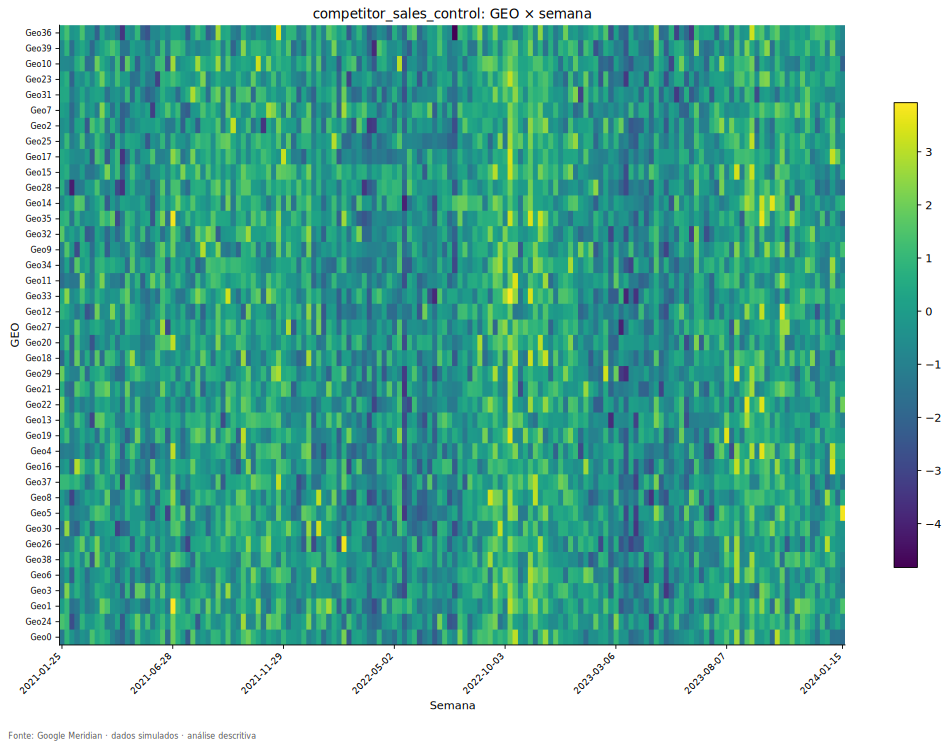

**conversions_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

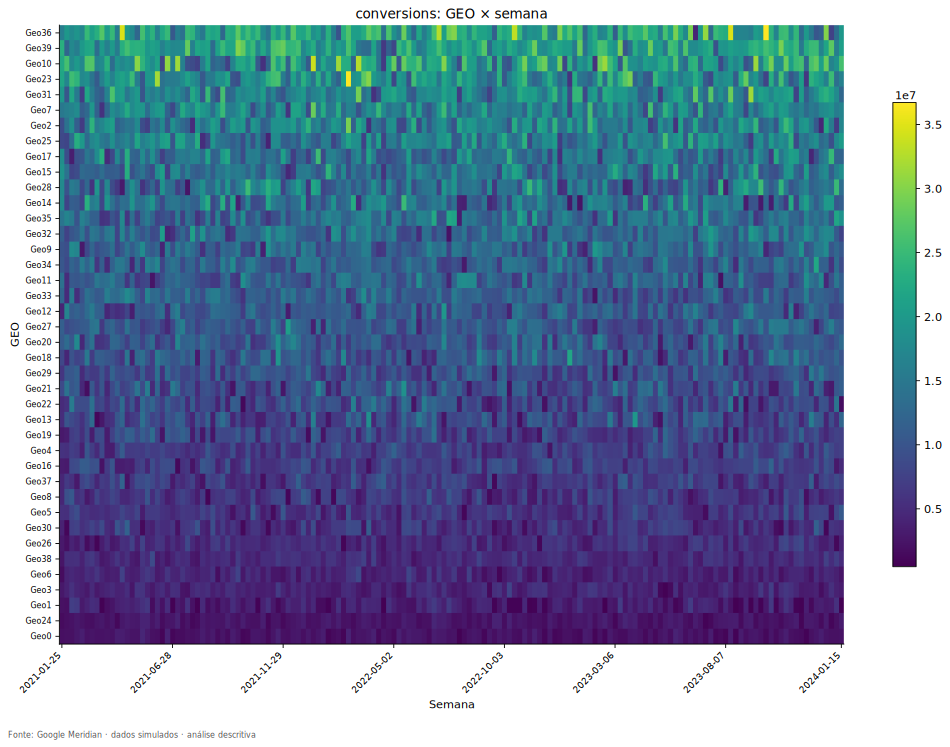

**geo_correlation** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

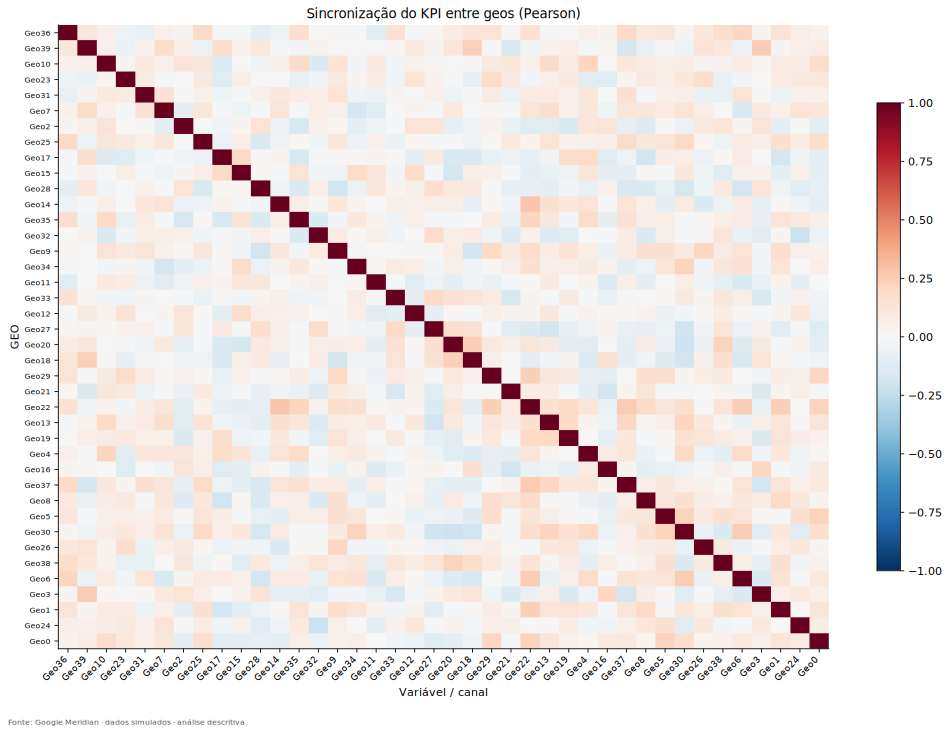

**geo_time_r2** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

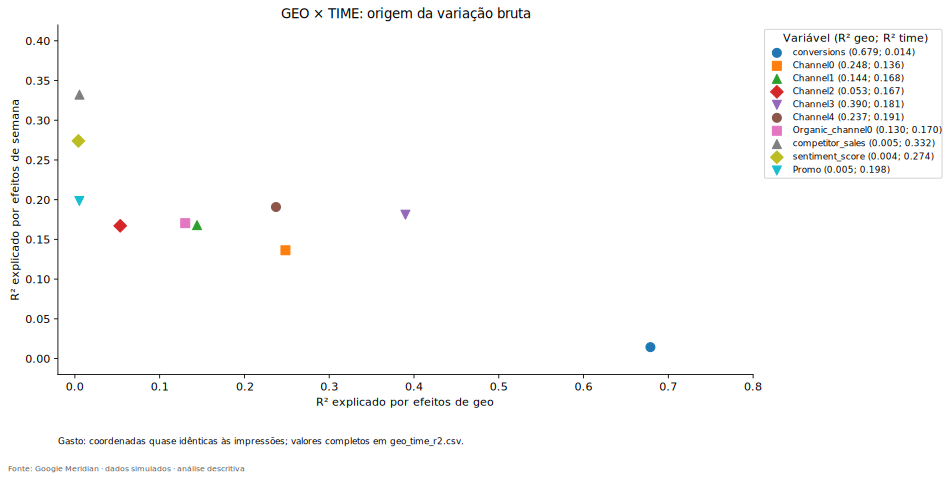

**kpi_by_geo** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

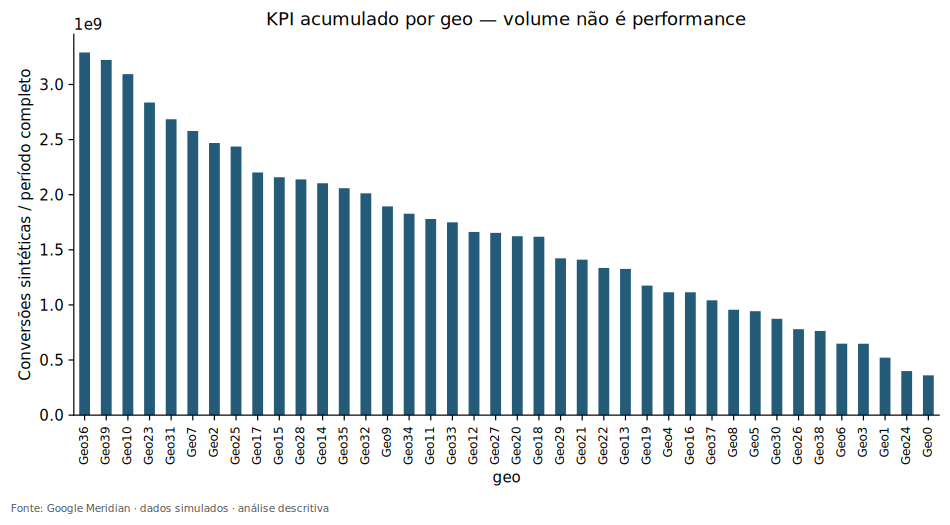

**kpi_concentration** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

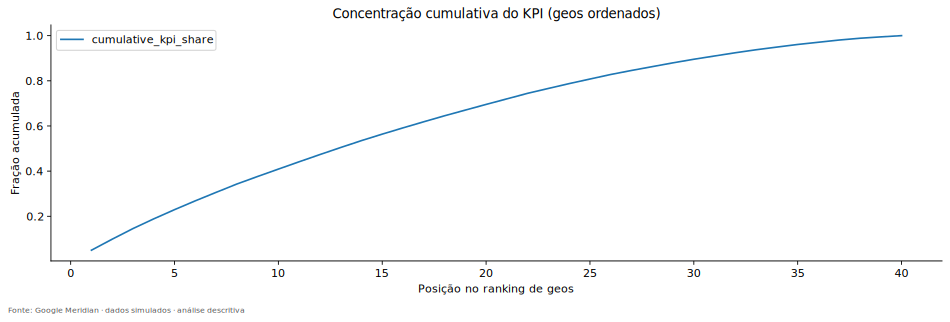

**kpi_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

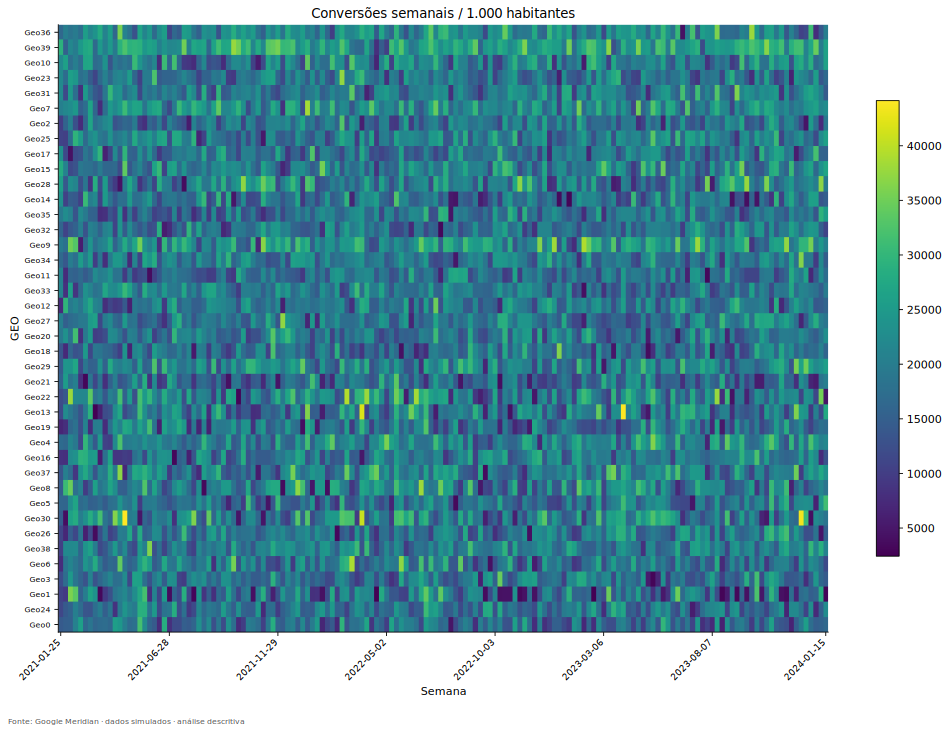

**kpi_per_capita** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

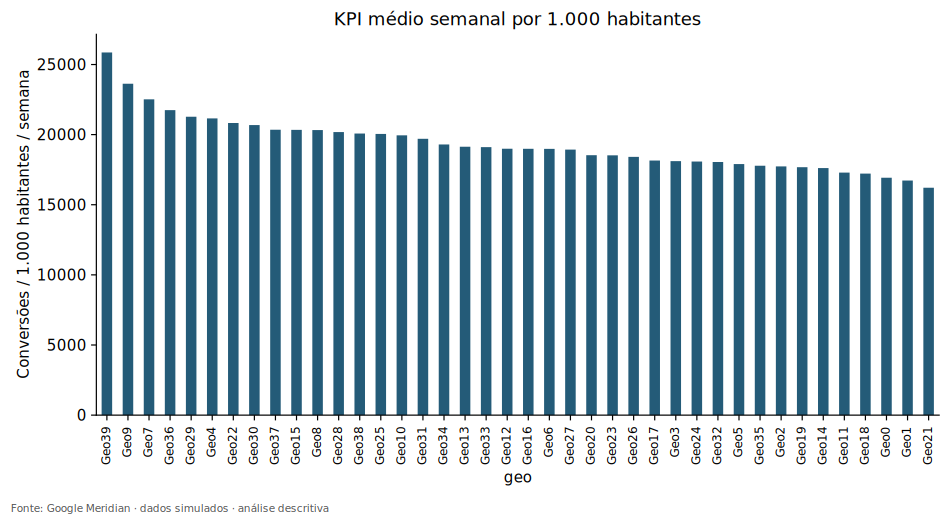

**kpi_small_multiples** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

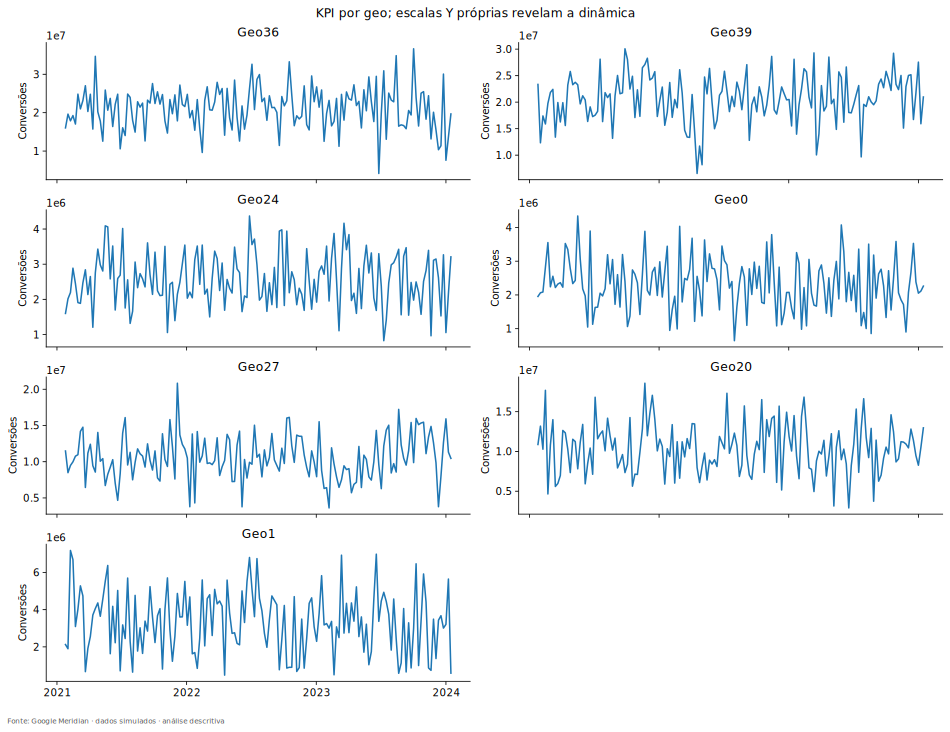

**population_by_geo** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

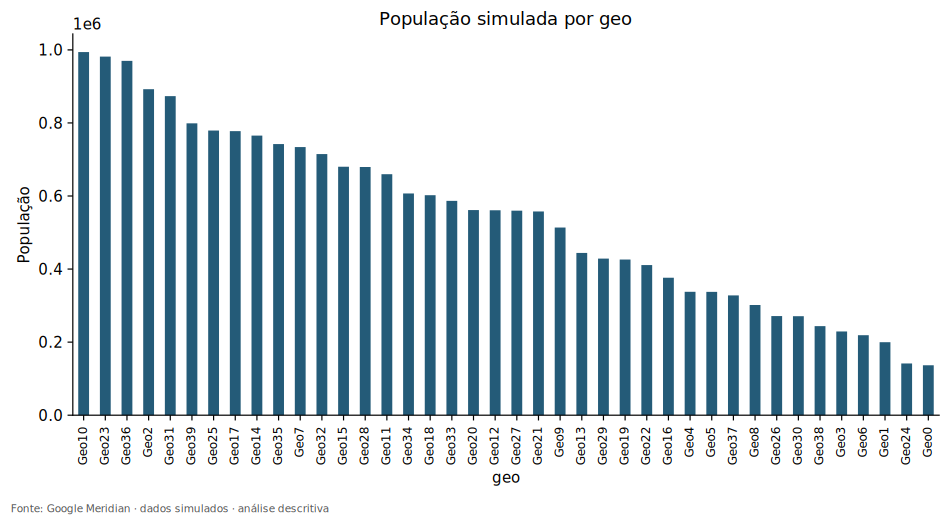

**population_kpi** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

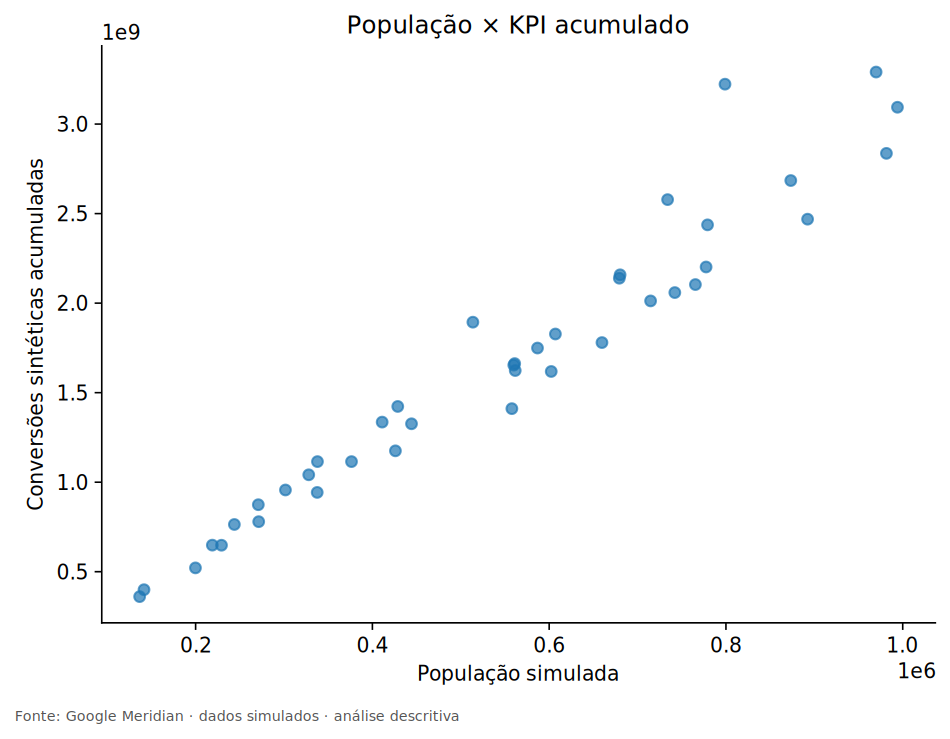

**sentiment_score_control_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

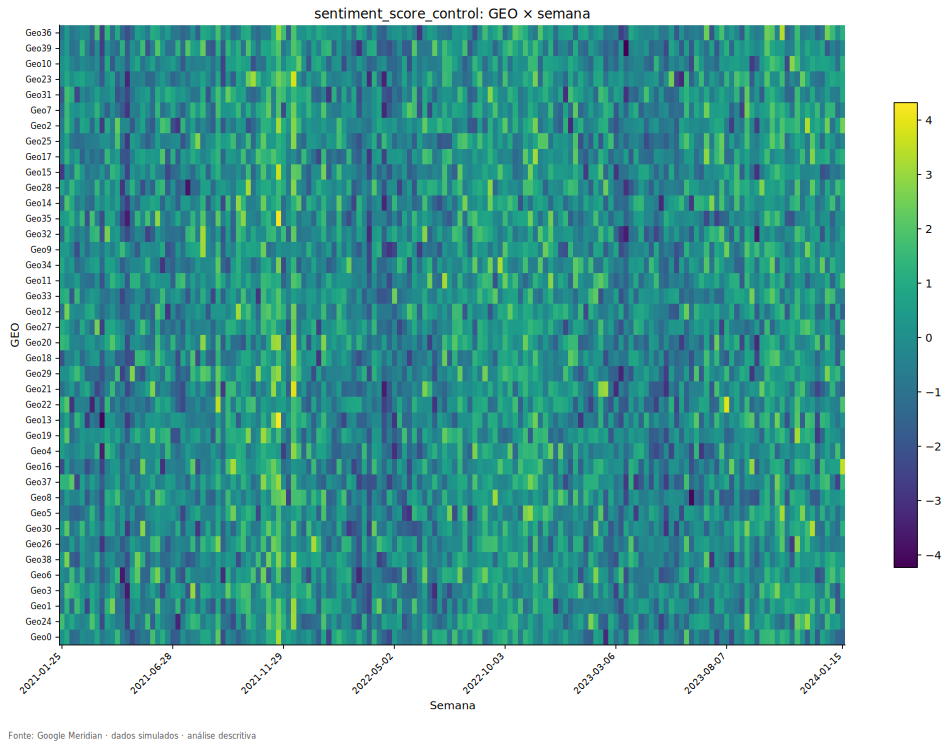

**variance_decomposition** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

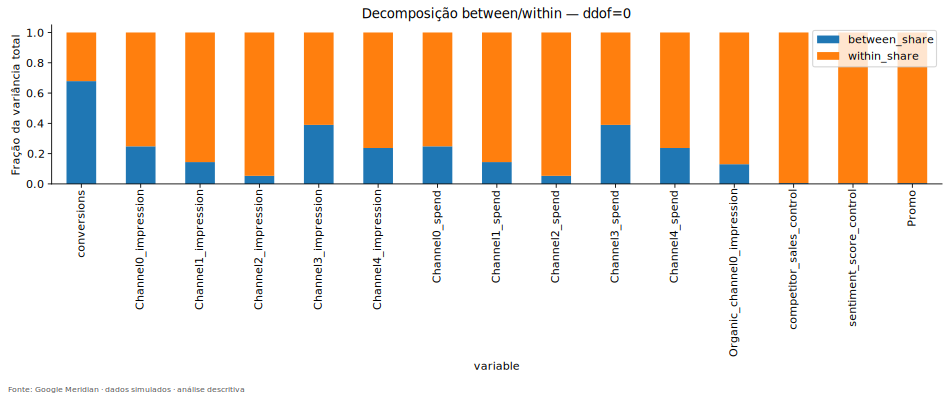

In [ ]:
show(report_03, part="evidence")


---
## Seção executável 04 — Mídia no espaço e no tempo

## Capítulo 10 — Onde o orçamento aparece

Na abertura imaginamos alguém tentando decidir se a publicidade ajudou. Antes de avaliar uma decisão, precisamos conhecer o tamanho e a distribuição dessa decisão. Um canal que quase não recebe investimento e outro que concentra boa parte do orçamento oferecem histórias observacionais diferentes.

Somando o gasto de todo o período, `Channel3` recebe cerca de **40%** do orçamento dos cinco canais pagos. `Channel2` recebe aproximadamente **5,5%**. Os demais ficam entre esses extremos, como mostra a [participação no gasto](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/general/spend_share.svg). Essa diferença informa onde o dinheiro foi colocado. Não informa onde ele trouxe mais retorno.

Para recuperar os endereços do investimento, cruzamos mercados e canais. No gráfico abaixo, cada linha pertence a um mercado e cada coluna a um canal. A cor representa o gasto acumulado no período. Esse tipo de mapa de cores é chamado de **heatmap**. Não é um mapa geográfico de cidades; é uma maneira de tornar uma tabela visível.

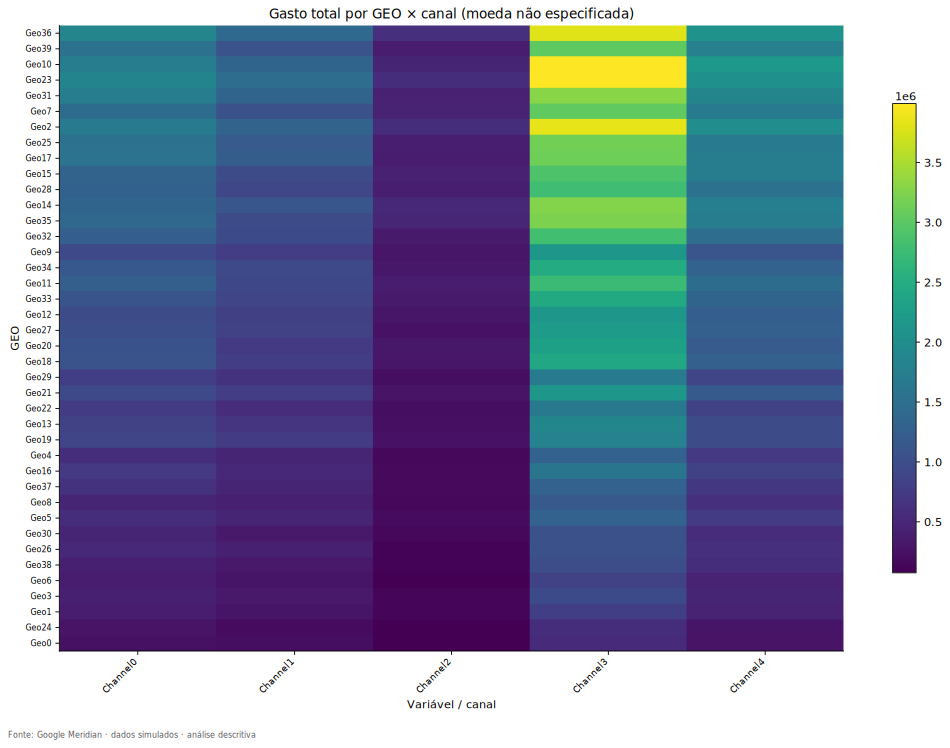

A coluna de `Channel3` ganha destaque pelo orçamento maior. As diferenças entre linhas também merecem atenção, mas já aprendemos a não interpretá-las sem considerar tamanho. As [comparações entre população e mídia](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/population_media_correlation.csv) mostram forte associação dos volumes acumulados com a população. O [quadro de gasto por mil habitantes](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/media_geo/spend_per_capita.svg) oferece a lente complementar.

Outra pergunta é se o orçamento de um canal está quase todo concentrado em poucos mercados. Neste projeto, os cinco maiores destinos de cada canal recebem, em conjunto, aproximadamente **21% a 23%** de seu gasto. Há concentração em relação a uma divisão perfeitamente uniforme, mas não uma situação em que cinco lugares absorvem quase todo o orçamento.

O projeto também condensou essa desigualdade numa medida chamada **HHI**. Sua intuição é dar mais peso a participações grandes: quanto mais o orçamento se amontoa em poucos destinos, maior fica o indicador. A [tabela de concentração](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/channel_geo_concentration.csv) traduz o resultado para uma distribuição equivalente por cerca de 32 a 33 mercados iguais. Isso é uma imagem da concentração, não uma redução dos nossos 40 mercados a 32 observações independentes, nem uma regra de concorrência econômica.

Ainda falta entender a relação entre dinheiro e exposição. Se dois mercados gastam a mesma quantia, podem receber quantidades diferentes de mídia. Para conferir, o projeto relacionou gasto e unidades de exposição, produzindo o **custo por unidade de mídia**, ou **CPMU**. Nesta base, a unidade é uma impressão; não é o custo por mil impressões.

Os [custos por canal](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/cost_per_media_unit.csv) são praticamente constantes dentro de cada canal. Por isso, seus gráficos de gasto e exposição se parecem tanto. Nas semanas sem impressões, o custo unitário fica indefinido: não houve exposição sobre a qual repartir o gasto. A ausência de um valor para essa razão não deve ser transformada em “mídia gratuita”. E, no agregado, o custo é obtido pelo gasto total em relação à exposição total, não por uma média simples de custos locais que daria o mesmo peso a volumes muito diferentes.

Temos, portanto, a dimensão do orçamento e sua ligação próxima com exposição. Mas observar a tabela de mercados e canais ainda permite duas leituras diferentes. Precisamos escolher de qual direção vamos olhar para ela.

## Capítulo 11 — O orçamento visto de duas direções

Entre em um mercado e imagine abrir apenas o orçamento dele. Quanto foi para cada um dos cinco canais? Se o mercado fosse maior e todo seu orçamento dobrasse, mantendo as proporções, a resposta continuaria igual. Estamos perguntando pela composição interna, não pelo tamanho.

Essa composição é o **media mix**. No gráfico abaixo, cada barra representa todo o orçamento de um mercado e suas partes mostram como ele foi dividido. As barras têm a mesma altura porque todas representam 100% do respectivo orçamento, mesmo quando os valores monetários são muito diferentes.

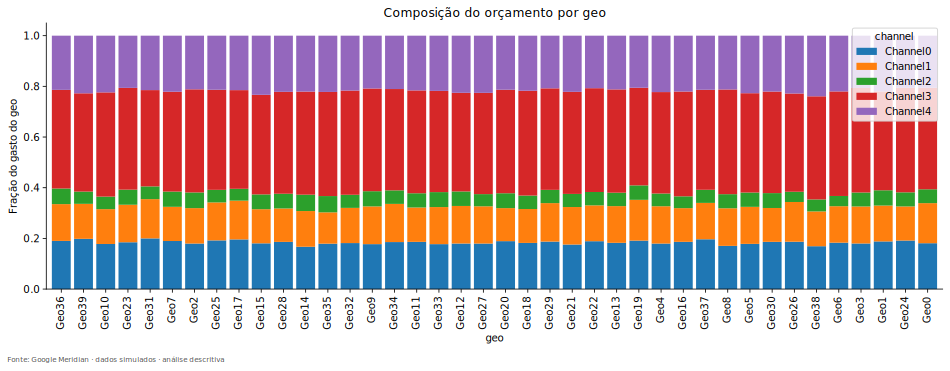

As barras são parecidas. `Channel3` ocupa aproximadamente 38% a 41% do orçamento de cada mercado; `Channel2`, cerca de 4% a 6,5%. A maior distância entre a menor e a maior participação territorial de um canal ocorre em `Channel1`: **3,74 pontos percentuais**. Dizer pontos percentuais é necessário porque estamos subtraindo participações, não calculando um crescimento relativo.

Essa descoberta freia uma interpretação fácil. Temos quarenta mercados, mas os orçamentos acumulados não revelam quarenta composições radicalmente diferentes. O [gráfico de desvios do mix nacional](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/media_geo/mix_deviations_pp.svg) ajuda a enxergar as pequenas diferenças sem exagerá-las. A [síntese por canal](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/channel_geo_interpretation.csv) registra seus intervalos e relaciona a leitura à população.

Agora saia desse mercado e acompanhe um único canal. De todo o dinheiro investido nele, quanto foi para cada endereço? Mudamos o total de referência: antes era o orçamento do mercado; agora é o orçamento do canal. Essa segunda leitura é a **alocação geográfica**, ou **geo allocation**.

Pense num exemplo hipotético com apenas dois mercados. O maior pode ter dez vezes o orçamento do menor, e ambos podem destinar metade ao mesmo canal. Eles têm o mesmo mix, mas o maior absorve uma parcela muito maior do dinheiro total desse canal. Não há contradição: as perguntas são diferentes.

O [heatmap de alocação](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/media_geo/geo_allocation.svg) faz essa segunda leitura. Para conferir sua lógica, somamos as participações de um canal ao longo dos mercados e chegamos ao total desse canal. No [mix](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/media_mix.csv), a composição se fecha dentro de cada mercado; na [alocação](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/geo_allocation.csv), a distribuição se fecha dentro de cada canal. Não precisamos de fórmulas para lembrar a distinção: primeiro escolhemos o orçamento cuja divisão queremos conhecer.

A semelhança do mix acumulado não encerra a investigação. Dois mercados podem terminar três anos com composições parecidas e ter distribuído os anúncios em semanas completamente diferentes. Tudo que somamos ao longo do período apagou o calendário. Para entender a variação local encontrada antes, precisamos devolvê-lo ao mapa de mídia.

## Capítulo 12 — O calendário dos canais

Imagine um calendário em que cada linha pertence a um mercado. As colunas são semanas, e cada quadrado mostra a intensidade de exposição naquele lugar e momento. Uma faixa vertical pode indicar uma semana movimentada em vários mercados; uma faixa horizontal persistente, um lugar que costuma ter intensidade maior. Blocos localizados sugerem movimentos restritos a partes do painel.

Começaremos por `Channel2`, que tinha pouca participação no orçamento e muita variação dentro dos mercados. O gráfico usa exposição por mil habitantes, para que o tamanho populacional não domine a leitura. As cores próximas ao extremo inferior da escala incluem os zeros; apenas a tabela permite distinguir exatamente zero de um valor positivo pequeno.

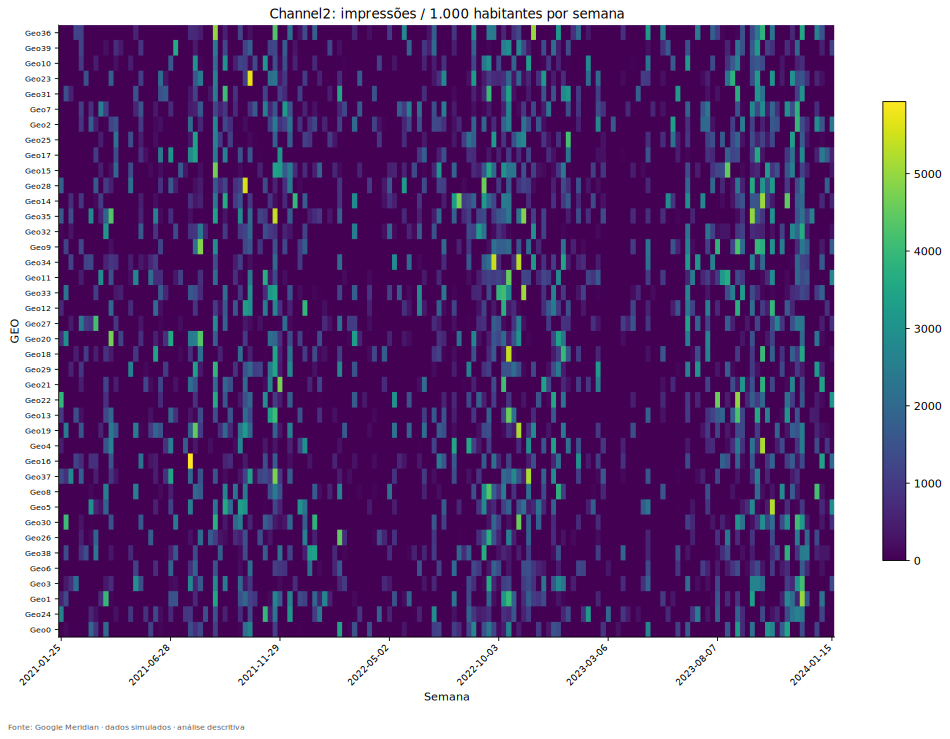

O calendário é marcado por interrupções. Conferindo as células, **64,3% das combinações de mercado e semana não têm exposição desse canal**. Mesmo assim, todos os 40 mercados receberam `Channel2` em algum momento. Estar presente em todos os mercados ao longo de três anos é muito diferente de estar presente em todos eles em cada semana.

Também seria enganoso olhar apenas para as semanas nacionais zeradas. Existem somente quatro: 26 de abril de 2021, 25 de julho de 2022, 15 de maio de 2023 e 19 de junho de 2023. Nas outras, basta algum mercado ter exposição para o total nacional ser positivo. Assim, a linha nacional esconde grande parte das ausências locais.

Quando muitos registros ficam em zero, dizemos que o sinal é **esparso**, ou usamos o termo inglês **sparsity**. Não é um defeito automático. Alternar presença e ausência pode oferecer contrastes interessantes. Mas precisamos de períodos observados suficientes, e a razão de a mídia ter aparecido em cada lugar continua desconhecida. Uma alternância registrada não equivale a um experimento aleatório.

Em `Channel2`, cada mercado esteve ativo em aproximadamente **28% a 44% das semanas**, e a maior sequência local sem exposição chegou a **27 semanas**. Esses detalhes, disponíveis no [estudo de atividade](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/activity_intensity_summary.csv) e nas [sequências](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/activity_runs.csv), ajudam a entender por que uma futura janela de avaliação pode ter pouco contato com o canal.

Para perceber o contraste, olhemos `Channel3` com a mesma organização de linhas e semanas. A escala de cores é própria deste gráfico: uma cor igual nos dois painéis não garante a mesma quantidade de impressões. O que podemos comparar diretamente é a distribuição do movimento e da atividade.

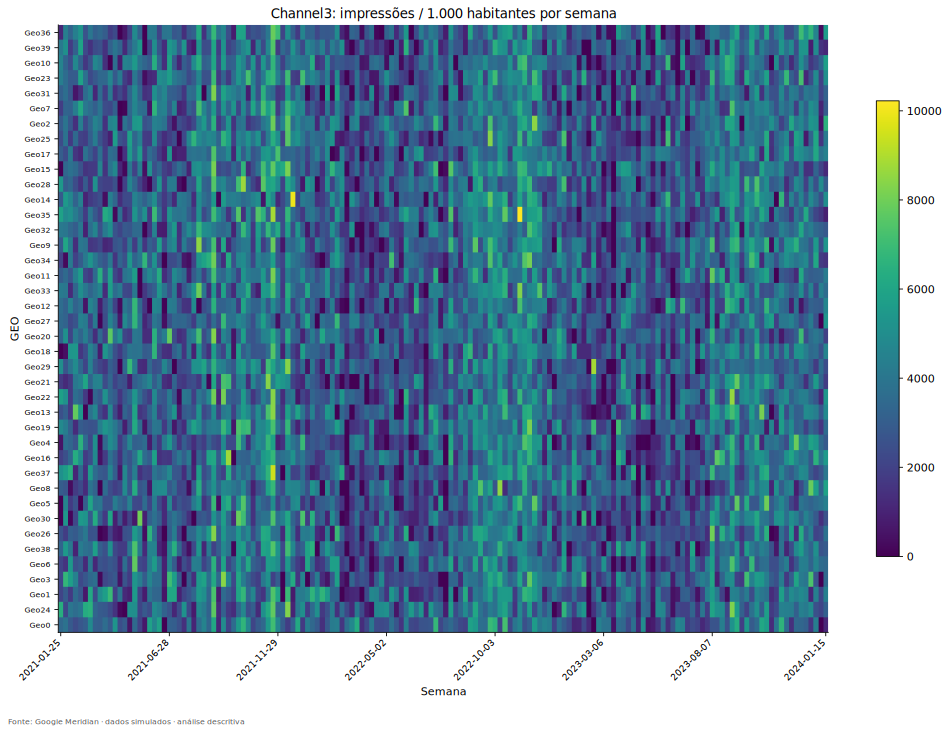

Aqui a presença é muito mais contínua: somente **2,7% das células** estão zeradas, e há uma sequência local de até **127 semanas ativas**. Nenhum desses resultados determina qual canal é melhor. Eles mostram que os dois oferecem tipos diferentes de comparação ao longo do tempo.

A diferença também esclarece uma ambiguidade da palavra “variar”. Um canal pode variar porque alterna zero e exposição positiva ou porque muda bastante de intensidade mesmo quando já está ativo. Para separar as duas situações, o projeto examinou a dispersão nas semanas positivas e a alternância entre presença e ausência.

Uma medida usada nessa comparação coloca a oscilação em relação ao nível médio: o **coeficiente de variação**, ou **CV**. Em `Channel2`, a mediana do CV dos mercados é aproximadamente 1,88 quando incluímos todas as semanas, mas cai para 0,81 quando olhamos somente as semanas ativas. Há variação de intensidade, porém boa parte da impressão inicial de oscilação vinha da entrada e saída de atividade.

A decomposição específica confirma isso: aproximadamente **metade da variância dentro dos mercados** de `Channel2` corresponde ao componente de alternância zero/positivo. Em `Channel3`, esse componente fica perto de **10,5%**. São parcelas da variação *within*, não do resíduo após retirar também as semanas comuns, e muito menos parcelas de conversões causadas pelos canais.

Uma revisão da EDA aprofundou esse ponto justamente porque o percentual de zeros sozinho não respondia à pergunta. Também corrigiu a ordenação dos mercados após a divisão por população, para permitir acompanhar o mesmo endereço entre os painéis. Uma linha trocada poderia parecer uma descoberta territorial; manter os endereços comparáveis faz parte de ler corretamente a imagem.

Agora conseguimos descrever onde e quando a mídia aparece. Falta uma questão que os calendários de um canal por vez não resolvem: quando um se movimenta, os outros fazem o mesmo?

### Duas perguntas, dois denominadores

Se $S_{g,c}$ é o gasto acumulado do canal $c$ no geo $g$, o mix é $S_{g,c}/\sum_c S_{g,c}$: cada linha soma um. A alocação é $S_{g,c}/\sum_g S_{g,c}$: cada coluna soma um. Esses denominadores são a diferença entre perguntar “como este mercado dividiu seu orçamento?” e “onde este canal investiu?”.

O HHI soma as participações geográficas ao quadrado. Seu inverso é o número equivalente de mercados com participações iguais, não o tamanho de uma amostra independente. Os heatmaps usam a mesma ordem de geos antes e depois de dividir por população. Todos os canais, incluindo seus gastos e impressões, são exibidos abaixo; nada exige abrir um apêndice externo.

### Preservar os endereços após dividir

A divisão alinha o índice pela população e reaplica explicitamente a ordem dos geos.

Código original de `src/geo_analysis.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def per_capita_matrix(matrix,population,order):
    return (matrix.div(population,axis=0)*1000).reindex(order)


### Ligar mix, população e resíduo

A síntese por canal põe lado a lado volume, intensidade, dispersão do mix e decomposições.

Código original de `src/investigation.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def media_investigation(p):
    mix=read('media_mix',index_col=0);national_share=read('channel_summary').set_index('channel').spend_share
    raw=read('geo_time_r2').set_index('variable');pc=read('geo_time_r2_per_capita').set_index('variable');pop=p.groupby(GEO)[POP].first();rows=[]
    for c in channels(p):
        col=c+'_impression';m=p.groupby(GEO)[col].sum()
        rows.append(dict(channel=c,mix_min_percent=100*mix[c].min(),mix_max_percent=100*mix[c].max(),mix_range_pp=100*(mix[c].max()-mix[c].min()),mix_std_pp=100*mix[c].std(ddof=0),population_corr_raw=pop.corr(m,method='spearman'),population_corr_per_capita=pop.corr(m/pop,method='spearman'),r2_geo_raw=raw.loc[col,'r2_geo'],r2_geo_per_capita=pc.loc[col,'r2_geo'],residual_raw=raw.loc[col,'residual_geo_time_share'],residual_per_capita=pc.loc[col,'residual_geo_time_share']))
    delta=100*(mix-national_share);limit=delta.abs().max().max()
    return export(pd.DataFrame(rows),'channel_geo_interpretation'),[heatmap(delta,'media_geo','mix_deviations_pp','Mix do GEO menos mix nacional — pontos percentuais','RdBu_r',-limit,limit)]


### Código completo desta etapa

A implementação abaixo foi transportada de `src/geo_analysis.py` (`media_geo`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('04')
def media_geo(panel):
    paid=channels(panel)
    population=panel.groupby(GEO)[POP].first()
    order=panel.groupby(GEO)[KPI].sum().sort_values(ascending=False).index
    spend=panel.groupby(GEO)[[c+'_spend' for c in paid]].sum().reindex(order)
    spend.columns=paid;spend.columns.name='channel'
    mix=spend.div(spend.sum(axis=1).replace(0,np.nan),axis=0)
    allocation=spend.div(spend.sum(axis=0).replace(0,np.nan),axis=1)
    table(spend,'geo_media_summary');table(mix,'media_mix');table(allocation,'geo_allocation')
    figures=[heatmap(spend,'media_geo','spend_geo_channel','Gasto total por GEO × canal (moeda não especificada)'),
             heatmap(mix,'media_geo','media_mix','Mix: parcela do gasto de cada geo',vmin=0,vmax=1),
             heatmap(allocation,'media_geo','geo_allocation','Alocação: parcela de cada canal destinada ao geo',vmin=0,vmax=allocation.max().max()),
             heatmap(per_capita_matrix(spend,population,order),'media_geo','spend_per_capita','Gasto acumulado / 1.000 habitantes')]
    fig,ax=plt.subplots(figsize=(13,5));mix.plot.bar(stacked=True,ax=ax,width=.85)
    ax.set(title='Composição do orçamento por geo',ylabel='Fração do gasto do geo')
    figures.append(save(fig,'media_geo','mix_stacked'))
    cv_rows=[];correlations=[];concentration=[];cost_rows=[]
    for channel in paid:
        media_col=channel+'_impression';spend_col=channel+'_spend'
        med=panel.groupby(GEO)[media_col].agg(['sum','mean','std'])
        med['std']=panel.groupby(GEO)[media_col].std(ddof=0)
        cv=safe_divide(med['std'],med['mean'])
        for geo,value in cv.items():cv_rows.append(dict(channel=channel,geo=geo,cv=value))
        for method in ['pearson','spearman']:
            correlations.append(dict(channel=channel,method=method,population_media_correlation=population.corr(med['sum'],method=method)))
        shares=allocation[channel].sort_values(ascending=False)
        concentration.append(dict(channel=channel,hhi=(shares**2).sum(),effective_geos=1/(shares**2).sum(),top1=shares.iloc[0],top5=shares.head(5).sum()))
        figures.append(scatter(population,med['sum'].reindex(population.index),'media_geo',channel+'_population',channel+': população × mídia','População','Impressões acumuladas'))
        for col,label in [(media_col,'impressões'),(spend_col,'gasto')]:
            matrix=panel.pivot(index=GEO,columns=TIME,values=col).reindex(order)
            figures.append(heatmap(matrix,'media_geo',col+'_geo_time',f'{channel}: {label} por GEO × semana'))
            figures.append(heatmap(per_capita_matrix(matrix,population,order),'media_geo',col+'_pc_geo_time',f'{channel}: {label} / 1.000 habitantes por semana'))
        cost=panel.assign(cpmu=safe_divide(panel[spend_col],panel[media_col]))
        for geo,group in cost.groupby(GEO):
            cost_rows.append(dict(channel=channel,geo=geo,mean=group.cpmu.mean(),min=group.cpmu.min(),max=group.cpmu.max(),std=group.cpmu.std(ddof=0)))
    cvs=table(pd.DataFrame(cv_rows),'within_geo_cv',False)
    table(pd.DataFrame(correlations),'population_media_correlation',False)
    concentration=table(pd.DataFrame(concentration),'channel_geo_concentration',False)
    table(pd.DataFrame(cost_rows),'geo_cpmu',False)
    figures.append(heatmap(cvs.pivot(index='geo',columns='channel',values='cv').reindex(order),'media_geo','within_geo_cv','CV de mídia ao longo do tempo dentro de cada geo'))
    fig,ax=plt.subplots(figsize=(9,4));cvs.boxplot(column='cv',by='channel',ax=ax);fig.suptitle('');ax.set(title='Distribuição dos CVs within por canal',ylabel='Desvio padrão / média')
    figures.append(save(fig,'media_geo','within_cv_distribution'))
    spread=(mix.max()-mix.min()).sort_values(ascending=False)
    text=f'''O mix divide cada linha GEO × canal pelo orçamento total do geo; a alocação divide cada coluna pelo orçamento do canal. Essas perguntas são diferentes. A maior amplitude de share do mix é {100*spread.iloc[0]:.2f} pontos percentuais, em {spread.index[0]}.

HHI é a soma dos quadrados das participações geográficas de um canal: varia de 1/G (uniforme) a 1 (um único geo). Observamos {concentration.hhi.min():.3f} a {concentration.hhi.max():.3f}, sem aplicar limiares de concorrência econômica. O inverso traduz concentração em número equivalente de geos uniformes, não em tamanho amostral efetivo.

Os CVs within variam de {cvs.cv.min():.3f} a {cvs.cv.max():.3f}. Médias zero produzem CV indefinido. Heatmaps usam a mesma ordenação de geos por KPI total e escalas de cor próprias por variável; não comparar cores entre painéis sem ler as escalas. As versões por habitante ajudam a investigar diferenças que persistem além do tamanho dos mercados.'''
    return result('04_eda_media_geo',text,{'media_mix':mix,'geo_allocation':allocation,'concentration':concentration,'within_cv':cvs},figures,'Correlações entre canais e controles, VIF e conflitos com geo/tempo.')


In [ ]:
report_04 = media_geo(geo_time_panel)
show(report_04, part="summary")


### Resultado observado e conclusão parcial

O mix divide cada linha GEO × canal pelo orçamento total do geo; a alocação divide cada coluna pelo orçamento do canal. Essas perguntas são diferentes. A maior amplitude de share do mix é 3.74 pontos percentuais, em Channel1.

HHI é a soma dos quadrados das participações geográficas de um canal: varia de 1/G (uniforme) a 1 (um único geo). Observamos 0.030 a 0.031, sem aplicar limiares de concorrência econômica. O inverso traduz concentração em número equivalente de geos uniformes, não em tamanho amostral efetivo.

Os CVs within variam de 0.442 a 2.153. Médias zero produzem CV indefinido. Heatmaps usam a mesma ordenação de geos por KPI total e escalas de cor próprias por variável; não comparar cores entre painéis sem ler as escalas. As versões por habitante ajudam a investigar diferenças que persistem além do tamanho dos mercados.

**Mix relativamente semelhante:** dispersões são expressas em pontos percentuais; o gráfico de desvios do nacional expõe pequenas diferenças sem sugerir forte heterogeneidade acumulada.

Channel0: mix 16.70%–20.00%, amplitude 3.30 p.p., desvio 0.74 p.p.; Spearman população×volume 0.993, população×intensidade 0.286; R² GEO bruto/per capita 0.248/0.006; resíduo per capita 0.783.

Channel1: mix 12.36%–16.10%, amplitude 3.74 p.p., desvio 0.82 p.p.; Spearman população×volume 0.987, população×intensidade 0.047; R² GEO bruto/per capita 0.144/0.004; resíduo per capita 0.765.

Channel2: mix 4.04%–6.46%, amplitude 2.42 p.p., desvio 0.57 p.p.; Spearman população×volume 0.966, população×intensidade 0.206; R² GEO bruto/per capita 0.053/0.004; resíduo per capita 0.793.

Channel3: mix 38.00%–41.36%, amplitude 3.36 p.p., desvio 0.91 p.p.; Spearman população×volume 0.994, população×intensidade 0.142; R² GEO bruto/per capita 0.390/0.005; resíduo per capita 0.648.

Channel4: mix 20.56%–23.92%, amplitude 3.37 p.p., desvio 0.79 p.p.; Spearman população×volume 0.993, população×intensidade 0.232; R² GEO bruto/per capita 0.237/0.004; resíduo per capita 0.706.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Mix relativamente semelhante:** dispersões são expressas em pontos percentuais; o gráfico de desvios do nacional expõe pequenas diferenças sem sugerir forte heterogeneidade acumulada.
- **Quais problemas apareceram?** Resíduo pode conter alternância de atividade e ruído, não apenas sinal causal.
- **O que falta investigar?** Correlações entre canais e controles, VIF e conflitos com geo/tempo.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

**media_mix** — 40 linhas; CSV completo em `outputs/tables/`.

channel,Channel0,Channel1,Channel2,Channel3,Channel4
geo,,,,,
Geo36,0.190032,0.145227,0.061584,0.389280,0.213879
Geo39,0.198288,0.138034,0.048407,0.387838,0.227433
Geo10,0.177915,0.137524,0.049388,0.411376,0.223797
Geo23,0.184789,0.147995,0.059540,0.401638,0.206038
Geo31,0.199994,0.154922,0.050278,0.380017,0.214790
Geo7,0.189596,0.135009,0.060125,0.393955,0.221316
Geo2,0.179638,0.139828,0.061873,0.406928,0.211733
Geo25,0.192168,0.149787,0.049639,0.394906,0.213501
Geo17,0.195987,0.152988,0.046717,0.389405,0.214902


**geo_allocation** — 40 linhas; CSV completo em `outputs/tables/`.

channel,Channel0,Channel1,Channel2,Channel3,Channel4
geo,,,,,
Geo36,0.045798,0.045260,0.049764,0.043248,0.043739
Geo39,0.038196,0.034384,0.031265,0.034439,0.037175
Geo10,0.042522,0.042504,0.039579,0.045324,0.045387
Geo23,0.045338,0.046955,0.048981,0.045426,0.042895
Geo31,0.042802,0.042875,0.036079,0.037491,0.039006
Geo7,0.036130,0.033270,0.038417,0.034607,0.035787
Geo2,0.041837,0.042112,0.048317,0.043688,0.041844
Geo25,0.037912,0.038214,0.032836,0.035915,0.035742
Geo17,0.038819,0.039185,0.031025,0.035554,0.036118


**concentration** — 5 linhas; CSV completo em `outputs/tables/`.

...

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

**Channel0_impression_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

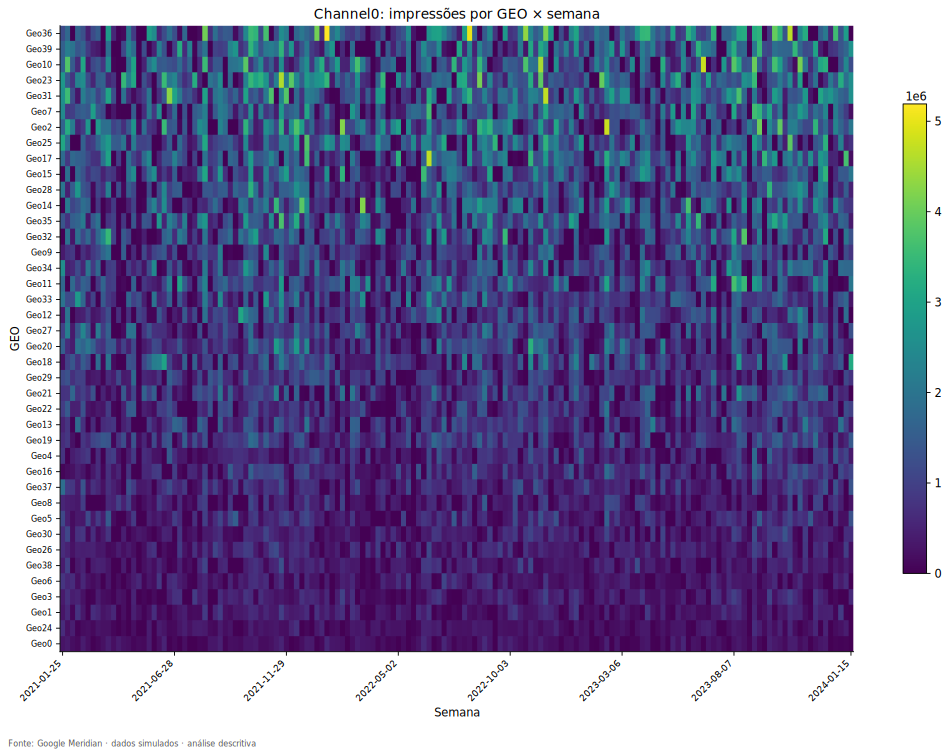

**Channel0_impression_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

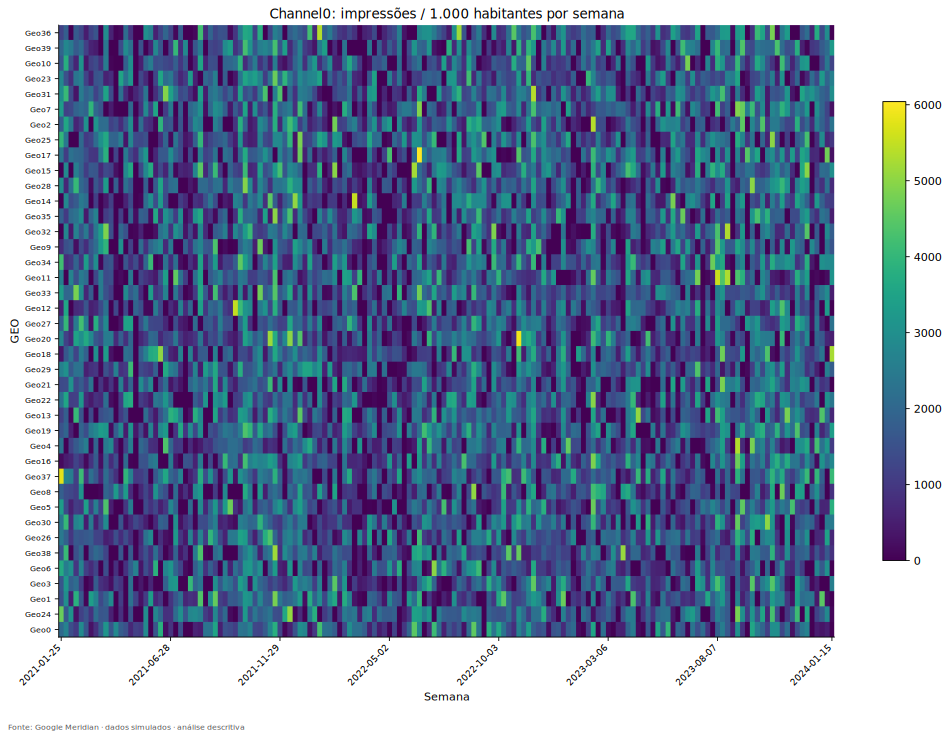

**Channel0_population** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

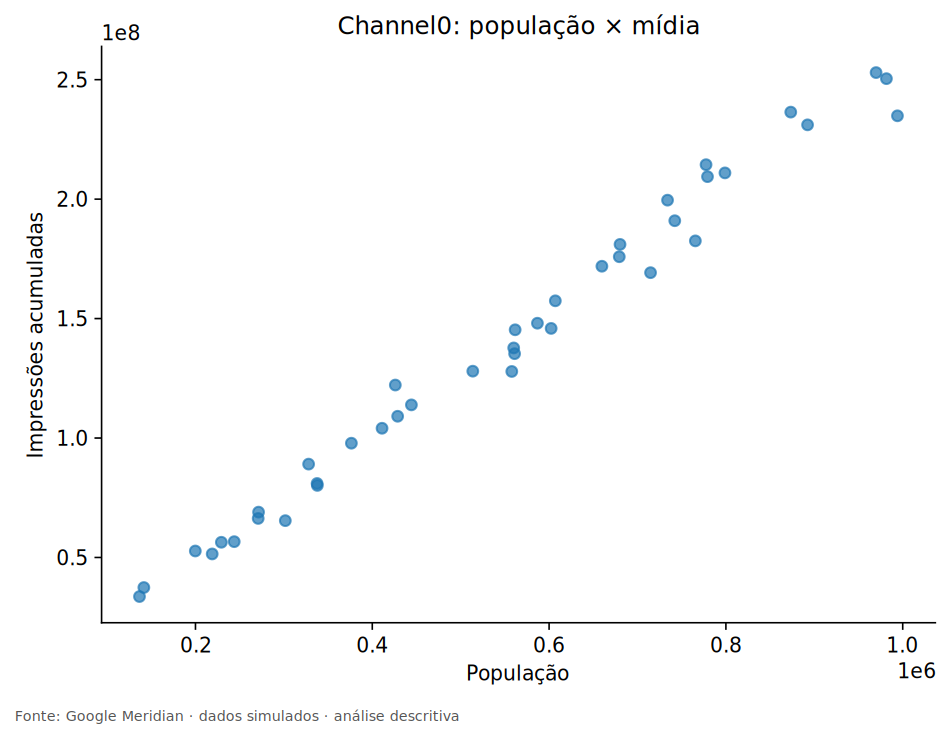

**Channel0_spend_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

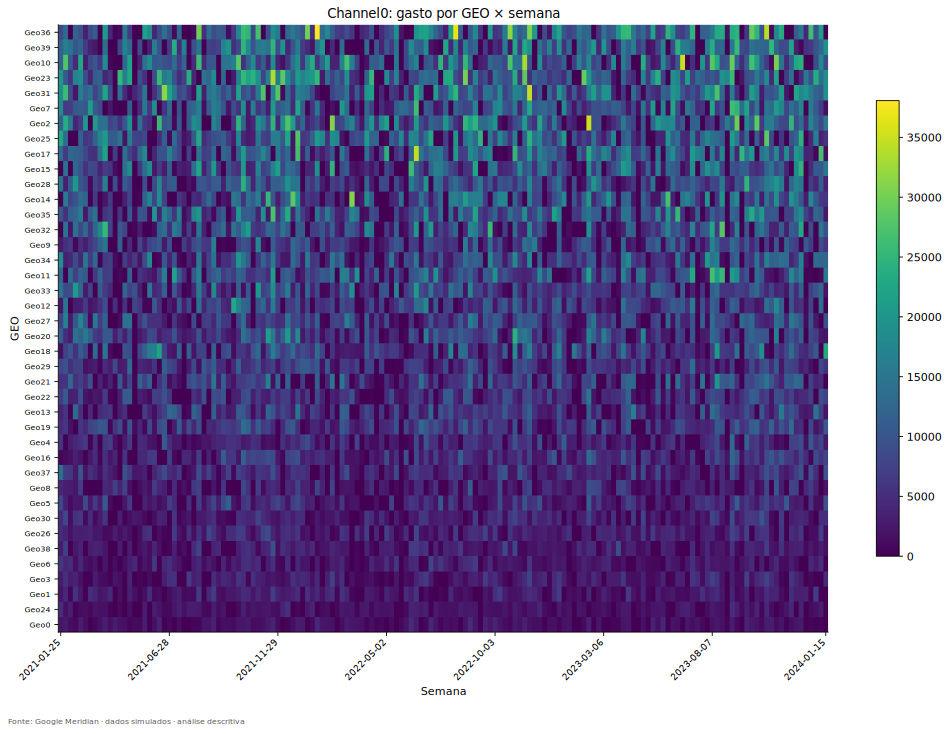

**Channel0_spend_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

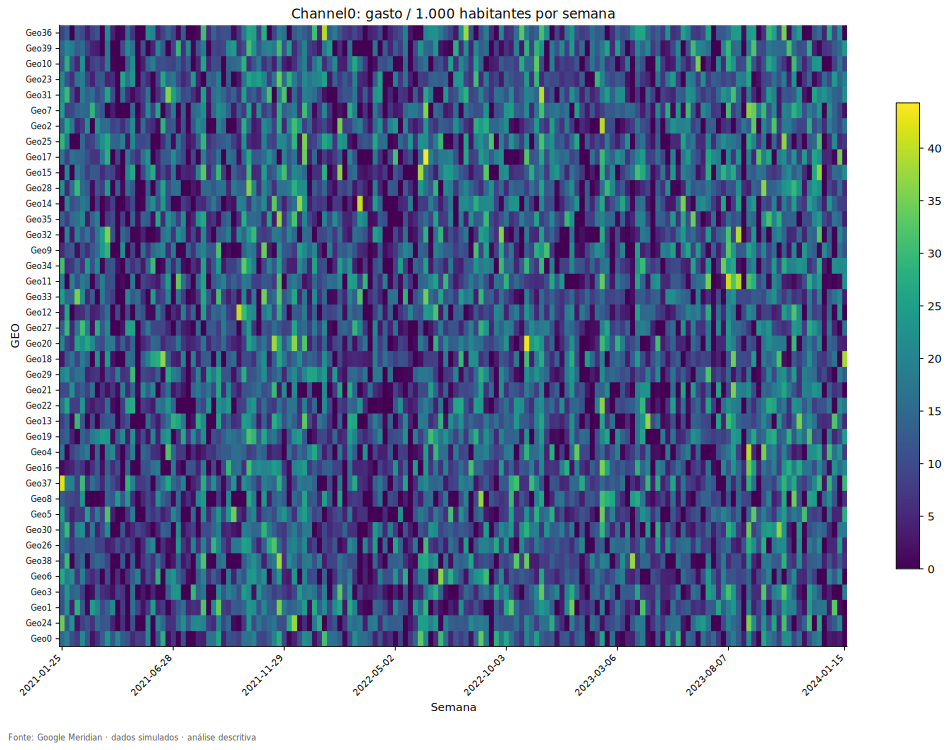

**Channel1_impression_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

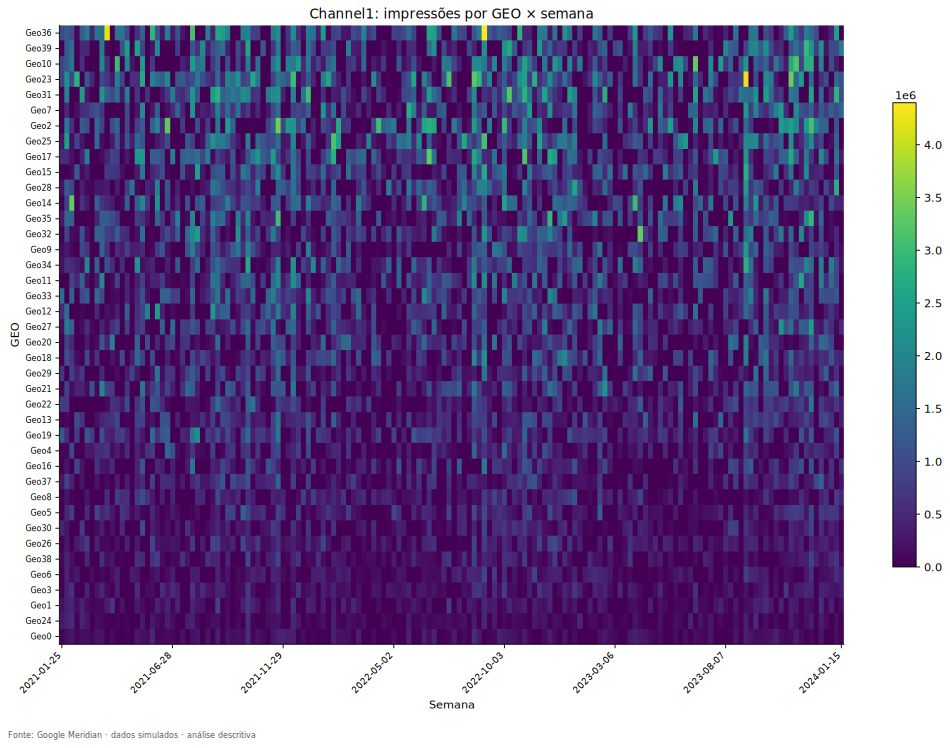

**Channel1_impression_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

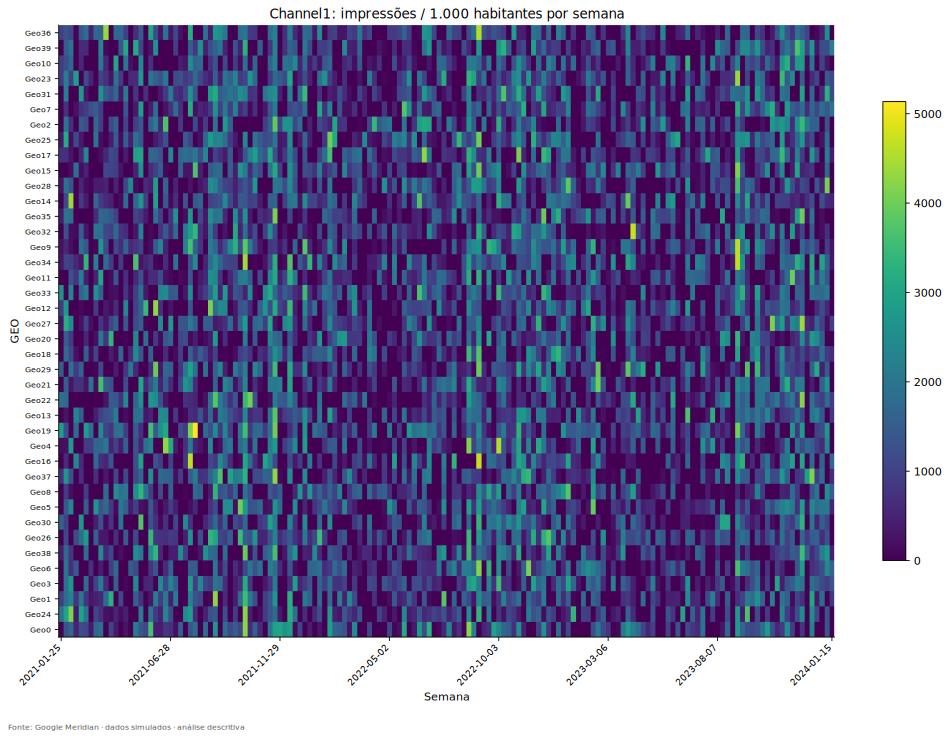

**Channel1_population** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

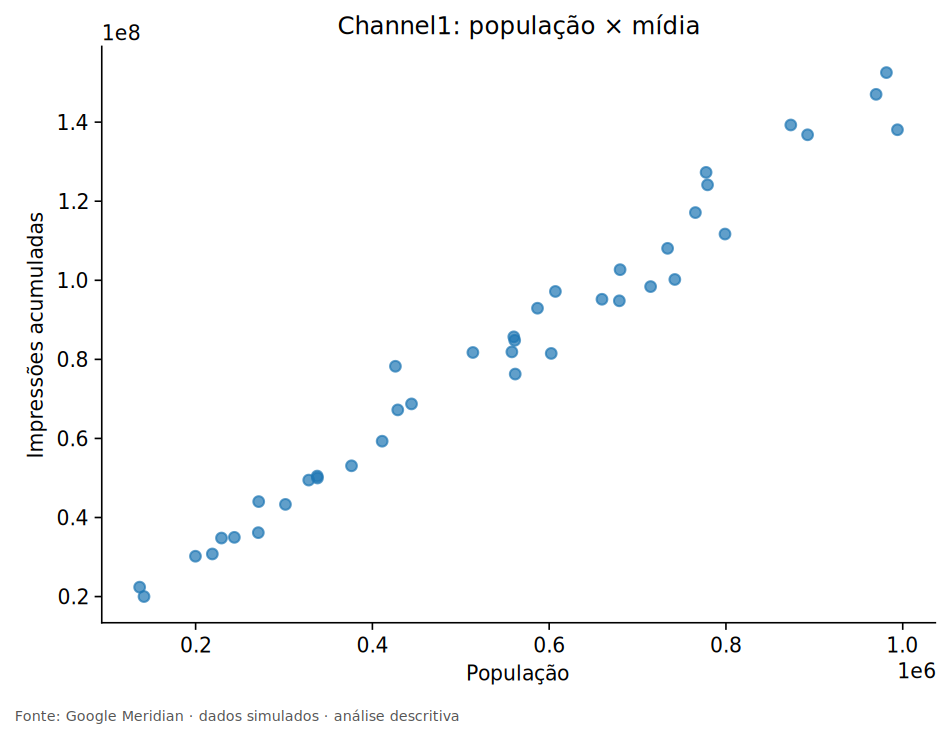

**Channel1_spend_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

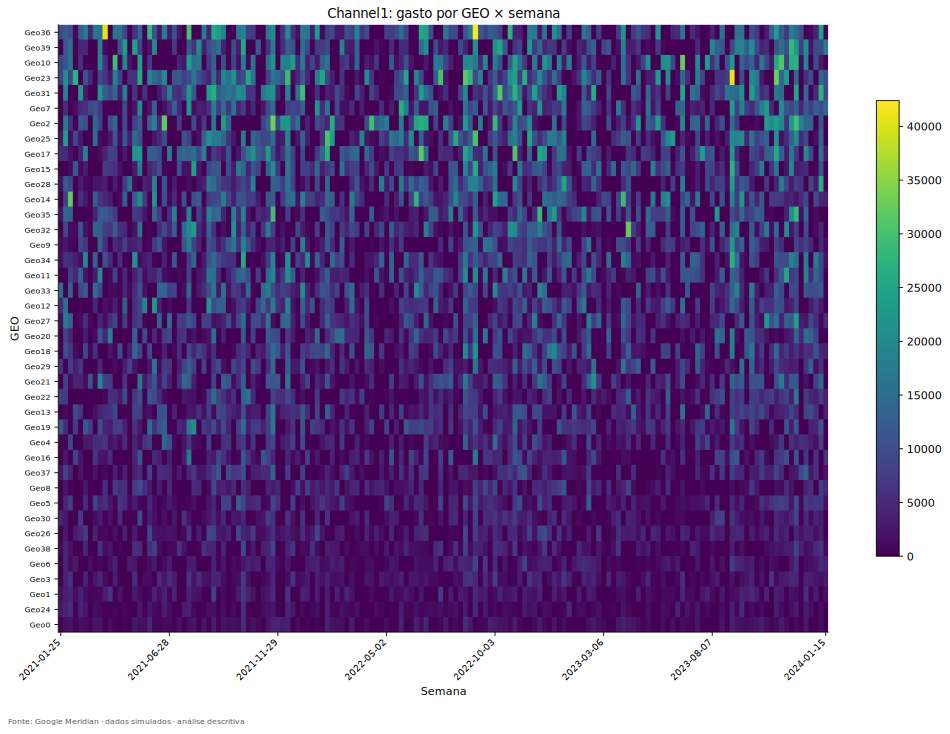

**Channel1_spend_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

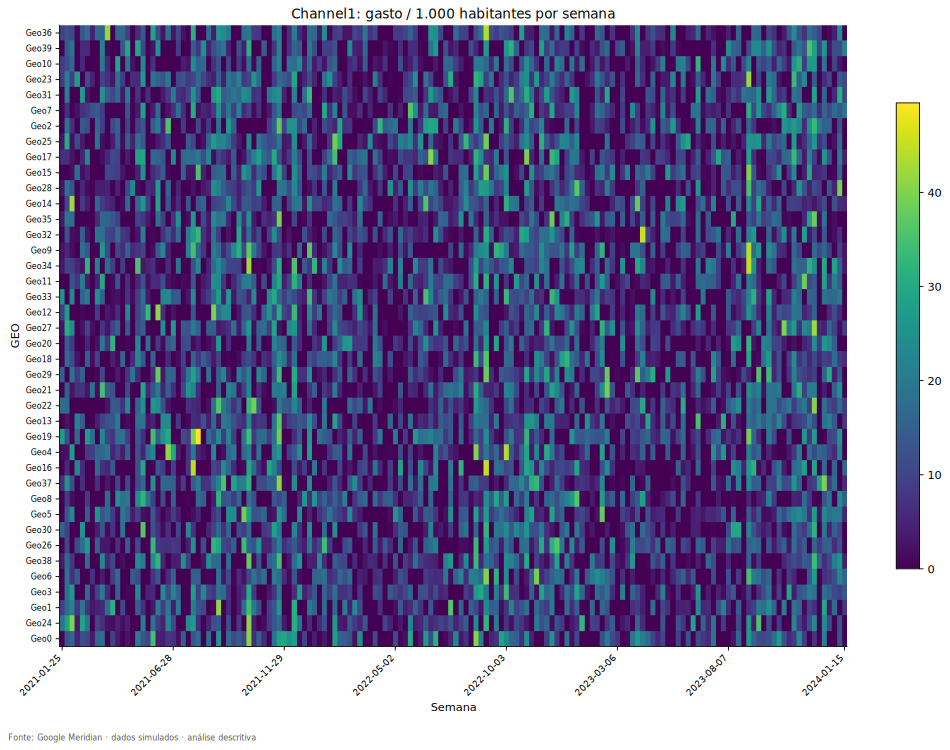

**Channel2_impression_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

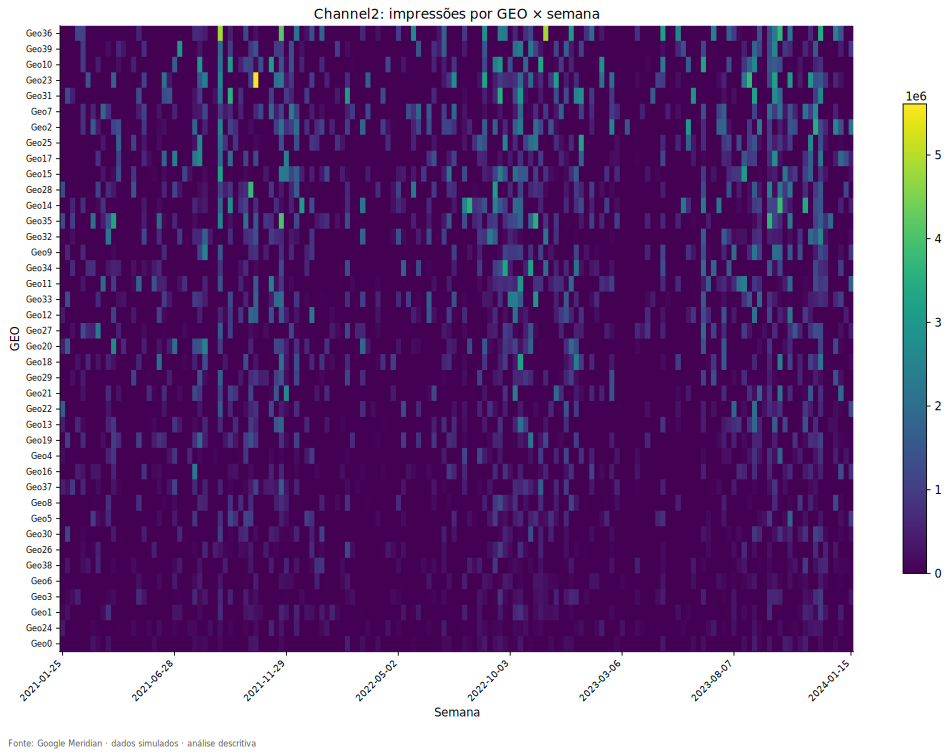

**Channel2_impression_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

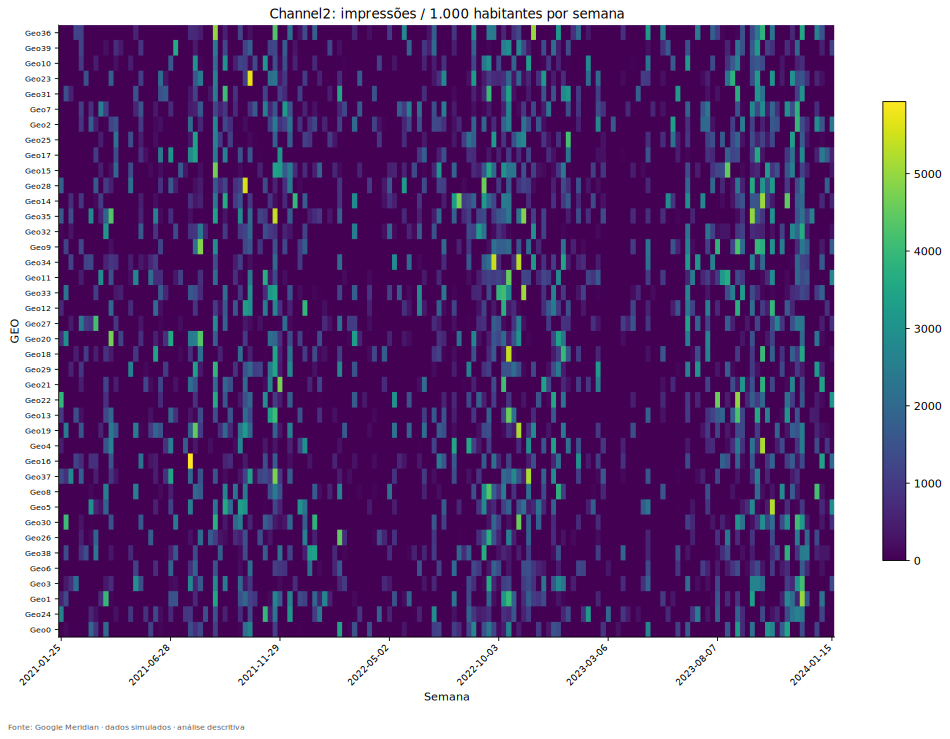

**Channel2_population** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

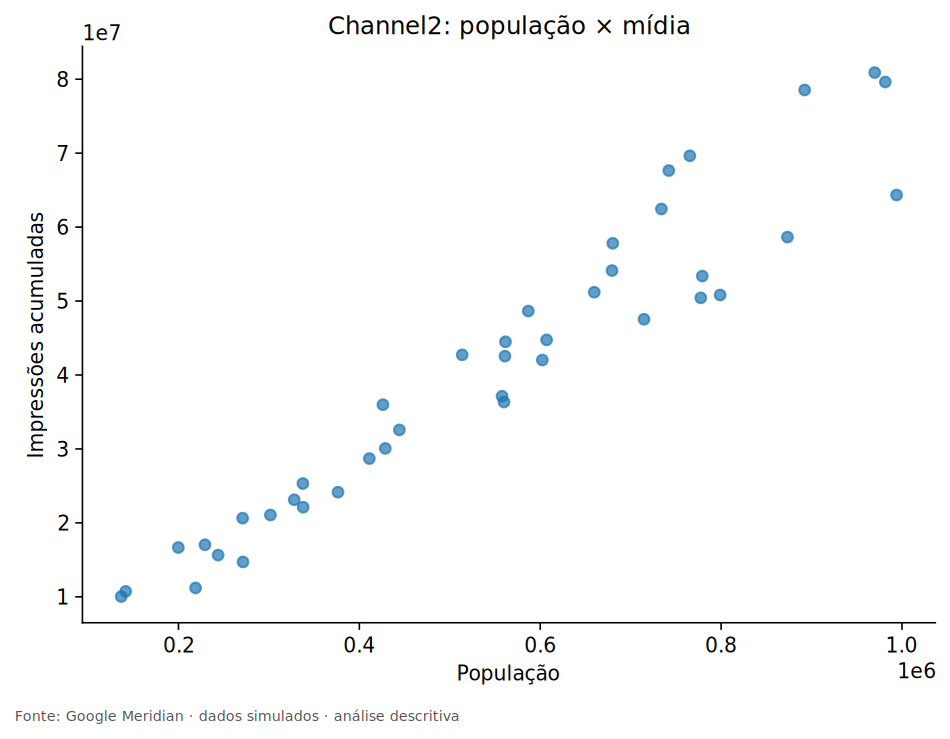

**Channel2_spend_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

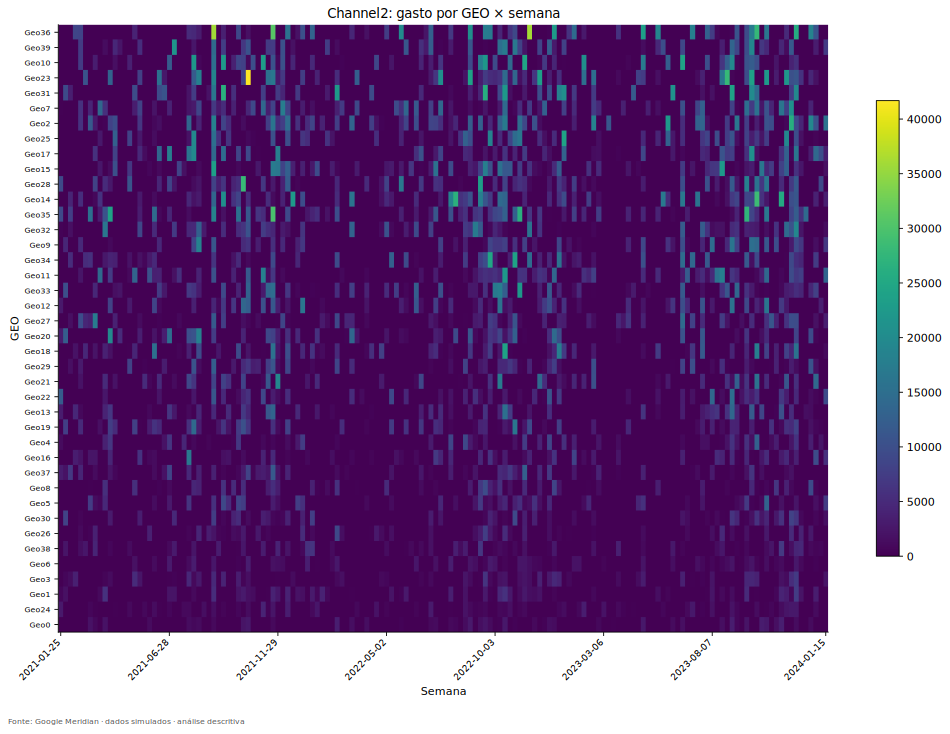

**Channel2_spend_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

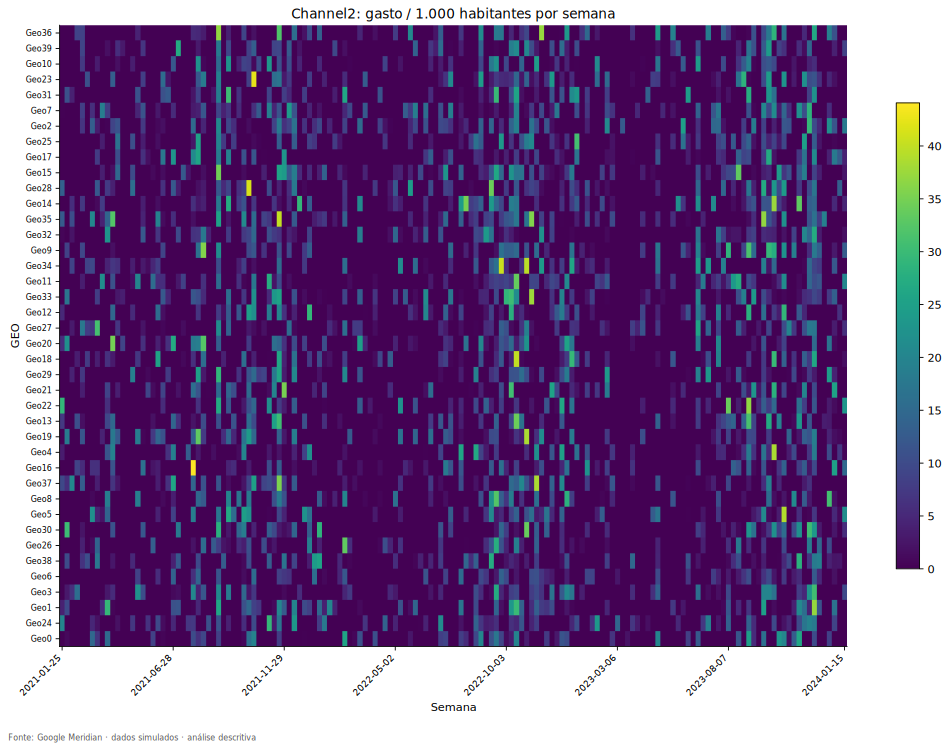

**Channel3_impression_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

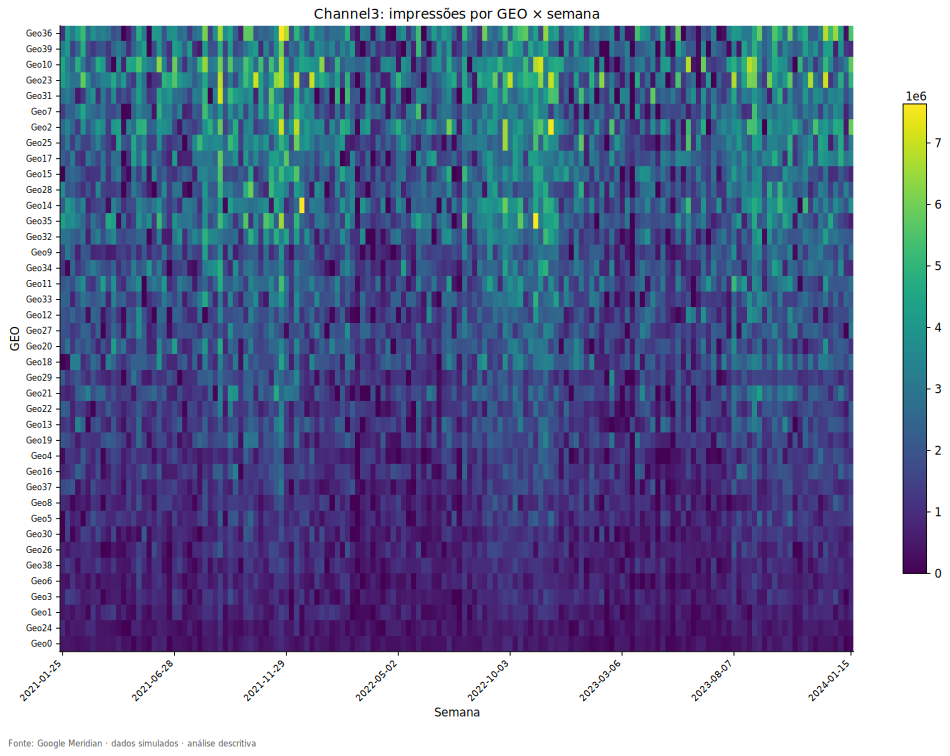

**Channel3_impression_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

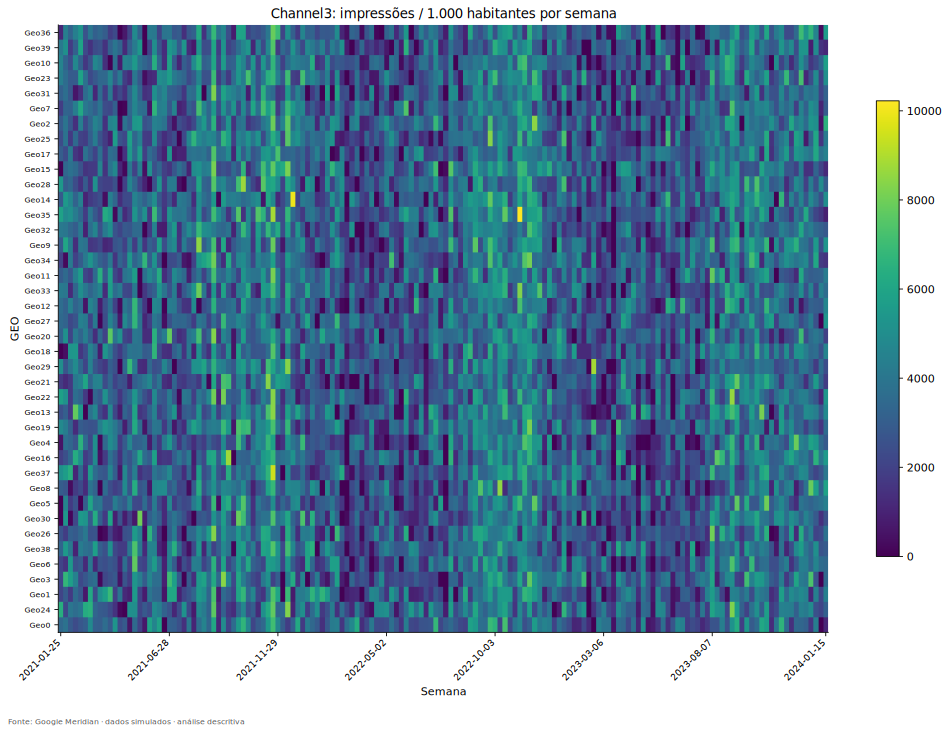

**Channel3_population** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

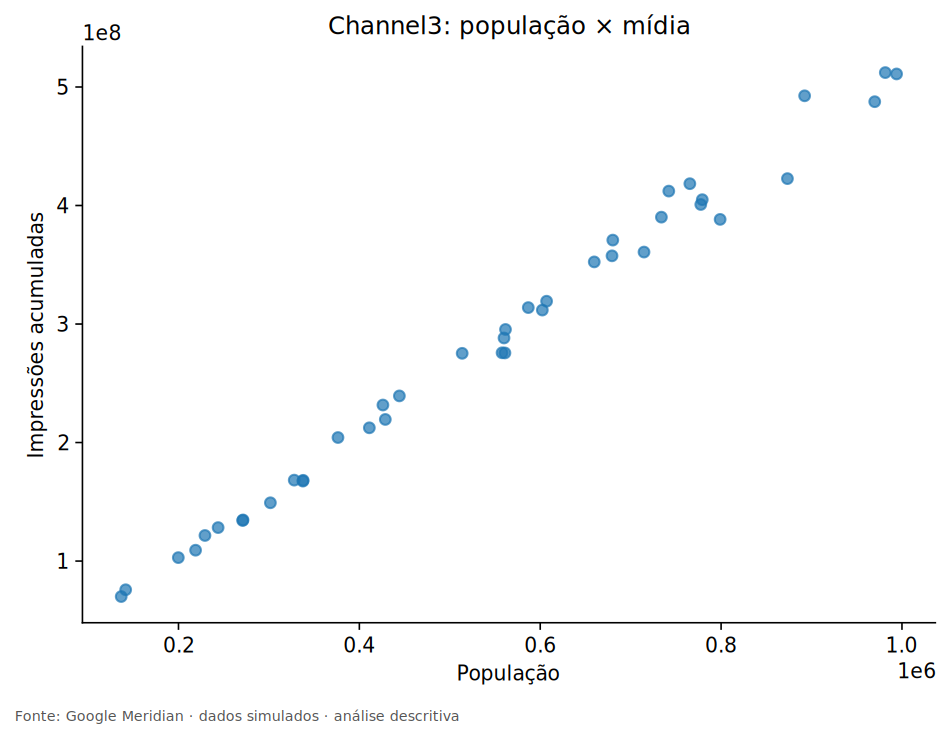

**Channel3_spend_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

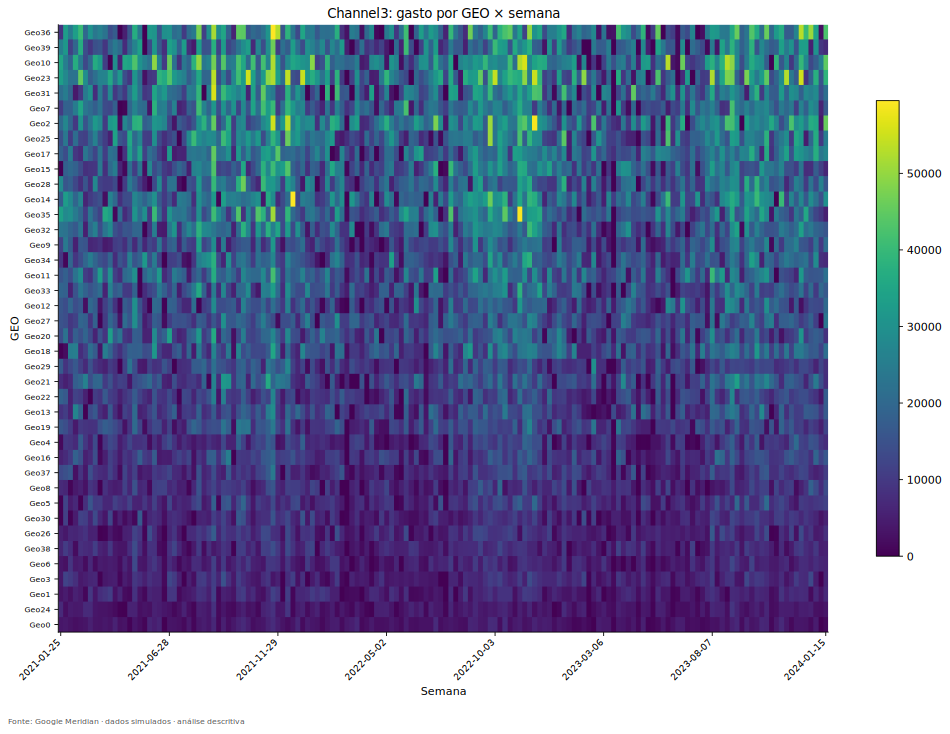

**Channel3_spend_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

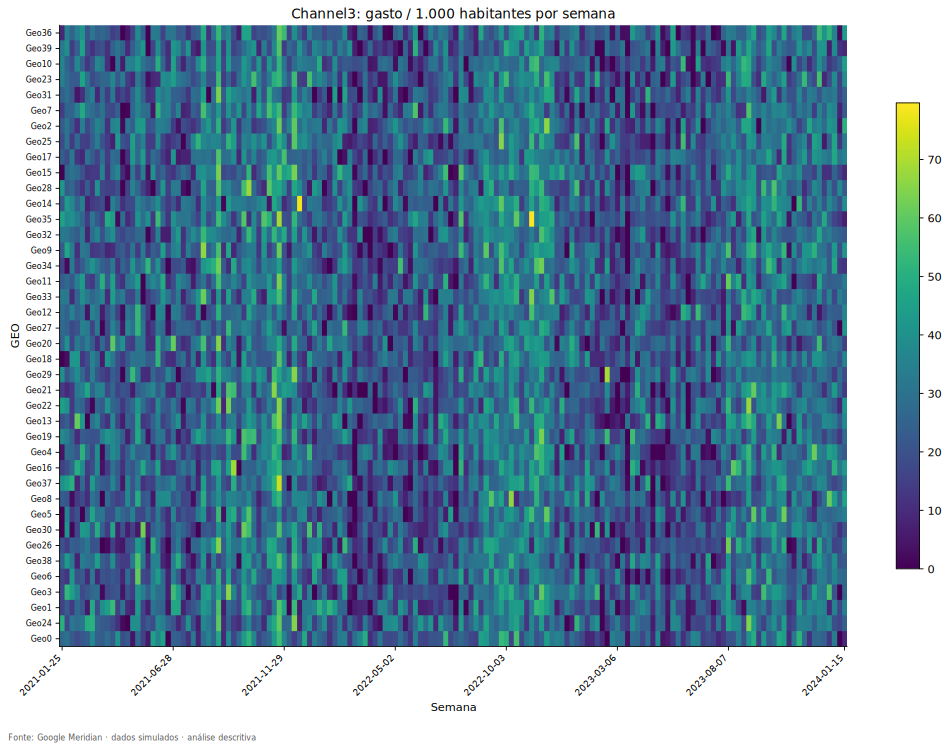

**Channel4_impression_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

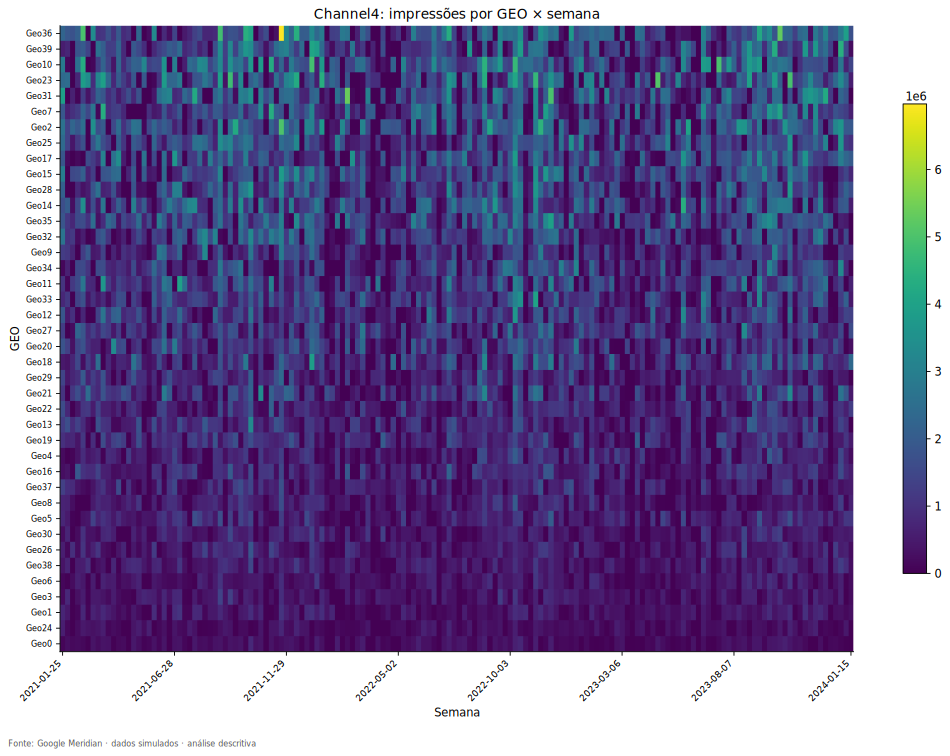

**Channel4_impression_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

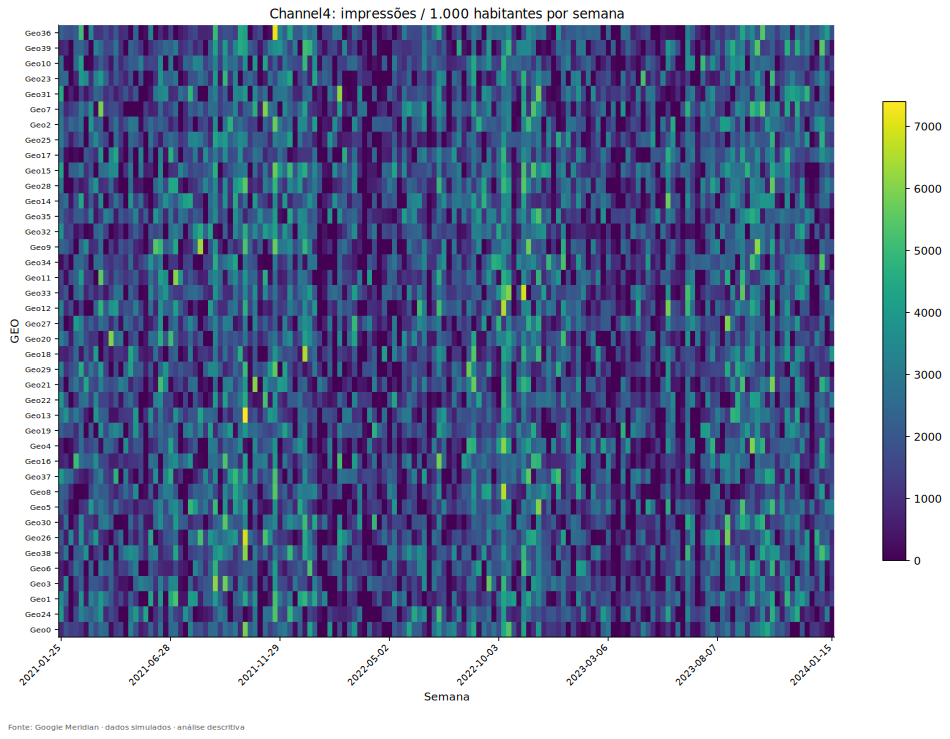

**Channel4_population** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

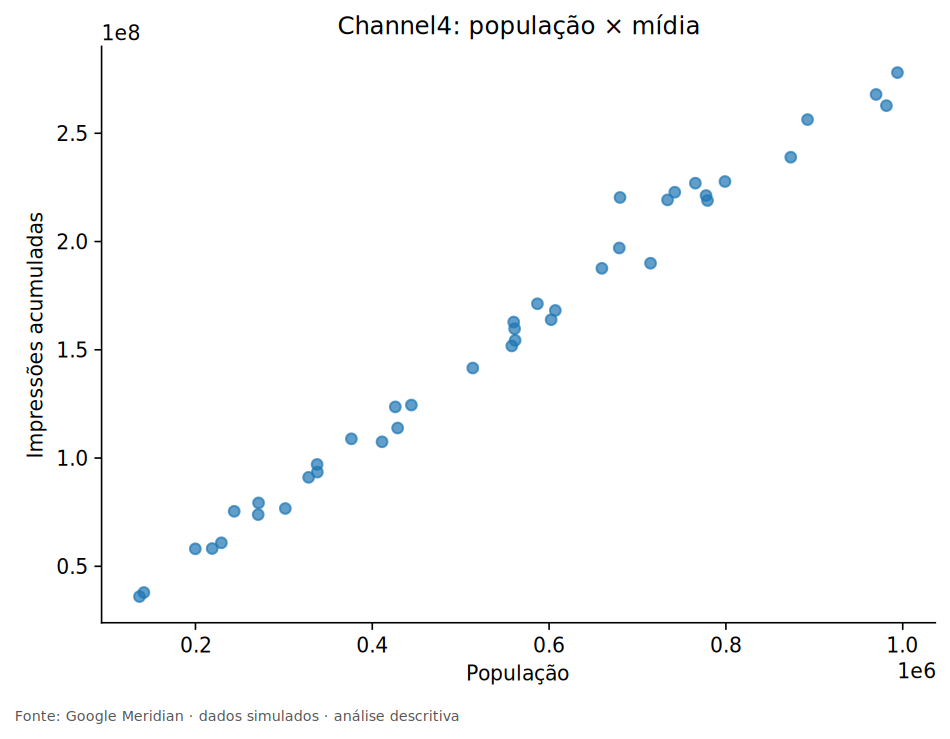

**Channel4_spend_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

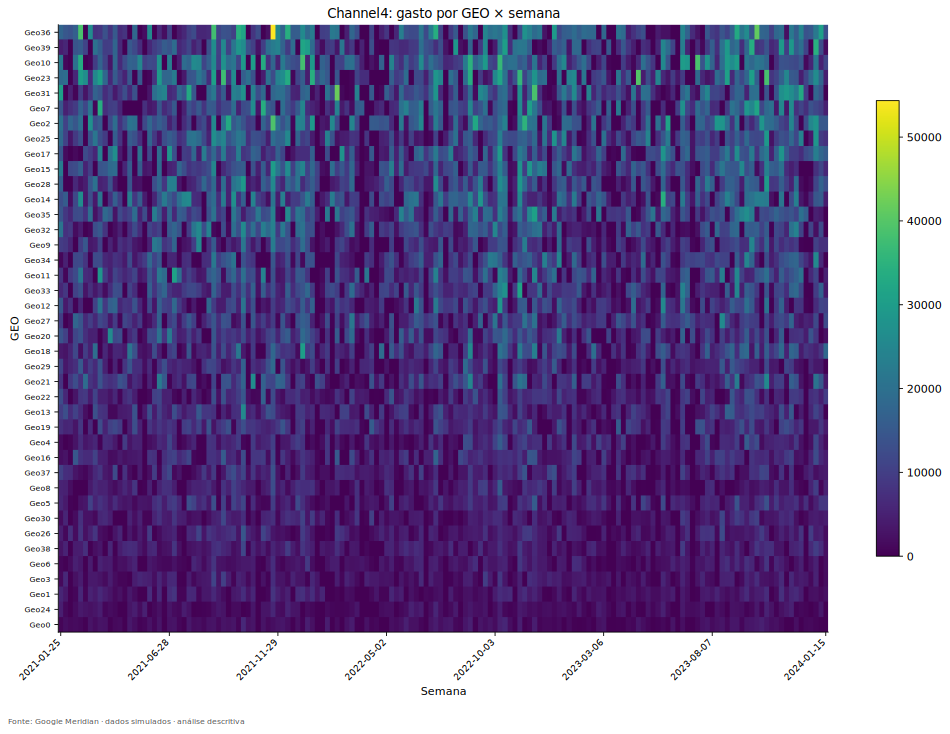

**Channel4_spend_pc_geo_time** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

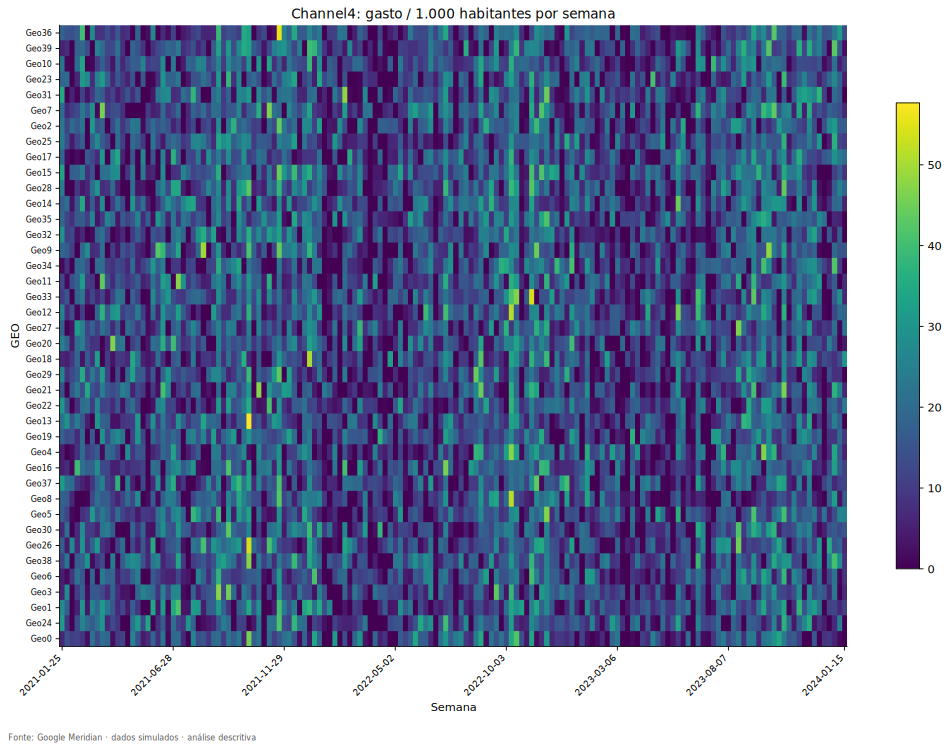

**geo_allocation** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

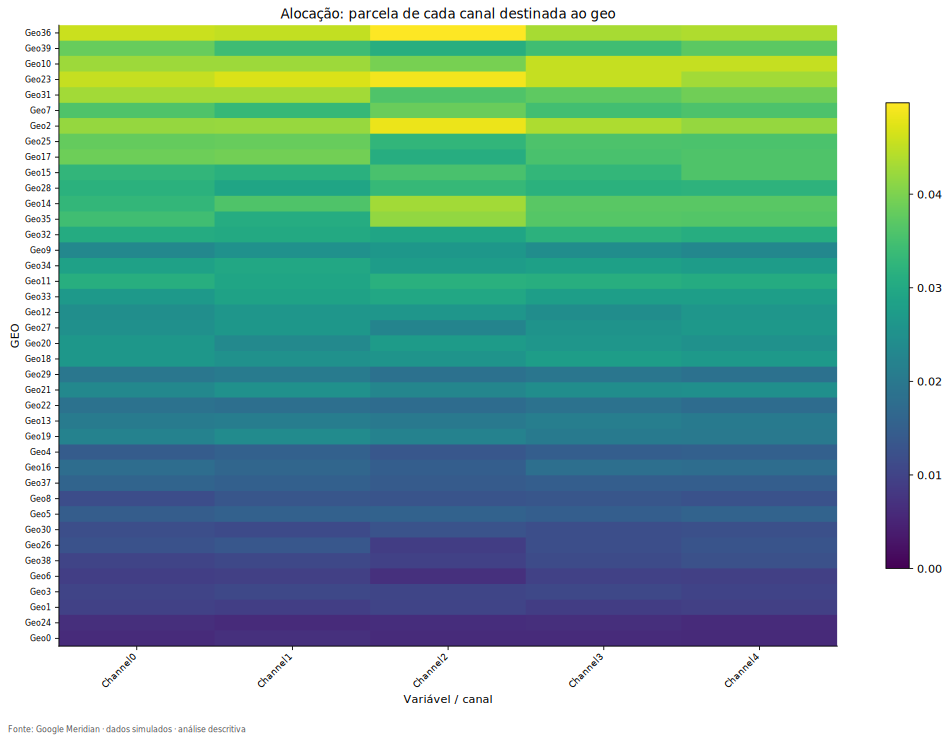

**media_mix** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

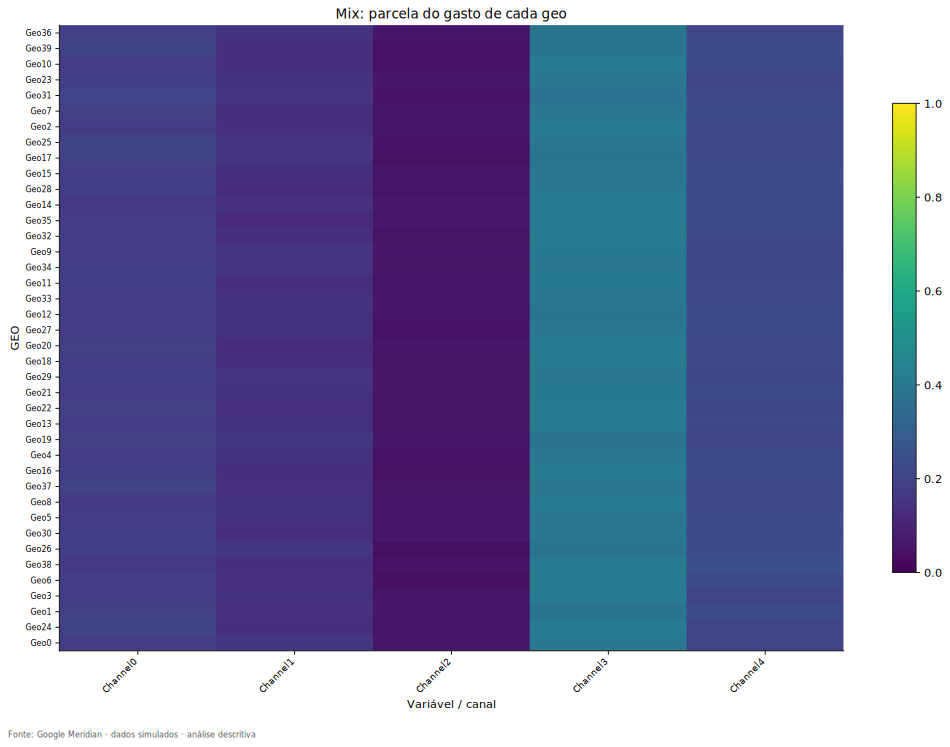

**mix_deviations_pp** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

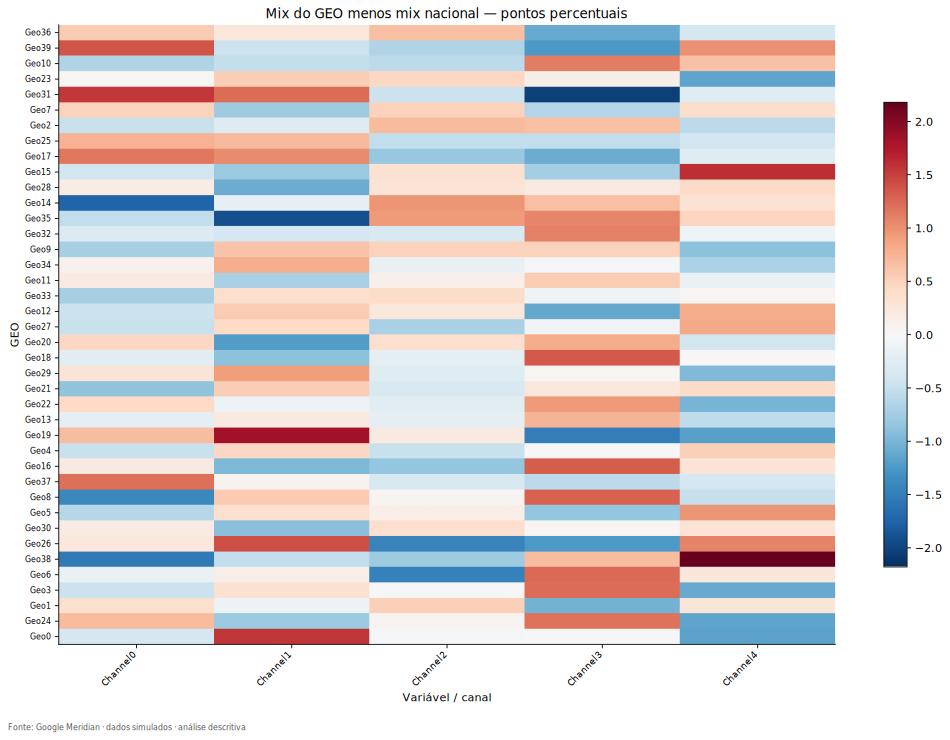

**mix_stacked** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

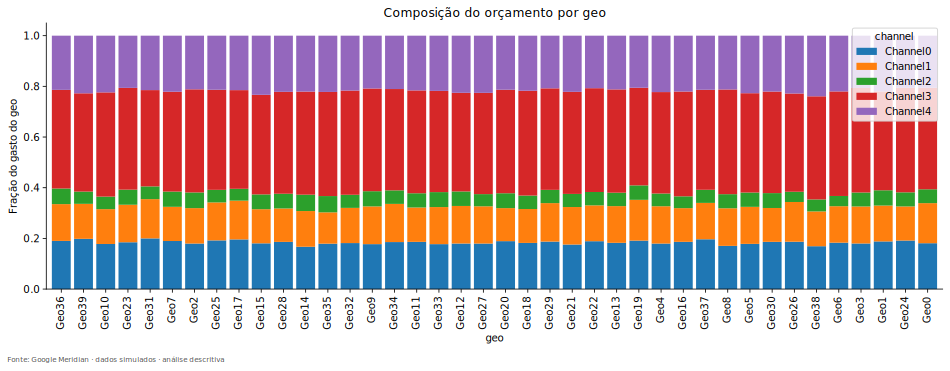

**spend_geo_channel** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

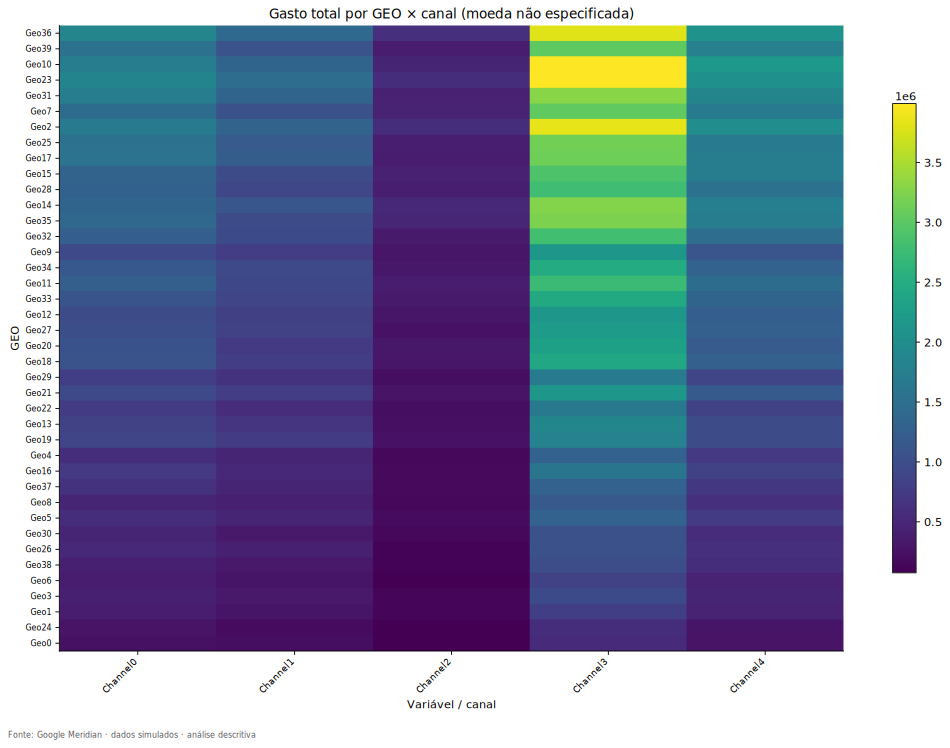

**spend_per_capita** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

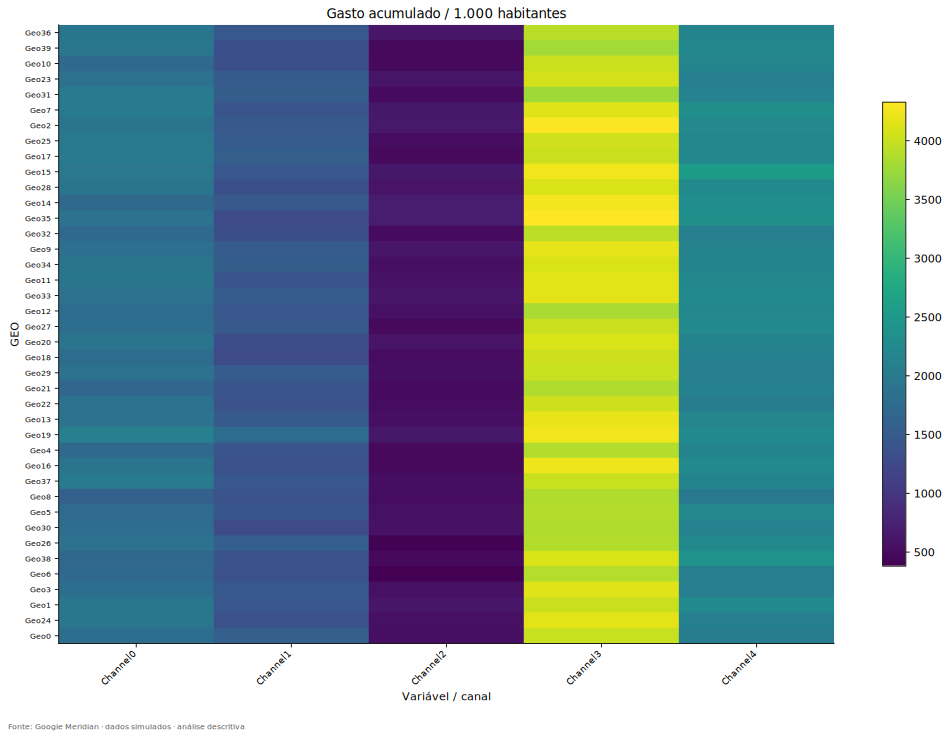

**within_cv_distribution** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

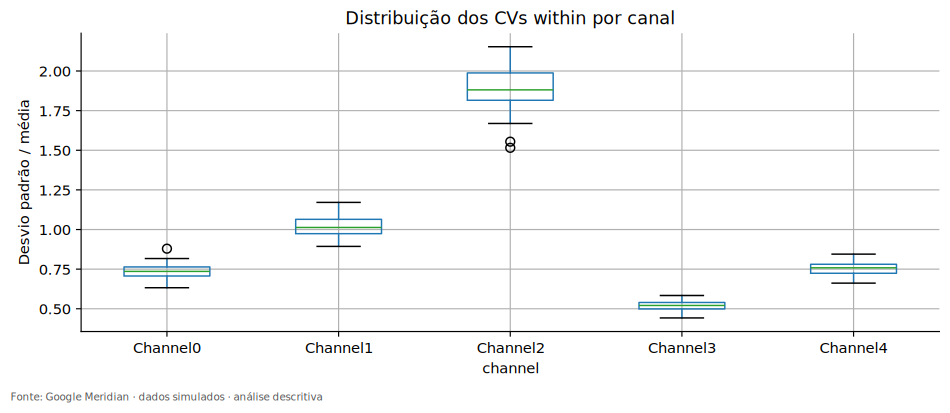

**within_geo_cv** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

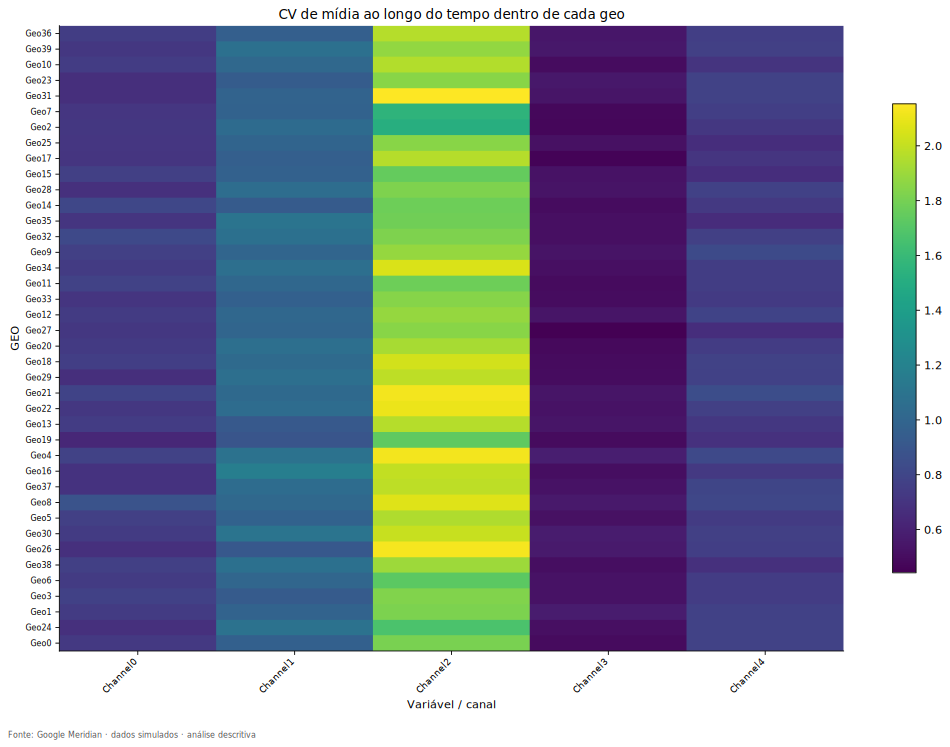

In [ ]:
show(report_04, part="evidence")


---
## Seção executável 05 — Relações e redundância

## Capítulo 13 — Sinais que caminham juntos

Até aqui abrimos cada canal como se ele tivesse uma história própria. Mas o calendário de um pode acompanhar o de outro. Se isso acontecer, uma semana de muita exposição em um canal será também uma semana de muita exposição em outro. Antes de relacionar qualquer um deles ao resultado, precisamos saber quanto seus movimentos se parecem.

Como gasto e impressões são quase proporcionais dentro de cada canal desta base, começar destacando essa correlação próxima de um seria pouco informativo. Estaríamos redescobrindo o custo unitário quase constante. A pergunta mais útil envolve sinais distintos, como as exposições de `Channel2` e `Channel3`.

No total nacional, a correlação de Pearson entre eles é aproximadamente **0,70**. É uma associação positiva relevante: semanas de maior exposição em um tendem a acompanhar maior exposição no outro. Mas já sabemos que a soma pode esconder diferenças. Por isso, a análise foi repetida com quatro formas de organizar a informação.

A primeira é o nacional, com um ponto por semana. A segunda mantém todas as fichas de mercado e semana em seus valores brutos; nos arquivos, ela aparece como *overall*. A terceira compara desvios em relação ao nível habitual de cada mercado, a visão *within*. A quarta retira também o movimento médio semanal, a visão *two-way* que conhecemos no capítulo do endereço e do calendário.

Para `Channel2` e `Channel3`, a correlação passa de **0,70 no nacional** para cerca de **0,52 no painel bruto**, **0,50 dentro dos mercados** e **0,45 após retirar também o movimento comum das semanas**. A associação não desaparece, mas sua força muda com a pergunta. Esse percurso é mais informativo do que escolher um único número e tratá-lo como propriedade universal dos canais.

A [comparação dos pares](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/substantive_pair_comparison.csv) permite acompanhar essas mudanças. Para enxergar várias relações ao mesmo tempo, usamos uma matriz de cores. No gráfico abaixo, cada encontro de linha e coluna é a correlação entre duas variáveis depois de retirar os níveis médios dos mercados e das semanas. A escala vai de relações negativas a positivas. A diagonal compara uma variável consigo mesma, e os pares de gasto e exposição do mesmo canal são quase repetições contábeis; nenhum desses casos deve dominar a leitura.

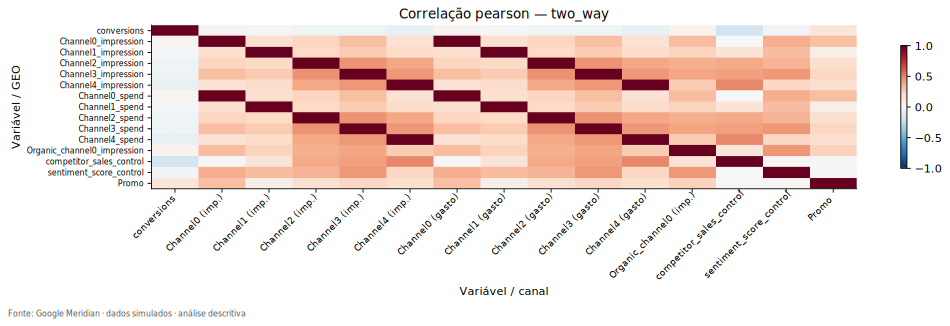

Uma leitura substantiva procura o que sobra entre personagens diferentes. Além de `Channel2` e `Channel3`, existe associação entre `Channel4` e `competitor_sales_control`, perto de **0,48** nessa escala. Isso não demonstra que um concorrente tenha provocado uma decisão publicitária real. Mostra que um índice incluído para representar outro aspecto do ambiente acompanha parte da mídia na simulação.

Os controles, portanto, não são figurantes que podemos acrescentar automaticamente. `competitor_sales_control` e `sentiment_score_control` variam, assumem valores positivos e negativos e não são medidas monetárias de vendas ou satisfação. `Promo` também varia, mas tem outra forma: aproximadamente **47% dos registros são zero**, com valores contínuos no restante. Uma regra que pressupusesse apenas “houve promoção” e “não houve promoção” perderia informação que existe na coluna.

Os [perfis dos controles](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/control_detailed_profile.csv) e suas [relações com os demais sinais](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/control_relationship_review.csv) tornam essas distinções verificáveis. Um controle próximo de zero em média não deve ser chamado de “muito volátil” só porque dividir sua dispersão por essa média produz um número enorme. Para esses índices, observamos amplitude, dispersão e mudanças em sua própria escala.

A história ganhou companhia: mídia, controles e tratamento podem caminhar juntos. Isso torna especialmente delicada a próxima pergunta. Se um canal acompanha o resultado, de quem é o movimento que estamos vendo?

## Capítulo 14 — A associação muda quando mudamos a pergunta

Voltemos à empresa da abertura. Se publicidade e conversões aumentam ao mesmo tempo, podemos querer concluir que uma produziu a outra. Mas a empresa também pode aumentar a publicidade porque já esperava mais demanda. Nesse caso, a expectativa sobre o resultado participa da decisão de investir. A direção da história é mais complicada que “anúncio primeiro, resultado depois”.

Há também fatores compartilhados. Uma época de maior procura pode elevar as conversões e motivar mais anúncios. Selecionar mercados com maior demanda esperada pode associar mídia e resultado mesmo antes de qualquer efeito da campanha. Em marketing, essa escolha direcionada de público ou mercado costuma ser chamada de *targeting*. A base não informa decisões comerciais reais que permitam reconstruir esse mecanismo; os exemplos explicam por que precisamos ter cuidado, não o que comprovadamente aconteceu aqui.

O próprio projeto oferece um exemplo numérico forte dessa cautela. Se juntarmos os valores brutos de todos os mercados e semanas, a exposição de `Channel3` tem correlação aproximada de **0,47 com as conversões**. Parece uma relação positiva bastante diferente daquela vista quando comparamos cada mercado com seu próprio histórico: nessa segunda visão, a correlação fica perto de **−0,05**.

Depois de retirar também as médias semanais, ela permanece próxima de zero, em torno de **−0,046**. Já no agregado nacional fica perto de **−0,12**. A [comparação entre mídia e KPI](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/predictor_kpi_comparison.csv) registra as quatro lentes. O resultado não permite decidir que o canal funciona no painel e deixa de funcionar no nacional. Permite perceber que relações entre níveis absolutos e relações entre mudanças são perguntas distintas.

Lembre-se do tamanho populacional. Mercados maiores tendem a ter mais exposição e mais conversões. Uma associação entre esses volumes pode ser forte mesmo quando as semanas de exposição acima do habitual não acompanham aumentos semelhantes de conversões. Retirar médias ajuda a investigar essa diferença, mas não controla automaticamente todos os fatores que mudam dentro de um mercado.

Também não seria correto concluir que a publicidade reduz conversões por causa de uma correlação negativa pequena. Efeitos podem ocorrer com atraso, depender da quantidade de exposição ou se misturar a decisões tomadas em antecipação à demanda. Uma correlação contemporânea simples não separa essas possibilidades.

Para explorar o atraso, o projeto comparou mídia de semanas anteriores com o KPI atual, deslocando a exposição de zero a oito semanas. Esse deslocamento recebe o nome de **lag**, ou defasagem. A [figura das defasagens](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/figures/relationships/lags.svg) e a [tabela correspondente](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/exploratory_lags.csv) mostram essas associações, com menos pares disponíveis quando o deslocamento aumenta.

Essas curvas não escolhem quanto tempo a publicidade permanece atuando. Escolher o maior ponto e chamá-lo de “duração do efeito” converteria uma exploração de associações em uma conclusão que ela não sustenta. O que sabemos é onde os sinais se aproximam ou se afastam sob diferentes comparações.

Agora a dificuldade da pergunta inicial ficou mais concreta. Não basta haver movimento. Precisamos conseguir distinguir histórias concorrentes para esse movimento. Dois canais que acompanham um ao outro e fatores que acompanham ambos podem permitir explicações muito parecidas para o mesmo resultado.

## Capítulo 15 — O problema das duas torneiras

Imagine uma piscina abastecida por duas torneiras. Se ambas forem abertas e fechadas sempre juntas, podemos observar a água subir, mas teremos dificuldade para descobrir quanto veio de cada uma. Se em alguns momentos uma mudar enquanto a outra permanece estável, ganharemos uma comparação que antes não existia.

Com os canais de mídia acontece algo semelhante. Observar separadamente cada exposição não basta se suas mudanças forem quase sempre as mesmas. Para distinguir seus papéis, o modelo precisa de diferenças informativas entre os sinais, além de hipóteses que liguem essas diferenças ao resultado. Esse desafio está relacionado à **identificabilidade**: a possibilidade de distinguir explicações ou parâmetros a partir das informações e das hipóteses disponíveis.

A analogia das torneiras cobre apenas parte do problema. Na empresa, alguém pode abrir uma torneira porque prevê uma mudança na procura, e pode haver fatores relevantes que nem sequer foram medidos. Assim, separar numericamente dois sinais é necessário em algumas situações, mas não resolve sozinho a interpretação causal.

Uma dificuldade específica ocorre quando uma variável pode ser muito bem reconstruída por uma combinação das outras. Ela pode existir mesmo sem um par isolado apresentar correlação perfeita. Esse padrão é chamado de **multicolinearidade**. Precisamos, portanto, olhar o conjunto de sinais, não apenas comparar dois de cada vez.

Para isso, o projeto usou o **VIF**, um indicador que investiga quanto a redundância linear pode aumentar a incerteza de um coeficiente em uma regressão linear. A lógica é tentar explicar cada preditor usando os demais e verificar quanto de informação própria resta. O diagnóstico não é um veredito sobre o efeito de mídia nem um resumo completo do futuro modelo.

No gráfico abaixo, cada linha é um preditor e as colunas correspondem às quatro lentes que já usamos. A cor usa uma escala comprimida: cada aumento de uma unidade nessa escala representa multiplicar o VIF por dez. Essa transformação é o logaritmo de base dez, indicado no título. Assim, o valor da barra de cores não deve ser lido como o VIF original. Os números originais estão na [tabela de VIF](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/vif_summary.csv).

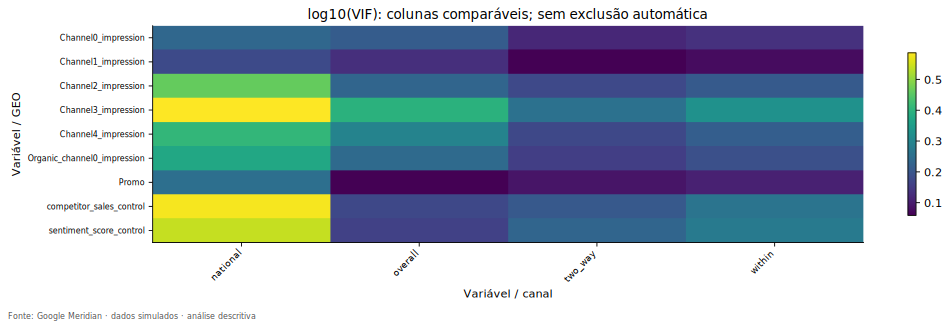

Os máximos são aproximadamente **3,86 no nacional**, **2,48 no painel bruto**, **2,11 na visão within** e **1,80 na two-way**. Nesse conjunto de variáveis e nessas transformações, não encontramos redundância linear extrema. Isso é uma evidência favorável para continuar a investigação, mas não uma certificação de que todos os efeitos poderão ser separados com precisão.

O conjunto diagnosticado inclui exposições pagas e orgânica, os dois controles e `Promo`. Não inclui o KPI como preditor e não duplica gasto e impressão do mesmo canal. Essa escolha importa porque, com custo quase constante, incluir ambos criaria artificialmente o problema que estaríamos tentando medir.

A futura modelagem poderá mudar os sinais. Um anúncio pode continuar associado à resposta depois da semana em que foi exibido; representar essa persistência é a ideia de **adstock**. E aumentar exposição pode trazer acréscimos progressivamente menores de resposta; essa é a ideia de **saturação**. Ao transformar os canais para representar essas possibilidades, também podemos alterar suas relações e sua redundância.

Por isso, o VIF atual não libera automaticamente a modelagem, e um valor elevado não manda remover um canal. Temos um diagnóstico sobre os sinais explorados. Devemos carregá-lo como pergunta para a próxima fase: depois das escolhas de modelagem, ainda haverá informação suficiente para distinguir os papéis propostos?

Antes de juntar as conclusões, resta confrontar nossa investigação com outra leitura: a que o próprio Meridian oferece para examinar os dados e uma especificação provisória.

### O que a regressão auxiliar do VIF pergunta

Para cada preditor $X_j$, ajustamos uma regressão com intercepto sobre os demais e calculamos $VIF_j=1/(1-R_j^2)$. Se os demais reconstroem quase todo o sinal, sobra pouca variação própria. Padronizar as colunas melhora a comparação numérica, mas não resolve confundimento.

Não incluímos gasto e impressões juntos porque, com CPMU quase constante, duplicaríamos um sinal. Também não usamos o KPI como preditor no diagnóstico. Pearson e Spearman são calculados nas quatro lentes; Spearman dos resíduos é a correlação de seus postos, não uma correlação parcial de postos. Nas defasagens, a exposição passada é alinhada ao KPI presente e o número de pares diminui. Escolher o maior ponto não equivale a estimar adstock.

### Medir redundância conjunta

Uma coluna constante recebe VIF indefinido; dependência linear perfeita recebe infinito.

Código original de `src/statistics.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def vif_table(frame: pd.DataFrame, level: str) -> pd.DataFrame:
    """VIF com intercepto, colunas padronizadas, constantes explicitamente indefinidas."""
    x=frame.dropna().astype(float)
    if len(x)<len(x.columns)+2: raise ValueError('Amostra insuficiente para VIF.')
    varying=x.std(ddof=0)>1e-12
    z=(x.loc[:,varying]-x.loc[:,varying].mean())/x.loc[:,varying].std(ddof=0)
    rows=[]
    for col in x:
        if not varying[col]:
            rows.append(dict(variable=col,level=level,vif=np.nan,status='constant')); continue
        y=z[col].to_numpy()
        others=z.drop(columns=col).to_numpy()
        design=np.column_stack([np.ones(len(y)),others])
        fitted=design@np.linalg.lstsq(design,y,rcond=None)[0]
        residual_ratio=np.sum((y-fitted)**2)/np.sum(y*y)
        rows.append(dict(variable=col,level=level,vif=1/residual_ratio if residual_ratio>1e-12 else np.inf,
                         status='singular' if residual_ratio<=1e-12 else 'finite'))
    return pd.DataFrame(rows)


### Selecionar relações substantivas

A seleção exclui pares contábeis de gasto e impressões e mantém a comparação nas quatro lentes.

Código original de `src/investigation.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def relationship_investigation(p):
    corr=read('correlation_summary');predictors=[c+'_impression' for c in channels(p)]+ORGANIC+CONTROLS+NON_MEDIA
    selected=corr[corr.left.isin(predictors)&corr.right.isin(predictors)]
    wide=selected.pivot(index=['left','right','method'],columns='level',values='correlation').reset_index().sort_values('within',key=lambda x:x.abs(),ascending=False)
    wide['national_minus_within']=wide.national-wide.within;export(wide,'substantive_pair_comparison')
    export(corr[(corr.left==KPI)&corr.right.isin(predictors)],'predictor_kpi_comparison')
    v=read('vif_summary');r=read('geo_time_r2').set_index('variable');rows=[]
    for col in CONTROLS+NON_MEDIA:
        peers=wide[(wide.method=='pearson')&((wide.left==col)|(wide.right==col))];best=peers.loc[peers.two_way.abs().idxmax()]
        rows.append(dict(variable=col,r2_geo=r.loc[col,'r2_geo'],r2_time=r.loc[col,'r2_time'],vif_within=v[(v.variable==col)&(v.level=='within')].vif.iloc[0],strongest_two_way_peer=best.right if best.left==col else best.left,strongest_two_way_correlation=best.two_way,implication='Justificar papel pré-tratamento/confundidor no DAG; associação não autoriza inclusão causal.'))
    return wide,export(pd.DataFrame(rows),'control_relationship_review')


### Código completo desta etapa

A implementação abaixo foi transportada de `src/eda.py` (`relationships`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('05')
def relationships(panel):
    columns=analytical_columns(panel)
    nat=national(panel)[columns]
    within=panel[columns]-panel.groupby(GEO)[columns].transform('mean')
    two_way=within-panel.groupby(TIME)[columns].transform('mean')+panel[columns].mean()
    levels={'national':nat,'overall':panel[columns],'within':within,'two_way':two_way}
    figs=[];pairs=[]
    for level,data in levels.items():
        for method in ['pearson','spearman']:
            corr=data.corr(method=method);table(corr,f'correlation_{level}_{method}')
            if method=='pearson':
                figs.append(heatmap(corr,'relationships',f'correlation_{level}',f'Correlação {method} — {level}',cmap='RdBu_r',vmin=-1,vmax=1))
            for suffix in ['_impression','_spend']:
                selected=[c+suffix for c in channels(panel)]
                table(corr.loc[selected,selected],f'{suffix[1:]}_correlation_{level}_{method}')
            for i,left in enumerate(columns):
                for right in columns[i+1:]: pairs.append(dict(level=level,method=method,left=left,right=right,correlation=corr.loc[left,right]))
    summary=table(pd.DataFrame(pairs),'correlation_summary',False)
    # Não incluir spend junto com impressions: custo quase fixo duplica o sinal por construção.
    predictors=[c+'_impression' for c in channels(panel)]+ORGANIC+CONTROLS+NON_MEDIA
    vif=pd.concat([vif_table(data[predictors],level) for level,data in levels.items()],ignore_index=True)
    table(vif,'vif_summary',False)
    figures=vif.pivot(index='variable',columns='level',values='vif')
    figs.append(heatmap(np.log10(figures.replace([np.inf,-np.inf],np.nan)),'relationships','vif','log10(VIF): colunas comparáveis; sem exclusão automática'))
    lag_rows=[]
    for channel in channels(panel):
        for lag in range(9):
            aligned=pd.concat([nat[channel+'_impression'].shift(lag),nat[KPI]],axis=1).dropna()
            lag_rows.append(dict(channel=channel,lag_weeks=lag,n=len(aligned),correlation=aligned.iloc[:,0].corr(aligned.iloc[:,1])))
    lags=table(pd.DataFrame(lag_rows),'exploratory_lags',False)
    figs.append(lines(lags.pivot(index='lag_weeks',columns='channel',values='correlation'),'relationships','lags','Correlação mídia(t−k) × KPI(t); descritiva','Pearson'))
    strongest=summary[(summary.level=='within')&(summary.method=='pearson')&(summary.left.isin(predictors))&(summary.right.isin(predictors))].copy()
    strongest=strongest.loc[strongest.correlation.abs().sort_values(ascending=False).index]
    text=f'''Exportamos Pearson e Spearman em quatro níveis: nacional, painel bruto, within-geo e residual two-way. Within remove a média de cada geo; two-way remove também a média semanal comum. Spearman de resíduos mede a ordenação dos resíduos e não é uma correlação parcial de postos.

O maior VIF within entre preditores é {vif.loc[vif.level=='within','vif'].max():.2f}. A regressão auxiliar inclui intercepto e colunas padronizadas. Spend e impressões são diagnosticados em matrizes separadas; colocá-los juntos no VIF duplicaria sinais de custo praticamente fixo. Constantes são indefinidas e dependência linear perfeita gera infinito.

A maior associação absoluta within entre preditores distintos é {strongest.iloc[0]['left']} × {strongest.iloc[0]['right']} ({strongest.iloc[0].correlation:.3f}); o ranking exclui pares gasto–impressões do mesmo canal. Lags 0–8 são exploratórios, sem selecionar adstock. Não calculamos p-valores que presumiriam independência das {len(panel):,} linhas: existe dependência temporal e geográfica.

Diferenças entre correlações nacionais e within podem resultar de composição populacional, tendência, sazonalidade e mídia alocada em antecipação à demanda. Correlação mídia–KPI não constitui efeito de mídia.'''
    return result('05_eda_relationships',text,{'vif':vif,'correlations':strongest.head(15),'lags':lags},figs,'Checagens independentes da ferramenta oficial e comparação de definições.')


In [ ]:
report_05 = relationships(geo_time_panel)
show(report_05, part="summary")


### Resultado observado e conclusão parcial

Exportamos Pearson e Spearman em quatro níveis: nacional, painel bruto, within-geo e residual two-way. Within remove a média de cada geo; two-way remove também a média semanal comum. Spearman de resíduos mede a ordenação dos resíduos e não é uma correlação parcial de postos.

O maior VIF within entre preditores é 2.11. A regressão auxiliar inclui intercepto e colunas padronizadas. Spend e impressões são diagnosticados em matrizes separadas; colocá-los juntos no VIF duplicaria sinais de custo praticamente fixo. Constantes são indefinidas e dependência linear perfeita gera infinito.

A maior associação absoluta within entre preditores distintos é Channel4_impression × competitor_sales_control (0.550); o ranking exclui pares gasto–impressões do mesmo canal. Lags 0–8 são exploratórios, sem selecionar adstock. Não calculamos p-valores que presumiriam independência das 6,240 linhas: existe dependência temporal e geográfica.

Diferenças entre correlações nacionais e within podem resultar de composição populacional, tendência, sazonalidade e mídia alocada em antecipação à demanda. Correlação mídia–KPI não constitui efeito de mídia.

**Channel2 × Channel3:** nacional 0.7003, within 0.5035, two-way 0.4511. Parte do movimento conjunto acompanha composição/tempo comum, mas há associação residual. O ranking exclui gasto–impressões do mesmo canal.

competitor_sales_control: R² tempo 0.332; VIF within 1.83; maior associação two-way com Channel4_impression (+0.478). Justificar papel pré-tratamento/confundidor no DAG; associação não autoriza inclusão causal.

sentiment_score_control: R² tempo 0.274; VIF within 1.88; maior associação two-way com Organic_channel0_impression (+0.437). Justificar papel pré-tratamento/confundidor no DAG; associação não autoriza inclusão causal.

Promo: R² tempo 0.198; VIF within 1.28; maior associação two-way com Channel0_impression (+0.297). Justificar papel pré-tratamento/confundidor no DAG; associação não autoriza inclusão causal.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Channel2 × Channel3:** nacional 0.7003, within 0.5035, two-way 0.4511. Parte do movimento conjunto acompanha composição/tempo comum, mas há associação residual. O ranking exclui gasto–impressões do mesmo canal.
- **Quais problemas apareceram?** VIF moderado não resolve confundimento nem colinearidade após adstock/saturação.
- **O que falta investigar?** Checagens independentes da ferramenta oficial e comparação de definições.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

**vif** — 36 linhas; CSV completo em `outputs/tables/`.

,variable,level,vif,status
0,Channel0_impression,national,1.719037,finite
1,Channel1_impression,national,1.506175,finite
2,Channel2_impression,national,2.890948,finite
3,Channel3_impression,national,3.857286,finite
4,Channel4_impression,national,2.563407,finite
5,Organic_channel0_impression,national,2.376850,finite
6,competitor_sales_control,national,3.793200,finite
7,sentiment_score_control,national,3.461720,finite
8,Promo,national,1.782877,finite
9,Channel0_impression,overall,1.632356,finite


**correlations** — 15 linhas; CSV completo em `outputs/tables/`.

,level,method,left,right,correlation
486,within,pearson,Channel4_impression,competitor_sales_control,0.550356
478,within,pearson,Channel3_impression,sentiment_score_control,0.506064
459,within,pearson,Channel2_impression,Channel3_impression,0.503550
477,within,pearson,Channel3_impression,competitor_sales_control,0.498532
470,within,pearson,Channel3_impression,Channel4_impression,0.479959
520,within,pearson,Organic_channel0_impression,sentiment_score_control,0.476936
476,within,pearson,Channel3_impression,Organic_channel0_impression,0.454943
467,within,pearson,Channel2_impression,competitor_sales_control,0.438038
460,within,pearson,Channel2_impression,Channel4_impression,0.435983
468,within,pearson,Channel2_impression,sentiment_score_control,0.402763


**lags** — 45 linhas; CSV completo em `outputs/tables/`.

...

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

[Figura gerada; veja outputs/figures ou execute a célula.]

**correlation_national** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

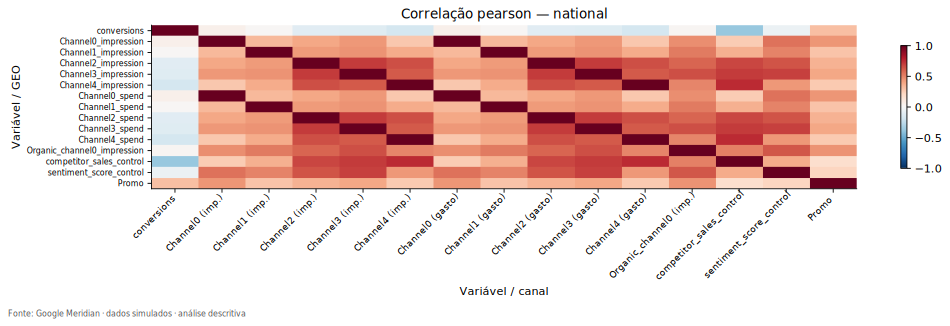

**correlation_overall** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

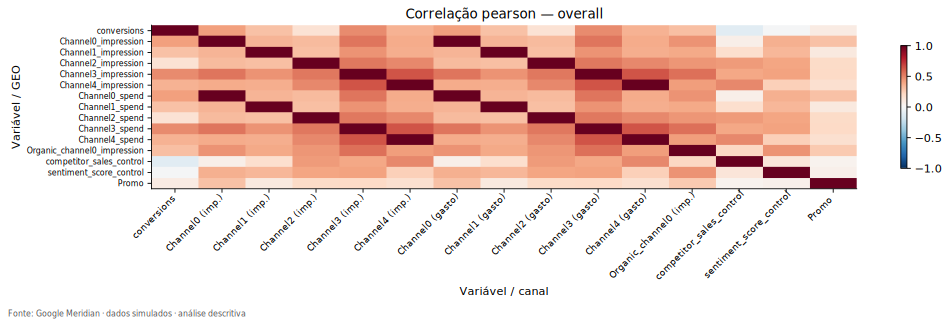

**correlation_two_way** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

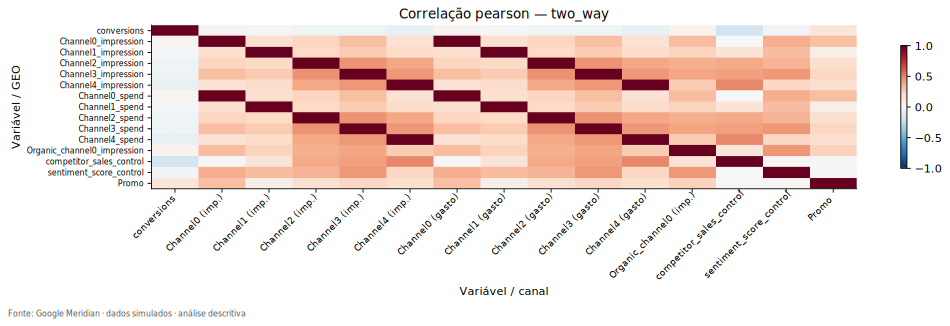

**correlation_within** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

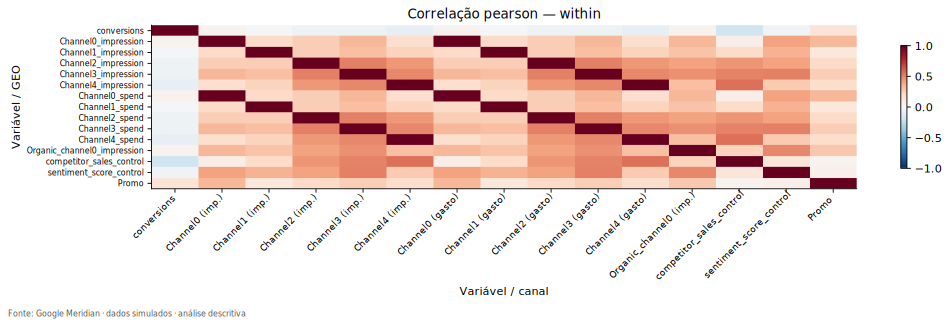

**lags** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

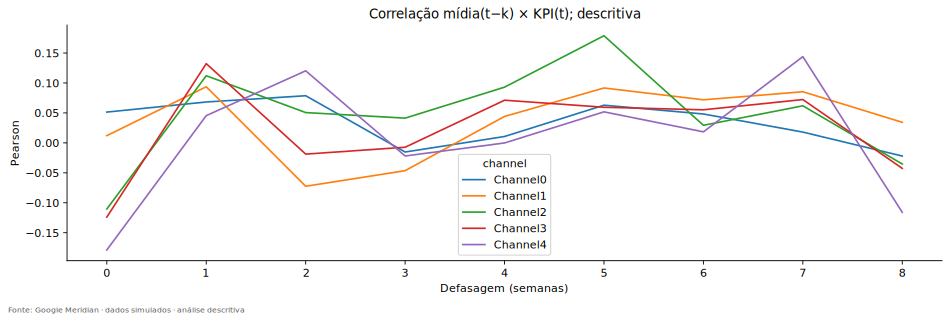

**vif** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

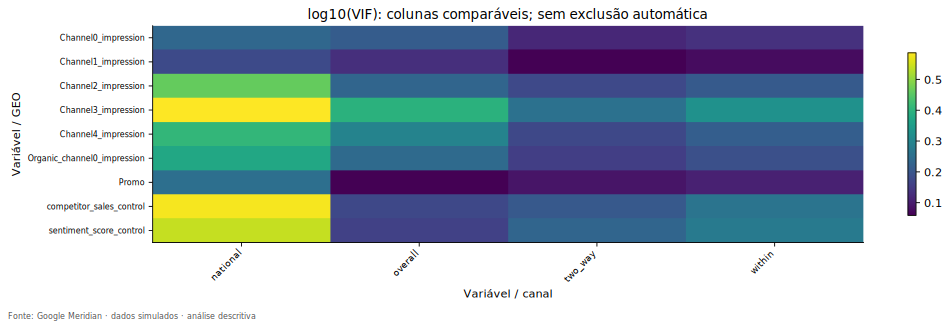

In [ ]:
show(report_05, part="evidence")


---
## Seção executável 06 — Diagnósticos oficiais

## Capítulo 16 — Uma segunda opinião

A exploração até aqui foi construída em torno das dúvidas do TCC. O Meridian possui seus próprios diagnósticos padronizados. Consultá-los permite comparar a investigação personalizada com a forma como a ferramenta enxerga os dados que receberia. Não substitui nosso raciocínio; acrescenta uma segunda opinião que também precisa ser interpretada.

A execução registrada no repositório utilizou **Meridian 2.1.0**, em uma versão do código identificada nos metadados. Foram aplicadas **13 checagens**, que produziram **16 achados**: dez classificados como `INFO` e seis como `REVIEW`. A segunda classificação pede revisão. A primeira não significa que todas as questões metodológicas estejam resolvidas.

Quatro dos seis alertas envolvem extremos ou variabilidade, em conversões e em outros sinais, tanto por mercado quanto no nacional. Os outros dois envolvem custo por unidade de mídia. Todos foram examinados na revisão posterior à auditoria. A [tabela de resolução](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/official_review_resolution.csv) preserva localização, motivo, decisão e limite restante; o nome `REVIEW` não foi apagado para fazer o resultado parecer melhor.

Vale acompanhar um caso concreto. Na triagem personalizada, `Geo36` em 14 de agosto de 2023 aparece com cerca de **34,9 milhões de conversões** e é sinalizado pela regra aplicada aos valores brutos de todo o painel. Quando a referência passa a ser a escala por habitante ou o histórico do próprio mercado, ele não é sinalizado pela respectiva regra. O valor não mudou; mudou o grupo com o qual foi comparado. Isso ensina por que “extremo” precisa sempre vir acompanhado de uma referência.

Já `Geo23` em 28 de fevereiro de 2022 permanece sinalizado nas três comparações da [revisão de casos](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/outlier_case_review.csv). Não foi simplesmente absolvido pela população. Ainda assim, não temos evidência de erro de registro nem contexto empresarial que justifique substituí-lo. A decisão documentada foi preservar os dados simulados e reservar a avaliação de influência no ajuste para a modelagem. Preservar é uma decisão fundamentada, não uma afirmação de que o ponto jamais importará.

A regra baseada na distância à parte central da distribuição aparece nos arquivos como **IQR**. Outra triagem utiliza a distância à mediana e uma medida robusta de dispersão, chamada **MAD**. Elas ajudam a localizar registros para investigação. Não são detectores infalíveis de erro, especialmente diante de muitos zeros ou mercados de tamanhos diferentes. A revisão olhou também o entorno temporal dos casos, sem atribuir a seus picos eventos comerciais inventados.

O custo unitário oferece uma lição diferente. A variação é tão pequena que uma regra baseada em dispersão também muito pequena pode sinalizar desvios microscópicos. Entre os casos geográficos revisados, o maior desvio relativo na respectiva série é da ordem de **0,000014%**. Isso é compatível com precisão numérica de geração ou exportação, embora a causa não tenha sido comprovada. Não há suporte para narrar uma oscilação econômica importante de preço. O dado e o limite oficial foram preservados.

Outra parte da segunda opinião exige comparar coisas equivalentes. O Meridian transforma variáveis e calcula alguns diagnósticos em escalas diferentes das nossas tabelas brutas. Seus R² também recebem um ajuste estatístico. No agregado nacional, controles e `Promo` são somados por padrão nessa checagem oficial, enquanto a exploração personalizada usa médias ponderadas por população. Se ignorássemos essas escolhas, poderíamos chamar uma diferença de definição de erro de cálculo.

A revisão, por isso, refez R², correlações e VIF nas mesmas escalas oficiais e conferiu as localizações dos casos extremos. As [reconciliações](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/official_r2_reconciliation.csv) e os arquivos associados no apêndice documentam a concordância numérica e as diferenças de pergunta. Os limites oficiais de correlação e VIF são voltados a situações extremas; passar por eles não garante que uma associação moderada seja irrelevante para nosso estudo.

Há ainda uma possível confusão no relatório HTML. Para seus diagnósticos, a ferramenta gerou amostras de suposições iniciais sobre o modelo, antes de aprender os efeitos a partir dos dados. Essas suposições recebem o nome de **prior**. O resultado de atualizar essas suposições com os dados seria uma distribuição **posterior**. Nesta etapa não houve essa estimação posterior. Logo, encontrar gráficos sobre a prior não significa que os efeitos publicitários já foram estimados.

O [relatório oficial](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/reports/meridian_eda_report.html) deve ser baixado e aberto no navegador para sua leitura completa. A configuração usada é provisória. Inclusive a razão entre registros e a contagem de parâmetros adotada pela checagem, próxima de 30,6, é apenas um sinal de adequação sob aquela configuração. Não transforma 6.240 fichas dependentes em 6.240 experiências independentes.

A segunda opinião não encerrou nossas perguntas com um selo de aprovação. Ela tornou as ressalvas localizáveis e comparáveis. Agora podemos reunir as pistas sem esconder os pontos que ainda exigirão cuidado.

### Comparar a mesma grandeza antes de comparar números

A auditoria oficial usa variáveis transformadas e R² ajustado. Para um ajuste por geo, a transformação usada na reconciliação é $1-(1-R^2)(N-1)/(N-G)$; por semana, substituímos $G$ por $T$. O cálculo independente usa somas de quadrados e confronta o resultado oficial, sem reutilizar o OLS da biblioteca.

As correlações e VIF também são refeitos na mesma escala oficial. Para os extremos, comparamos as chaves geo–variável–semana, não apenas o total de alertas. Uma igualdade de contagens poderia esconder conjuntos de casos diferentes.

Esta célula é a mais dependente da API fixada. O construtor do `MeridianEDA` gera amostras **da prior**; o código verifica que não existe grupo posterior. Os defaults são provisórios, e os seis REVIEW continuam visíveis com suas decisões e limitações.

### Reconciliar e documentar decisões

São preservadas as verificações de correlação, VIF, localizações dos extremos e magnitude de CPMU, com tolerâncias e thresholds originais.

Código original de `src/official_review.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def long_frame(array):
    f=array.to_dataframe(name='value').reset_index()
    if 'var' not in f:
        c=next((c for c in f if 'channel' in c),None)
        f=f.rename(columns={c:'var'}) if c else f.assign(var=KPI)
    if 'geo' not in f:f['geo']='NATIONAL'
    f['time']=f.time.astype(str).str[:10]
    return f

def source_variable(var):return var+'_impression' if var.startswith(('Channel','Organic_channel')) else KPI if 'kpi' in var else var

def compare_and_review(engine,outcomes,panel):
    from meridian.model.eda.eda_engine import stack_variables
    datasets={'geo':stack_variables(engine.treatment_control_scaled_ds),'national':stack_variables(engine.national_treatment_control_scaled_ds)}
    corr_rows=[];vif_rows=[]
    for level,array in datasets.items():
        f=long_frame(array);x=f.pivot(index=['geo','time'],columns='var',values='value');corr=x.corr()
        expected=outcomes[f'check_{level}_pairwise_corr'].analysis_artifacts[0].corr_matrix
        expected_vif=outcomes[f'check_{level}_vif'].analysis_artifacts[0].vif_da.to_series();custom_vif=vif_table(x,level).set_index('variable')
        for col in x:
            a=custom_vif.loc[col,'vif'];b=expected_vif.loc[col]
            vif_rows.append(dict(level=level,variable=col,custom_same_scale=a,official=b,absolute_difference=abs(a-b)))
        for i,left in enumerate(x):
            for right in x.columns[i+1:]:
                official=float(expected.sel(var1=left,var2=right));corr_rows.append(dict(level=level,left=left,right=right,custom_same_scale=corr.loc[left,right],official=official,absolute_difference=abs(corr.loc[left,right]-official)))
    correlations=table(pd.DataFrame(corr_rows),'official_correlation_reconciliation',False);vifs=table(pd.DataFrame(vif_rows),'official_vif_reconciliation',False)
    if correlations.absolute_difference.max()>1e-5 or vifs.absolute_difference.max()>1e-5:raise ValueError('Reconciliação de correlação/VIF falhou')
    raw=pd.read_csv(ROOT/'outputs/tables/correlation_summary.csv');comparison=[]
    for r in correlations.itertuples():
        left,right=source_variable(r.left),source_variable(r.right);level='overall' if r.level=='geo' else 'national'
        match=raw[(raw.level==level)&(raw.method=='pearson')&(((raw.left==left)&(raw.right==right))|((raw.left==right)&(raw.right==left)))]
        if len(match):comparison.append(dict(level=level,left=left,right=right,custom_raw=match.correlation.iloc[0],official_scaled=r.official,delta=r.official-match.correlation.iloc[0],reason='Geo: transformação populacional. Nacional: controles/Promo oficiais somados, custom ponderados por população.'))
    table(pd.DataFrame(comparison),'custom_official_scale_comparison',False)
    arrays={('geo',0):engine.kpi_scaled_da,('geo',1):datasets['geo'],('national',0):engine.national_kpi_scaled_da,('national',1):datasets['national']}
    cases=[];reconciliations=[];reviews=[];original=panel.copy();original['time']=original.time.dt.strftime('%Y-%m-%d')
    def review(check,artifact,finding,risk,decision,evidence):
        reviews.append(dict(review_id=f'REVIEW-{len(reviews)+1}',check=check,artifact=artifact,finding=finding,risk=risk,decision=decision,closure_criterion='localizações verificadas, magnitude quantificada, decisão justificada; sem remoção automática',status='encerrado para EDA simulada; REVIEW oficial preservado',evidence=evidence,residual_limitation='Não certifica plausibilidade comercial; influência/predição posterior serão avaliadas na modelagem.'))
    for (level,index),array in arrays.items():
        method=f'check_{level}_std';artifact=outcomes[method].analysis_artifacts[index];f=long_frame(array);keys=set();local=[]
        for (geo,var),g in f.groupby(['geo','var']):
            q1,q3=g.value.quantile([.25,.75]);lower=q1-1.5*(q3-q1);upper=q3+1.5*(q3-q1)
            for r in g[(g.value<lower)|(g.value>upper)].itertuples():
                keys.add((str(geo),str(var),r.time));col=source_variable(str(var));selection=original[original.time==r.time]
                if geo=='NATIONAL':value=selection[col].sum();pop=selection[POP].sum()
                else:
                    row=selection[selection.geo==geo].iloc[0];value=row[col];pop=row[POP]
                reason='Promo contínuo e zero-inflado; IQR não diagnostica erro' if col=='Promo' else 'Índice sintético com valores negativos admissíveis' if col in CONTROLS else 'Domínio válido; magnitude confrontada na escala oficial e dentro do nível/geo'
                local.append(dict(check=method,artifact=index,geo=geo,variable=var,time=r.time,raw_value=value,scaled_value=r.value,lower_bound=lower,upper_bound=upper,population=pop,raw_per_1000=value/pop*1000 if col not in CONTROLS+NON_MEDIA else np.nan,reason=reason,decision='manter no exemplo simulado; sem evidência de corrupção',limitation='plausibilidade comercial não demonstrada'))
        cases.extend(local);official=artifact.outlier_df.reset_index()
        if 'var' not in official:official['var']=KPI
        if 'geo' not in official:official['geo']='NATIONAL'
        expected=set(zip(official.geo.astype(str),official['var'].astype(str),official.time.astype(str).str[:10]));difference=len(keys.symmetric_difference(expected))
        reconciliations.append(dict(check=method,artifact=index,custom_cases=len(keys),official_cases=len(expected),symmetric_difference=difference))
        if difference:raise ValueError(f'Localizações IQR divergem: {method}/{index}')
        if local:
            worst=max(local,key=lambda r:abs(r['scaled_value']));counts=pd.Series([r['variable'] for r in local]).value_counts().to_dict()
            review(method,index,f'{len(local)} extremos; grupos={counts}; máximo |escalado|={abs(worst["scaled_value"]):.4f} em {worst["geo"]}/{worst["variable"]}/{worst["time"]}','confundir cauda sintética, escala e intermitência com erro','preservar: limites e localizações reconciliados, domínio válido; não há evidência/contexto comercial para corrigir','official_outlier_cases.csv; official_outlier_reconciliation.csv')
    for level in ['geo','national']:
        method=f'check_{level}_cost_per_media_unit';a=outcomes[method].analysis_artifacts[0];out=a.outlier_df.reset_index();table(out,f'official_cpmu_cases_{level}',False);f=long_frame(a.cost_per_media_unit_da)
        relative=[]
        for _,g in f.groupby(['geo','var']):
            x=g.value.dropna();relative.extend((x/x.mean()-1).abs().tolist())
        if len(out):review(method,0,f'{len(out)} casos CPMU; máximo desvio relativo na respectiva série={max(relative):.3e}; inconsistências spend/media={len(a.cost_media_unit_inconsistency_df)}','IQR amplifica dispersão microscópica','preservar custo e limiar: magnitude compatível com precisão de exportação, sem provar sua causa',f'official_cpmu_cases_{level}.csv')
    frame=table(pd.DataFrame(cases),'official_outlier_cases',False)
    table(frame.sort_values('scaled_value',key=lambda x:x.abs(),ascending=False).groupby(['check','variable'],sort=False).head(2),'official_outlier_selected_cases',False)
    table(pd.DataFrame(reconciliations),'official_outlier_reconciliation',False);table(pd.DataFrame(reviews),'official_review_resolution',False)
    thresholds=[]
    for field in dataclasses.fields(engine.spec):
        value=getattr(engine.spec,field.name)
        if dataclasses.is_dataclass(value):
            for item in dataclasses.fields(value):
                v=getattr(value,item.name)
                if isinstance(v,(float,int)):thresholds.append(dict(check_group=field.name,parameter=item.name,value=v,modified=False,scope='guardrail oficial, não certificado universal de qualidade'))
    table(pd.DataFrame(thresholds),'official_thresholds',False)


### Código completo desta etapa

A implementação abaixo foi transportada de `src/official_eda.py` (`official_eda`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('06')
def official_eda(panel):
    from meridian.data import data_frame_input_data_builder
    from meridian.model import model, spec
    from meridian.model.eda import meridian_eda
    if importlib.metadata.version('google-meridian')!='2.1.0':
        raise RuntimeError('Instale o commit fixado em requirements.txt para reproduzir a API validada.')
    verify_meridian_origin()
    paid=channels(panel)
    frame=panel.copy();frame[TIME]=frame[TIME].dt.strftime('%Y-%m-%d')
    builder=data_frame_input_data_builder.DataFrameInputDataBuilder(
        kpi_type='non_revenue',default_kpi_column=KPI,default_revenue_per_kpi_column=REVENUE_PER_KPI)
    builder=(builder.with_kpi(frame).with_revenue_per_kpi(frame).with_population(frame)
             .with_controls(frame,control_cols=CONTROLS)
             .with_media(frame,media_cols=[c+'_impression' for c in paid],media_spend_cols=[c+'_spend' for c in paid],media_channels=paid)
             .with_organic_media(frame,organic_media_cols=ORGANIC,organic_media_channels=['Organic_channel0'])
             .with_non_media_treatments(frame,non_media_treatment_cols=NON_MEDIA))
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        # Defaults de ModelSpec: cenário provisório para EDA, não escolha final de MMM.
        mmm=model.Meridian(input_data=builder.build(),model_spec=spec.ModelSpec())
        # O construtor oficial faz amostragem PRIOR. Nenhuma amostragem posterior.
        eda=meridian_eda.MeridianEDA(mmm,seed=SEED)
        eda.generate_and_save_report(filename='meridian_eda_report.html',filepath=str(ROOT/'outputs/reports'))
        record(ROOT/'outputs/reports/meridian_eda_report.html')
        engine=eda.eda_engine
        methods=['check_geo_cost_per_media_unit','check_national_cost_per_media_unit',
                 'check_geo_std','check_national_std','check_overall_kpi_invariability',
                 'check_population_corr_raw_media','check_population_corr_scaled_treatment_control',
                 'check_geo_pairwise_corr','check_national_pairwise_corr','check_geo_vif','check_national_vif',
                 'check_variable_geo_time_collinearity','check_data_param_ratio']
        findings=[];outcomes={}
        for method in methods:
            outcome=getattr(engine,method)();outcomes[method]=outcome
            for finding in outcome.findings:
                findings.append(dict(check=method,severity=finding.severity.name,cause=finding.finding_cause.name,explanation=finding.explanation))
            for i,artifact in enumerate(outcome.analysis_artifacts):
                for field in dataclasses.fields(artifact):
                    value=getattr(artifact,field.name)
                    if isinstance(value,pd.DataFrame):table(value,f'official_{method}_{i}_{field.name}')
                    if hasattr(value,'to_dataframe'):
                        if not value.dims:
                            exported=pd.DataFrame([{k:v.item() for k,v in value.data_vars.items()}]) if hasattr(value,'data_vars') else pd.DataFrame({field.name:[value.item()]})
                        elif hasattr(value,'data_vars'):
                            exported=value.to_dataframe()
                        else:
                            exported=value.to_dataframe(name=field.name)
                        table(exported,f'official_{method}_{i}_{field.name}')
        checks=table(pd.DataFrame(findings),'meridian_eda_checks',False)
        ratio=outcomes['check_data_param_ratio'].analysis_artifacts[0]
        adequacy=table(pd.DataFrame([{key:getattr(ratio,key) for key in ['n_geos','n_times','n_knots','n_controls','n_treatments','n_data_points','n_parameters','ratio']}]),'meridian_data_adequacy',False)
        # Reconciliação numérica: mesmas escalas oficiais, algoritmo independente
        # de soma de quadrados, sem reutilizar o OLS de R² da biblioteca.
        from meridian.model.eda.eda_engine import stack_variables
        scaled=stack_variables(engine.treatment_control_scaled_ds).to_dataframe(name='value').reset_index()
        scaled_panel=scaled.pivot(index=[GEO,TIME],columns='var',values='value').reset_index()
        variables=[c for c in scaled_panel if c not in [GEO,TIME]]
        custom_scaled=variance_decomposition(scaled_panel,variables)
        n=len(scaled_panel);g=scaled_panel[GEO].nunique();t=scaled_panel[TIME].nunique()
        custom_scaled['custom_adjusted_r2_geo']=1-(1-custom_scaled.r2_geo)*(n-1)/(n-g)
        custom_scaled['custom_adjusted_r2_time']=1-(1-custom_scaled.r2_time)*(n-1)/(n-t)
        official_r2=outcomes['check_variable_geo_time_collinearity'].analysis_artifacts[0].rsquared_ds.to_dataframe().rename_axis('variable')
        reconciliation=custom_scaled.join(official_r2)
        for axis in ['geo','time']:
            reconciliation['absolute_difference_'+axis]=(reconciliation['custom_adjusted_r2_'+axis]-reconciliation['rsquared_'+axis]).abs()
        table(reconciliation,'official_r2_reconciliation')
        agreement=bool(np.allclose(reconciliation.custom_adjusted_r2_geo,reconciliation.rsquared_geo,atol=1e-5,equal_nan=True)
                       and np.allclose(reconciliation.custom_adjusted_r2_time,reconciliation.rsquared_time,atol=1e-5,equal_nan=True))
    compare_and_review(engine,outcomes,panel)
    warning_table=pd.DataFrame([{'category':w.category.__name__,'message':str(w.message)} for w in captured],columns=['category','message'])
    table(warning_table.drop_duplicates(),'meridian_warnings',False)
    assert 'posterior' not in mmm.inference_data.groups(), 'Esta fase não pode conter posterior.'
    (ROOT/'data/metadata/meridian_run.json').write_text(json.dumps({'version':importlib.metadata.version('google-meridian'),
        'source_commit':UPSTREAM_COMMIT,'prior_sampling':'automatic constructor, default draws, fixed seed',
        'posterior_sampled':False,'model_spec':'defaults; provisional EDA only','knots':ratio.n_knots,
        'max_lag':mmm.model_spec.max_lag,'inference_groups':mmm.inference_data.groups()},indent=2))
    comparison=[]
    labels={
        'cost_per_media_unit':('CPMU = spend/media; NaN em zero','cost_per_media_unit.csv','Mesmas unidades; verificar artefatos por geo e nível nacional.'),
        'std':('Variância bruta, zeros, IQR e MAD','channel_summary.csv','Escalas distintas: Meridian transforma as variáveis; limites oficiais mantidos.'),
        'population':('Spearman de população × total de mídia','population_media_correlation.csv','Total e média temporal são proporcionais em painel balanceado; checagem escalada responde outra pergunta.'),
        'pairwise':('Pearson/Spearman nacional, overall e within','correlation_summary.csv','Meridian usa transformação própria; within da EDA não é seu agregado nacional.'),
        'vif':('VIF com intercepto em preditores brutos/within','vif_summary.csv','Diagnósticos oficiais usam escalas/população; diferenças não são automaticamente erro.'),
        'geo_time':('R² não ajustado em valores brutos e per capita','geo_time_r2.csv','Meridian usa R² ajustado sobre variáveis transformadas; comparar definições antes dos números.'),
        'data_param':('G×T observações; parâmetros não são todos independentes','data_audit.csv','Guardrail provisório; razão não prova adequação nem identificação.')}
    for key,(custom,evidence,interpretation) in labels.items():
        selection=checks[checks.check.str.contains(key)]
        comparison.append(dict(issue=key,custom_eda=custom,custom_evidence=evidence,
                               meridian_eda=str(selection.severity.value_counts().to_dict()),
                               agreement='comparação de definições; não igualdade numérica presumida',interpretation=interpretation))
    comp=table(pd.DataFrame(comparison),'custom_vs_meridian',False)
    comp.loc[comp.issue=='geo_time','agreement']=f'R² ajustado reconciliado na mesma escala: {agreement}; tolerância numérica 1e-5'
    cpmu_summary=pd.read_csv(ROOT/'outputs/tables/cost_per_media_unit.csv') if (ROOT/'outputs/tables/cost_per_media_unit.csv').exists() else None
    if cpmu_summary is not None:
        comp.loc[comp.issue=='cost_per_media_unit','agreement']=f'REVIEW por extremos, mas CV máximo de CPMU={cpmu_summary.cv.max():.3e}; inspecionar precisão numérica'
    table(comp,'custom_vs_meridian',False)
    cpmu_note=(f'Os alertas de CPMU precisam de contexto: o CV máximo do custo unitário é {cpmu_summary.cv.max():.3e}. '
               'A variação relativa minúscula é compatível com arredondamento na geração/exportação, e não evidencia dispersão econômica de custos. '
               'Não alteramos o dado ou o threshold IQR oficial para eliminar o alerta.') if cpmu_summary is not None else 'Consultar cost_per_media_unit.csv após executar o capítulo 00 para contextualizar os alertas de CPMU.'
    text=f'''O relatório HTML oficial foi executado com Meridian {importlib.metadata.version('google-meridian')}, sem amostragem posterior. Os checks exportaram {len(checks)} achados: {checks.severity.value_counts().to_dict()}. As advertências de execução estão em meridian_warnings.csv; não foram silenciadas nem resolvidas por alteração de thresholds.

A API atual usa DataFrameInputDataBuilder. MeridianEDA gera amostras da prior no construtor para completar diagnósticos da especificação. Isso não ajusta o modelo aos dados e não produz estimativas posteriores. A especificação default é provisória: {ratio.n_knots} knots e {mmm.model_spec.max_lag} lags. Não escolhemos hiperparâmetros finais com esta EDA.

A razão oficial é {ratio.n_data_points}/({ratio.n_geos}−1+{ratio.n_knots}+{ratio.n_controls}+{ratio.n_treatments}) = {ratio.ratio:.2f}. Essa contagem é um guardrail que não conta todos os efeitos geo como parâmetros independentes. Não é prova de tamanho amostral efetivo ou de suficiência.

{cpmu_note}

Uma diferença metodológica importante: os R² oficiais são ajustados e usam dados transformados; a EDA própria mostra R² brutos e por habitante não ajustados. Recalculando por soma de quadrados na mesma escala oficial, a concordância dentro de 1e-5 foi **{agreement}**. A tabela official_r2_reconciliation contém as diferenças por variável. VIF e correlações também dependem da população e agregação. Artefatos numéricos foram exportados para investigar essas diferenças.'''
    return result('06_meridian_official_eda',text,{'official_checks':checks,'data_adequacy':adequacy,'comparison':comp},[], 'Consolidar os achados, implicações e limites de prontidão.')


In [ ]:
report_06 = official_eda(geo_time_panel)
show(report_06, part="summary")


### Resultado observado e conclusão parcial

O relatório HTML oficial foi executado com Meridian 2.1.0, sem amostragem posterior. Os checks exportaram 16 achados: {'INFO': 10, 'REVIEW': 6}. As advertências de execução estão em meridian_warnings.csv; não foram silenciadas nem resolvidas por alteração de thresholds.

A API atual usa DataFrameInputDataBuilder. MeridianEDA gera amostras da prior no construtor para completar diagnósticos da especificação. Isso não ajusta o modelo aos dados e não produz estimativas posteriores. A especificação default é provisória: 156 knots e 8 lags. Não escolhemos hiperparâmetros finais com esta EDA.

A razão oficial é 6240/(40−1+156+2+7) = 30.59. Essa contagem é um guardrail que não conta todos os efeitos geo como parâmetros independentes. Não é prova de tamanho amostral efetivo ou de suficiência.

Os alertas de CPMU precisam de contexto: o CV máximo do custo unitário é 3.475e-08. A variação relativa minúscula é compatível com arredondamento na geração/exportação, e não evidencia dispersão econômica de custos. Não alteramos o dado ou o threshold IQR oficial para eliminar o alerta.

Uma diferença metodológica importante: os R² oficiais são ajustados e usam dados transformados; a EDA própria mostra R² brutos e por habitante não ajustados. Recalculando por soma de quadrados na mesma escala oficial, a concordância dentro de 1e-5 foi **True**. A tabela official_r2_reconciliation contém as diferenças por variável. VIF e correlações também dependem da população e agregação. Artefatos numéricos foram exportados para investigar essas diferenças.

**Revisão localizada:** 6 REVIEW têm localizações, magnitude, decisão e limite residual documentados. A severidade oficial permanece REVIEW. Correlação/VIF são reconciliados na mesma escala; IQR compara todas as chaves geo–variável–semana. CPMU tem casos nos arquivos official_cpmu_cases_geo/national. Controles/Promo nacionais oficiais usam soma por default; a EDA própria pondera por população, explicando diferenças entre escalas.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Revisão localizada:** 6 REVIEW têm localizações, magnitude, decisão e limite residual documentados. A severidade oficial permanece REVIEW. Correlação/VIF são reconciliados na mesma escala; IQR compara todas as chaves geo–variável–semana. CPMU tem casos nos arquivos official_cpmu_cases_geo/national. Controles/Promo nacionais oficiais usam soma por default; a EDA própria pondera por população, explicando diferenças entre escalas.
- **Quais problemas apareceram?** Guardrails oficiais extremos não são certificados de qualidade. Preservação no exemplo não certifica plausibilidade econômica.
- **O que falta investigar?** Consolidar os achados, implicações e limites de prontidão.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

In [ ]:
show(report_06, part="evidence")


**official_checks** — 16 linhas; CSV completo em `outputs/tables/`.

,check,severity,cause,explanation
0,check_geo_cost_per_media_unit,REVIEW,OUTLIER,There are outliers in cost per media unit acro...
1,check_national_cost_per_media_unit,REVIEW,OUTLIER,There are outliers in cost per media unit acro...
2,check_geo_std,REVIEW,OUTLIER,There are outliers in the scaled KPI in certai...
3,check_geo_std,REVIEW,OUTLIER,There are outliers in the scaled treatment or ...
4,check_national_std,REVIEW,OUTLIER,There are outliers in the scaled KPI. Please c...
5,check_national_std,REVIEW,OUTLIER,There are outliers in the scaled treatment or ...
6,check_overall_kpi_invariability,INFO,NONE,The kpi_scaled has variability across geos and...
7,check_population_corr_raw_media,INFO,NONE,Please review the Spearman correlation between...
8,check_population_corr_scaled_treatment_control,INFO,NONE,Please review the Spearman correlation between...
9,check_geo_pairwise_corr,INFO,NONE,Please review the computed pairwise correlatio...


**data_adequacy** — 1 linhas; CSV completo em `outputs/tables/`.

,n_geos,n_times,n_knots,n_controls,n_treatments,n_data_points,n_parameters,ratio
0,40,156,156,2,7,6240,204,30.588235


**comparison** — 7 linhas; CSV completo em `outputs/tables/`.

...

,level,left,right,custom_same_scale,official,absolute_difference
0,geo,Channel0,Channel1,0.205101,0.205101,4.163336e-16
1,geo,Channel0,Channel2,0.256932,0.256932,4.996004e-16
2,geo,Channel0,Channel3,0.342039,0.342039,3.330669e-16
3,geo,Channel0,Channel4,0.188815,0.188815,1.942890e-16
4,geo,Channel0,Organic_channel0,0.345869,0.345869,0.000000e+00
5,geo,Channel0,Promo,0.367530,0.367530,9.992007e-16
6,geo,Channel0,competitor_sales_control,0.080822,0.080822,5.551115e-16
7,geo,Channel0,sentiment_score_control,0.441213,0.441213,1.609823e-15
8,geo,Channel1,Channel2,0.262364,0.262364,3.330669e-16
9,geo,Channel1,Channel3,0.320355,0.320355,7.771561e-16


**official_vif_reconciliation** — 18 linhas; CSV completo em `outputs/tables/`.

,level,variable,custom_same_scale,official,absolute_difference
0,geo,Channel0,1.458924,1.458924,0.000000e+00
1,geo,Channel1,1.228402,1.228402,2.220446e-16
2,geo,Channel2,1.719062,1.719062,2.220446e-16
3,geo,Channel3,2.456486,2.456486,4.440892e-16
4,geo,Channel4,1.773253,1.773253,4.440892e-16
5,geo,Organic_channel0,1.632197,1.632197,2.220446e-16
6,geo,Promo,1.493650,1.493650,2.220446e-16
7,geo,competitor_sales_control,2.414789,2.414789,8.881784e-16
8,geo,sentiment_score_control,2.597378,2.597378,0.000000e+00
9,national,Channel0,1.744133,1.744133,6.661338e-16


**official_thresholds** — 10 linhas; CSV completo em `outputs/tables/`.

,check_group,parameter,value,modified,scope
0,kpi_invariability_spec,std_threshold,0.0001,False,"guardrail oficial, não certificado universal d..."
1,pairwise_corr_spec,overall_threshold,0.9990,False,"guardrail oficial, não certificado universal d..."
2,pairwise_corr_spec,geo_threshold,0.9990,False,"guardrail oficial, não certificado universal d..."
3,pairwise_corr_spec,national_threshold,0.9990,False,"guardrail oficial, não certificado universal d..."
4,std_spec,geo_std_threshold,0.0001,False,"guardrail oficial, não certificado universal d..."
5,std_spec,national_std_threshold,0.0001,False,"guardrail oficial, não certificado universal d..."
6,vif_spec,geo_threshold,1000.0000,False,"guardrail oficial, não certificado universal d..."
7,vif_spec,overall_threshold,1000.0000,False,"guardrail oficial, não certificado universal d..."
8,vif_spec,national_threshold,1000.0000,False,"guardrail oficial, não certificado universal d..."
9,vif_spec,std_threshold,0.0001,False,"guardrail oficial, não certificado universal d..."


### Relatório oficial interativo

Os resultados numéricos e a interpretação estão acima. O HTML original é preservado em `outputs/reports/meridian_eda_report.html`; ao reexecutar, a API gera novamente o relatório. O link abaixo só estará disponível localmente depois dessa execução ou ao abrir a pasta completa. Esse HTML complementa a EDA; sua leitura não substitui as decisões dos seis REVIEW já mostradas no notebook.

In [ ]:
from IPython.display import display, FileLink
display(FileLink(str(ROOT / "outputs/reports/meridian_eda_report.html")))


---
## Seção executável 07 — Conclusões e prontidão

## Capítulo 17 — O que cada pista acrescentou

No começo tínhamos uma planilha e uma pergunta sobre publicidade. Agora conseguimos reconstruir por que cada investigação foi necessária. Verificar a estrutura nos impediu de confundir buracos com inatividade. Olhar o país inteiro mostrou que o resultado muda. Abrir os endereços mostrou diferenças de volume, e considerar população revelou o quanto essas diferenças acompanham tamanho.

Acompanhando os mercados no tempo, percebemos que suas histórias não são perfeitamente sincronizadas. Separar diferenças persistentes de mudanças internas nos ajudou a localizar a variação. Retirar também os movimentos comuns das semanas tornou a pergunta mais exigente. Repetir a análise por habitante evitou que a escala populacional fosse tomada automaticamente como execução territorial distinta.

O orçamento acumulado trouxe uma surpresa útil: os mercados têm composições relativamente semelhantes entre canais. Se tivéssemos parado ali, poderíamos ter subestimado as diferenças semanais. Os calendários mostraram que chegar a proporções parecidas no fim do período não significa fazer as mesmas coisas nos mesmos lugares e momentos.

`Channel2` concentrou essa descoberta. Sua parcela pequena do gasto, muitos zeros e longas interrupções locais explicam por que um grande componente de variação não é uma promessa simples de informação abundante. Antes de modelá-lo, será importante conferir se os períodos escolhidos para aprender e avaliar o modelo contêm exposição suficiente. A decisão não é excluir o canal; é tornar explícito o que podemos aprender em cada janela.

`Channel3` oferece o contraste: grande parcela do orçamento, atividade quase contínua e forte componente geográfico bruto que cai ao considerar população. Ele também acompanha `Channel2` em parte de seus movimentos. Esses fatos precisam ser lidos juntos. Nem o maior orçamento demonstra maior retorno, nem uma correlação moderada impede automaticamente separar os sinais.

Os outros canais completam a história sem exigir três novos capítulos iguais. `Channel0` e `Channel1` também têm componentes geográficos brutos que diminuem bastante na escala por habitante e apresentam associação com o índice de sentimento. `Channel4` mantém uma relação relevante com o índice de concorrência mesmo depois de retirar as médias geográficas e temporais. Os [resumos integrados](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/channel_integrated_review.csv) e as [ações de prontidão](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/outputs/tables/readiness_actions.csv) registram o que esses achados exigem examinar, sem escolher controles ou efeitos pela correlação.

Depois de percorrer esse caminho, podemos reconhecer cinco perguntas que organizaram a investigação. A primeira era se podíamos confiar estruturalmente nos dados: o painel completo e as verificações de domínio sustentam essa confiança delimitada, sem certificar plausibilidade comercial. A segunda era se existia movimento no tempo: encontramos variação em resultado, mídia e outros sinais, com formas diferentes de atividade e oscilação.

A terceira perguntava se os mercados eram diferentes. Sim, mas a resposta exigiu separar volume de intensidade e reconhecer o papel da população. A quarta perguntava se acompanhar mercado, tempo e mídia juntos revelava algo além do nacional. Os desvios locais e os calendários mostram que essa estrutura existe, inclusive na escala por habitante. A quinta perguntava se alguns sinais poderiam ser difíceis de separar. As associações entre canais e controles colocam essa questão, enquanto o VIF não indica redundância linear extrema no conjunto examinado.

Essas cinco respostas não são cinco autorizações independentes para ajustar qualquer modelo. Elas se condicionam. Ter uma base completa não resolve a falta de atividade em uma janela. Ter variação não determina se ela foi causada por publicidade. Ter VIF moderado não transforma o passado observado em um experimento.

Com essas distinções, finalmente estamos preparados para formular a pergunta técnica que teria sido prematura no início.

## Capítulo 18 — O que a geografia realmente acrescentou?

Podemos agora condensar a investigação: **a base contém informação geotemporal adicional, potencialmente útil para distinguir os componentes de um MMM geo-level, além da informação temporal de uma série nacional agregada?**

Cada parte dessa pergunta já ganhou significado. Informação geotemporal é aquilo que varia conforme o lugar e a semana. Preservar o nível geográfico significa manter o endereço das fichas. Distinguir componentes é o problema das torneiras, que exige variação informativa e hipóteses adequadas. A palavra “potencialmente” reconhece a distância entre encontrar estrutura nos dados e demonstrar que um modelo consegue aproveitá-la.

A resposta descritiva é **sim, com ressalvas**. O painel guarda movimentos locais que não podem ser reconstruídos a partir dos totais nacionais. Na decomposição, os desvios locais depois de retirar médias de mercado e semana se compensam quando agregados em cada semana. A soma perde justamente a distribuição interna desses desvios. A geografia permite observá-la.

A conclusão fica mais convincente porque não depende apenas dos volumes brutos. Depois de considerar população, o componente persistente de exposição entre mercados fica muito pequeno, mas permanecem diferenças relevantes de lugar e tempo. Também encontramos baixa sincronização linear do KPI entre mercados e calendários de atividade diferentes. São pistas complementares, não uma única métrica escolhida para produzir uma resposta favorável.

Ao mesmo tempo, não seria correto contar que cada região possui uma estratégia de orçamento radicalmente própria. Os mixes acumulados são semelhantes. A informação adicional observada está mais na dinâmica e na distribuição semanal do que em grandes contrastes permanentes de composição. E a intermitência de `Channel2` mostra que parte da variação precisa ser interpretada em termos de oportunidades observadas, não apenas de sua magnitude.

O que ainda não demonstramos é a utilidade efetiva dessa informação para estimar efeitos ou prever novos períodos. A sobra pode conter ruído, fatores não observados e decisões de mídia relacionadas à demanda. Um modelo nacional pode ser uma referência útil, e um modelo geográfico pode aproveitar diferenças locais ou apenas ganhar complexidade. Precisaremos compará-los para saber.

Um modelo que permite diferenças entre mercados e, ao mesmo tempo, compartilha informação entre eles é chamado de **hierárquico**. A ideia é evitar tanto fingir que todos são idênticos quanto tratá-los como quarenta universos sem relação. Essa possibilidade faz sentido investigar diante do painel que conhecemos. Ainda não foi testada por estimação de efeitos nesta EDA.

Portanto, a geografia acrescentou algo concreto: devolveu os endereços, separou volume de intensidade, revelou calendários locais e mostrou como as associações mudam quando acompanhamos os mercados por dentro. O próximo trabalho é descobrir quanto disso o modelo pode usar com confiabilidade. Essa é uma pergunta nova, sustentada pela investigação atual, e não uma conclusão que possamos antecipar.

## Epílogo — Voltar à pergunta certa

Voltemos à pessoa diante da planilha de publicidade. Ela queria saber se os anúncios ajudaram. Depois desta investigação, ainda não podemos entregar uma lista dos melhores canais. Mas podemos explicar por que olhar apenas o dinheiro gasto e o resultado nacional seria insuficiente, e quais comparações os dados permitem construir.

Não sabemos quantas conversões aconteceram por causa da mídia e não teriam acontecido sem ela. Esse acréscimo contrafactual é a ideia de **incrementalidade**. Também não estimamos o retorno atribuível ao investimento, chamado de **ROI**, nem o retorno esperado de uma unidade adicional de gasto, chamado de **mROI**. Sem esses passos e suas hipóteses, não temos base para recomendar um orçamento ótimo.

A EDA nos deu algo anterior: uma descrição verificável do terreno. Sabemos onde os dados estão completos, como os resultados se movem, quanto o tamanho dos mercados participa dos volumes e onde as exposições entram e saem. Sabemos que alguns sinais acompanham outros e que mudanças de escala alteram a leitura. Sabemos também onde os diagnósticos localizaram pontos que continuarão merecendo atenção.

A próxima fase deverá explicitar o que supomos sobre as relações entre demanda, controles, publicidade e resultado. Deverá escolher formas de representar persistência e saturação, justificar as suposições iniciais e avaliar se os dados conseguem atualizá-las de maneira informativa. Os cuidados específicos por canal e controle já estão registrados; não precisamos começar essa decisão às cegas.

Para comparar modelos, será necessário reservar períodos que não sejam usados no ajuste e verificar o comportamento neles. Essa avaliação em dados separados é chamada de validação **fora da amostra**; a parcela reservada costuma receber o nome de **holdout**. Usar períodos comparáveis para as versões nacional e geográfica evita que uma pareça melhor apenas por ter recebido uma tarefa mais fácil. Ainda será preciso examinar incerteza e estabilidade: prever bem, por si só, não comprova atribuição causal correta.

Há uma pendência prática distinta dessas decisões científicas. O repositório registra execução local dos notebooks, mas a validação em uma sessão real do serviço Google Colab continua pendente. Executar localmente as células não comprova o funcionamento da interface e do ambiente do Colab. O [registro dessa pendência](https://github.com/thiagossilva17/MMM_Google_Meridian_Project/blob/ef39d0a7629e849d31582cea6cefccb581f7a445/docs/COLAB_VALIDATION.md) explica o que precisa ser feito para encerrá-la.

Esta reescrita organiza e interpreta os resultados já existentes; não representa uma nova execução da EDA nem um ajuste do MMM. Os dados são simulados, e não conhecemos campanhas ou decisões reais por trás dos desenhos observados. Essas fronteiras fazem parte do que aprendemos, não diminuem o valor da investigação.

Começamos com um total nacional que escondia seus endereços. Recuperá-los não nos deu a resposta final sobre publicidade. Deu-nos a capacidade de formular a próxima pergunta com mais precisão: entre as diferenças que agora conseguimos enxergar, quais podem sustentar uma explicação confiável dos efeitos de mídia? É sobre esse terreno conhecido que o modelo poderá ser construído.

---

### Fechar a EDA sem antecipar o modelo

A última função lê somente os resultados cuja proveniência foi validada. Ela integra estrutura, escala, variabilidade, população, mix, associações e revisão oficial em critérios de avanço. A resposta “há variação geo-temporal adicional” permanece descritiva. Demonstrar ganho preditivo ou estimar contribuição incremental exige outra etapa.

As tabelas finais mantêm decisões por canal e controle: o que foi observado, o risco, a ação e o critério de fechamento. Nenhum canal é excluído por um corte automático de correlação ou VIF.

### Transformar achados em ações verificáveis

A síntese inclui todos os canais, controles, REVIEW e a pendência de validação real no Colab.

Código original de `src/investigation.py`, agora visível aqui. Esta célula define ferramentas; o cálculo dos resultados ocorre nas chamadas de cada seção.

In [ ]:
def integrated_review():
    base=read('channel_summary').set_index('channel');support=read('activity_intensity_summary').set_index('channel');geo=read('channel_geo_interpretation').set_index('channel');vif=read('vif_summary');corr=read('substantive_pair_comparison');rows=[];gates=[]
    for c,r in base.iterrows():
        col=c+'_impression';peers=corr[(corr.method=='pearson')&((corr.left==col)|(corr.right==col))];best=peers.loc[peers.two_way.abs().idxmax()]
        rows.append(dict(channel=c,zero_share=r.zero_share,spend_share=r.spend_share,**support.loc[c].to_dict(),**geo.loc[c].to_dict(),vif_within=vif[(vif.variable==col)&(vif.level=='within')].vif.iloc[0],strongest_two_way_peer=best.right if best.left==col else best.left,strongest_two_way_correlation=best.two_way,risk='suporte intermitente; janelas sem exposição' if c=='Channel2' else 'escala populacional e movimentos conjuntos não equivalem a efeito',action='documentar suporte por janela de treino/holdout e incerteza do canal' if c=='Channel2' else 'verificar hipótese causal e colinearidade após transformações',eda_decision='manter na especificação candidata, sem exclusão mecânica'))
    integrated=export(pd.DataFrame(rows),'channel_integrated_review')
    for r in integrated.itertuples():gates.append(dict(subject=r.channel,finding=f'zeros {r.zero_share:.1%}; resíduo per capita {r.residual_per_capita:.1%}; VIF within {r.vif_within:.2f}',risk=r.risk,action=r.action,closure_criterion='ficha completa e hipóteses justificadas antes do ajuste',status='EDA documentada; especificação futura',owner='autor do TCC',evidence='channel_integrated_review.csv'))
    for r in read('control_relationship_review').itertuples():gates.append(dict(subject=r.variable,finding=f'R² time {r.r2_time:.3f}; VIF within {r.vif_within:.2f}',risk='controle pós-tratamento/proxy de demanda',action=r.implication,closure_criterion='DAG e temporalidade justificados',status='pendente da especificação',owner='autor do TCC',evidence='control_relationship_review.csv'))
    for r in read('official_review_resolution').itertuples():gates.append(dict(subject=r.review_id,finding=r.finding,risk=r.risk,action=r.decision,closure_criterion=r.closure_criterion,status=r.status,owner='autor do TCC',evidence=r.evidence))
    gates.append(dict(subject='Colab real',finding='não executado no serviço',risk='diferenças de runtime/frontend',action='Run all em sessão nova e registrar versões/log',closure_criterion='master com todos os capítulos e gates concluídos no serviço',status='pendente externa',owner='autor do TCC',evidence='docs/COLAB_VALIDATION.md'))
    return integrated,export(pd.DataFrame(gates),'readiness_actions')


### Código completo desta etapa

A implementação abaixo foi transportada de `src/reporting.py` (`conclusions`). Imports relativos foram retirados porque todas as funções estão definidas neste notebook; as operações analíticas permanecem as mesmas.

In [ ]:
@tracked('07')
def conclusions(panel):
    """Consolida somente evidências existentes; exige capítulos 00–06 completos."""
    require_stages()
    folder=ROOT/'outputs/tables'
    def read(name): return pd.read_csv(folder/f'{name}.csv')
    audit=read('data_audit').set_index('metric').value
    variance=read('within_between_variance').set_index('variable')
    pc=read('geo_time_r2_per_capita').set_index('variable')
    channel=read('channel_summary').set_index('channel')
    official=read('meridian_eda_checks')
    vif=read('vif_summary')
    readiness=[]
    def row(dim,question,evidence,finding,implication):
        readiness.append(dict(Dimension=dim,Question=question,Evidence=evidence,Finding=finding,Modeling_implication=implication))
    row('integridade','Painel completo?', 'data_audit',f"{audit['rows']} linhas, {audit['geos']} geos, {audit['periods']} semanas; completude {audit['panel_completeness']}",'Contrato validado; preservar raw e schema.')
    row('missing','Há valores ausentes?', 'missing_summary',f"{audit['missing_cells']} células ausentes",'Não imputar dados completos.')
    out=read('outliers')
    row('outliers','Há extremos descritivos?', 'outliers',f'{len(out)} pares observação/variável sinalizados por IQR ou MAD','Revisão por caso e grupo em outlier_case_review; manter dados simulados sem evidência de corrupção.')
    for role,cols in [('KPI variation',['conversions']),('media variation',[c for c in variance.index if c.endswith('_impression')]),('spend variation',[c for c in variance.index if c.endswith('_spend')]),('control collinearity',[c for c in variance.index if c.endswith('_control')])]:
        selected=variance.loc[cols]
        row(role,'Existe variação?', 'within_between_variance',f"{(selected.total_variance>0).sum()}/{len(cols)} variáveis com variância positiva; resíduo two-way entre {selected.residual_geo_time_share.min():.2%} e {selected.residual_geo_time_share.max():.2%}",'Variação é necessária, não suficiente para identificar efeitos.')
    for dim,metric in [('temporal variation','r2_time'),('geo variation','r2_geo'),('within variation','within_share'),('between variation','between_share'),('geo-time variation','residual_geo_time_share'),('R² geo','r2_geo'),('R² time','r2_time')]:
        media=variance.loc[channel.index+'_impression']
        row(dim,'Quanto varia a mídia paga?', 'geo_time_r2',f'{metric}: {media[metric].min():.2%} a {media[metric].max():.2%}','Avaliar também escala por população e colinearidade conjunta.')
    row('population scaling','A geografia é apenas tamanho?', 'geo_time_r2_per_capita',f"Resíduo two-way por habitante: {pc.residual_geo_time_share.min():.2%} a {pc.residual_geo_time_share.max():.2%}",'O ajuste por população muda a leitura; não substituir inputs brutos do Meridian.')
    mix=read('media_mix').set_index('geo')
    row('media mix heterogeneity','O mix difere?', 'media_mix',f'Amplitude máxima do share de um canal entre geos: {100*(mix.max()-mix.min()).max():.2f} p.p.','Mix acumulado relativamente semelhante pode coexistir com execução semanal diferente.')
    row('channel collinearity','Os sinais são redundantes?', 'vif_summary',f'VIF máximo overall={vif.loc[vif.level=="overall","vif"].max():.2f}; within={vif.loc[vif.level=="within","vif"].max():.2f}','Não remover canais mecanicamente; diagnóstico não incorpora adstock/saturação.')
    ratio=read('meridian_data_adequacy')
    row('data adequacy','Guardrails oficiais?', 'meridian_eda_checks',f"{len(official)} achados: {official.severity.value_counts().to_dict()}; razão dados/parâmetros={ratio['ratio'].iloc[0]:.2f}",'Checagens dependem da especificação provisória; revisar antes do ajuste.')
    ready=table(pd.DataFrame(readiness),'readiness_report',False)
    paid=variance.loc[channel.index+'_impression']
    paid_pc=pc.loc[channel.index+'_impression']
    sparse=channel.zero_share.idxmax()
    text=f'''1. **Estrutura.** O painel tem {audit['geos']} geos × {audit['periods']} semanas = {audit['rows']} observações, completude de {float(audit['panel_completeness']):.1%} e {audit['missing_cells']} células ausentes. A chave geo–tempo foi validada.

2. **Tempo.** Todos os {len(channel)} canais pagos variam; a parcela within-geo da variância fica entre {paid.within_share.min():.1%} e {paid.within_share.max():.1%}. {sparse} é o canal com mais zeros: {channel.loc[sparse,'zero_share']:.1%} das células, com {channel.loc[sparse,'spend_share']:.1%} do gasto. A tabela de atividade e os gráficos distinguem semanas sem mídia de mudanças de intensidade. Movimentos de nível e sazonalidade são exploratórios.

3. **Geografia.** As médias por geo explicam de {paid.r2_geo.min():.1%} a {paid.r2_geo.max():.1%} da variância bruta da mídia paga. Rankings de volume dependem de população; mix e medidas por habitante oferecem lentes complementares.

4. **GEO × TEMPO.** Após retirar médias de geo e de semana, permanece de {paid.residual_geo_time_share.min():.1%} a {paid.residual_geo_time_share.max():.1%} da variância bruta de mídia paga; por habitante, de {paid_pc.residual_geo_time_share.min():.1%} a {paid_pc.residual_geo_time_share.max():.1%}. Esse componente é perdido ao observar apenas o agregado nacional. O painel contém variação potencialmente informativa, mas o resíduo pode conter ruído, endogeneidade e confundimento. Comparar com a decomposição per capita é essencial: diferenças multiplicativas de tamanho também podem gerar resíduos aditivos.

5. **Identificabilidade.** R², correlações, VIF e os alertas oficiais devem orientar hipóteses de especificação. Nenhuma dessas métricas prova identificação causal ou que um modelo geo terá melhor previsão que o nacional. Essa comparação exige futura modelagem com validação temporal comum, priors justificados e diagnósticos posteriores.

**Prontidão:** a integridade permite continuar o estudo metodológico, com a revisão dos seis alertas documentada e critérios por canal/controle em readiness_actions. As limitações da simulação permanecem. Não há recomendação de alocação de orçamento nesta EDA.'''
    (ROOT/'docs/findings.md').write_text('# Achados da EDA\n\n'+text+'\n\n'+ready.to_markdown(index=False),encoding='utf-8')
    chapters=sorted((ROOT/'outputs/reports').glob('0[0-6]_*.md'))
    (ROOT/'docs/eda_story.md').write_text('# Da auditoria à prontidão para MMM\n\n'+'\n\n'.join(p.read_text() for p in chapters)+'\n\n'+text,encoding='utf-8')
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    paid[['between_share','r2_time','residual_geo_time_share']].rename(columns={'between_share':'GEO','r2_time':'Semana','residual_geo_time_share':'Resíduo GEO × tempo'},index=lambda x:x.replace('_impression','')).plot.bar(stacked=True,ax=axes[0],rot=0)
    axes[0].legend(loc='upper center',bbox_to_anchor=(.5,1.25),ncol=3,fontsize=8);axes[0].set_xlabel('Canal')
    axes[0].set_title('Mídia paga: decomposição da variância');axes[0].set_ylabel('Fração da variância total')
    official.severity.value_counts().plot.bar(ax=axes[1],color='#245b78')
    axes[1].set_title('Achados oficiais por severidade');axes[1].set_ylabel('Número de achados')
    path=save(fig,'relationships','readiness_dashboard')
    return result('07_eda_conclusions',text,{'readiness_report':ready},[path],'Desenho causal, especificação, priors, holdout temporal e posterior em fase futura.')


In [ ]:
report_07 = conclusions(geo_time_panel)
show(report_07, part="summary")


### Resultado observado e conclusão parcial

1. **Estrutura.** O painel tem 40 geos × 156 semanas = 6240 observações, completude de 100.0% e 0 células ausentes. A chave geo–tempo foi validada.

2. **Tempo.** Todos os 5 canais pagos variam; a parcela within-geo da variância fica entre 61.0% e 94.7%. Channel2 é o canal com mais zeros: 64.3% das células, com 5.5% do gasto. A tabela de atividade e os gráficos distinguem semanas sem mídia de mudanças de intensidade. Movimentos de nível e sazonalidade são exploratórios.

3. **Geografia.** As médias por geo explicam de 5.3% a 39.0% da variância bruta da mídia paga. Rankings de volume dependem de população; mix e medidas por habitante oferecem lentes complementares.

4. **GEO × TEMPO.** Após retirar médias de geo e de semana, permanece de 42.9% a 77.9% da variância bruta de mídia paga; por habitante, de 64.8% a 79.3%. Esse componente é perdido ao observar apenas o agregado nacional. O painel contém variação potencialmente informativa, mas o resíduo pode conter ruído, endogeneidade e confundimento. Comparar com a decomposição per capita é essencial: diferenças multiplicativas de tamanho também podem gerar resíduos aditivos.

5. **Identificabilidade.** R², correlações, VIF e os alertas oficiais devem orientar hipóteses de especificação. Nenhuma dessas métricas prova identificação causal ou que um modelo geo terá melhor previsão que o nacional. Essa comparação exige futura modelagem com validação temporal comum, priors justificados e diagnósticos posteriores.

**Prontidão:** a integridade permite continuar o estudo metodológico, com a revisão dos seis alertas documentada e critérios por canal/controle em readiness_actions. As limitações da simulação permanecem. Não há recomendação de alocação de orçamento nesta EDA.

**Prontidão revisada:** casos e alertas possuem decisão descritiva. Avançar ao desenho da especificação, mantendo os dados. DAG, controles, priors e validação temporal pertencem à próxima fase. Colab real continua pendente externa.

**Channel0:** zeros 12.1%; CV positivo 0.59; sequência zero 4; amplitude mix 3.30 p.p.; R² GEO bruto/per capita 0.248/0.006; resíduo per capita 0.783; VIF within 1.36; maior associação two-way sentiment_score_control (0.365). Risco: escala populacional e movimentos conjuntos não equivalem a efeito. Ação: verificar hipótese causal e colinearidade após transformações.

**Channel1:** zeros 27.9%; CV positivo 0.67; sequência zero 7; amplitude mix 3.74 p.p.; R² GEO bruto/per capita 0.144/0.004; resíduo per capita 0.765; VIF within 1.19; maior associação two-way sentiment_score_control (0.307). Risco: escala populacional e movimentos conjuntos não equivalem a efeito. Ação: verificar hipótese causal e colinearidade após transformações.

**Channel2:** zeros 64.3%; CV positivo 0.81; sequência zero 27; amplitude mix 2.42 p.p.; R² GEO bruto/per capita 0.053/0.004; resíduo per capita 0.793; VIF within 1.62; maior associação two-way Channel3_impression (0.451). Risco: suporte intermitente; janelas sem exposição. Ação: documentar suporte por janela de treino/holdout e incerteza do canal.

**Channel3:** zeros 2.7%; CV positivo 0.48; sequência zero 2; amplitude mix 3.36 p.p.; R² GEO bruto/per capita 0.390/0.005; resíduo per capita 0.648; VIF within 2.11; maior associação two-way Channel2_impression (0.451). Risco: escala populacional e movimentos conjuntos não equivalem a efeito. Ação: verificar hipótese causal e colinearidade após transformações.

**Channel4:** zeros 13.1%; CV positivo 0.60; sequência zero 4; amplitude mix 3.37 p.p.; R² GEO bruto/per capita 0.237/0.004; resíduo per capita 0.706; VIF within 1.65; maior associação two-way competitor_sales_control (0.478). Risco: escala populacional e movimentos conjuntos não equivalem a efeito. Ação: verificar hipótese causal e colinearidade após transformações.

### O que ainda NÃO podemos concluir

As relações são descritivas. Não estimamos ROI, contribuição incremental ou efeitos causais.
Os dados são simulados: padrões não descrevem um mercado real e não validam, por si, a identificação de um MMM.

### CHECKPOINT

- **O que descobrimos?** **Prontidão revisada:** casos e alertas possuem decisão descritiva. Avançar ao desenho da especificação, mantendo os dados. DAG, controles, priors e validação temporal pertencem à próxima fase. Colab real continua pendente externa.
- **Quais problemas apareceram?** Colab real não comprovado; EDA não demonstra identificação causal ou superioridade preditiva.
- **O que falta investigar?** Desenho causal, especificação, priors, holdout temporal e posterior em fase futura.
- **Podemos avançar?** Podemos prosseguir com a investigação exploratória após revisar estes achados; isso não aprova automaticamente a modelagem.


### Evidências preservadas desta etapa

As tabelas abaixo são as saídas registradas na versão original. Ao reexecutar a célula, serão substituídas pelos resultados da execução atual. Tabelas extensas têm uma amostra visual e sínteses específicas; os cálculos usam todas as observações e os CSVs exportados mantêm as linhas completas. As figuras foram incorporadas, não dependem de links para abrir.

**readiness_report** — 18 linhas; CSV completo em `outputs/tables/`.

,Dimension,Question,Evidence,Finding,Modeling_implication
0,integridade,Painel completo?,data_audit,"6240 linhas, 40 geos, 156 semanas; completude 1.0",Contrato validado; preservar raw e schema.
1,missing,Há valores ausentes?,missing_summary,0 células ausentes,Não imputar dados completos.
2,outliers,Há extremos descritivos?,outliers,6039 pares observação/variável sinalizados por...,Revisão por caso e grupo em outlier_case_revie...
3,KPI variation,Existe variação?,within_between_variance,1/1 variáveis com variância positiva; resíduo ...,"Variação é necessária, não suficiente para ide..."
4,media variation,Existe variação?,within_between_variance,6/6 variáveis com variância positiva; resíduo ...,"Variação é necessária, não suficiente para ide..."
5,spend variation,Existe variação?,within_between_variance,5/5 variáveis com variância positiva; resíduo ...,"Variação é necessária, não suficiente para ide..."
6,control collinearity,Existe variação?,within_between_variance,2/2 variáveis com variância positiva; resíduo ...,"Variação é necessária, não suficiente para ide..."
7,temporal variation,Quanto varia a mídia paga?,geo_time_r2,r2_time: 13.63% a 19.07%,Avaliar também escala por população e colinear...
8,geo variation,Quanto varia a mídia paga?,geo_time_r2,r2_geo: 5.35% a 38.99%,Avaliar também escala por população e colinear...
9,within variation,Quanto varia a mídia paga?,geo_time_r2,within_share: 61.01% a 94.65%,Avaliar também escala por população e colinear...


**Fichas integradas** — 5 linhas; CSV completo em `outputs/tables/`.

,channel,zero_share,spend_share,active_share_min,active_share_max,median_positive_cv,median_unconditional_cv,max_zero_streak,max_active_streak,minimum_active_in_13_weeks,within_variance_activity_share,within_variance_intensity_share,mix_min_percent,mix_max_percent,mix_range_pp,mix_std_pp,population_corr_raw,population_corr_per_capita,r2_geo_raw,r2_geo_per_capita,residual_raw,residual_per_capita,vif_within,strongest_two_way_peer,strongest_two_way_correlation,risk,action,eda_decision
0,Channel0,0.120994,0.184524,0.782051,0.923077,0.592377,0.735606,4.0,56.0,6.0,0.253252,0.746748,16.700052,19.999401,3.299349,0.738823,0.993246,0.285741,0.248371,0.005859,0.615299,0.782822,1.361274,sentiment_score_control,0.365395,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,"manter na especificação candidata, sem exclusã..."
1,Channel1,0.279167,0.142694,0.628205,0.794872,0.673745,1.012800,7.0,25.0,3.0,0.377586,0.622414,12.359776,16.098349,3.738573,0.820257,0.987430,0.047092,0.144111,0.004375,0.687958,0.765230,1.193292,sentiment_score_control,0.307119,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,"manter na especificação candidata, sem exclusã..."
2,Channel2,0.642628,0.055033,0.282051,0.442308,0.807290,1.880868,27.0,10.0,0.0,0.504827,0.495173,4.039093,6.457172,2.418080,0.570326,0.966417,0.205816,0.053490,0.004344,0.779420,0.792821,1.616286,Channel3_impression,0.451079,suporte intermitente; janelas sem exposição,documentar suporte por janela de treino/holdou...,"manter na especificação candidata, sem exclusã..."
3,Channel3,0.027083,0.400289,0.942308,0.987179,0.484672,0.520866,2.0,127.0,9.0,0.105001,0.894999,38.001664,41.359111,3.357446,0.914462,0.993621,0.142402,0.389879,0.004927,0.429022,0.648477,2.111746,Channel2_impression,0.451079,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,"manter na especificação candidata, sem exclusã..."
4,Channel4,0.131410,0.217459,0.826923,0.935897,0.596163,0.758500,4.0,53.0,7.0,0.274841,0.725159,20.555931,23.924977,3.369046,0.790732,0.993058,0.231895,0.237213,0.004196,0.572040,0.705793,1.647581,competitor_sales_control,0.478088,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,"manter na especificação candidata, sem exclusã..."


**Ações verificáveis** — 15 linhas; CSV completo em `outputs/tables/`.

,subject,finding,risk,action,closure_criterion,status,owner,evidence
0,Channel0,zeros 12.1%; resíduo per capita 78.3%; VIF wit...,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,ficha completa e hipóteses justificadas antes ...,EDA documentada; especificação futura,autor do TCC,channel_integrated_review.csv
1,Channel1,zeros 27.9%; resíduo per capita 76.5%; VIF wit...,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,ficha completa e hipóteses justificadas antes ...,EDA documentada; especificação futura,autor do TCC,channel_integrated_review.csv
2,Channel2,zeros 64.3%; resíduo per capita 79.3%; VIF wit...,suporte intermitente; janelas sem exposição,documentar suporte por janela de treino/holdou...,ficha completa e hipóteses justificadas antes ...,EDA documentada; especificação futura,autor do TCC,channel_integrated_review.csv
3,Channel3,zeros 2.7%; resíduo per capita 64.8%; VIF with...,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,ficha completa e hipóteses justificadas antes ...,EDA documentada; especificação futura,autor do TCC,channel_integrated_review.csv
4,Channel4,zeros 13.1%; resíduo per capita 70.6%; VIF wit...,escala populacional e movimentos conjuntos não...,verificar hipótese causal e colinearidade após...,ficha completa e hipóteses justificadas antes ...,EDA documentada; especificação futura,autor do TCC,channel_integrated_review.csv
5,competitor_sales_control,R² time 0.332; VIF within 1.83,controle pós-tratamento/proxy de demanda,Justificar papel pré-tratamento/confundidor no...,DAG e temporalidade justificados,pendente da especificação,autor do TCC,control_relationship_review.csv
6,sentiment_score_control,R² time 0.274; VIF within 1.88,controle pós-tratamento/proxy de demanda,Justificar papel pré-tratamento/confundidor no...,DAG e temporalidade justificados,pendente da especificação,autor do TCC,control_relationship_review.csv
7,Promo,R² time 0.198; VIF within 1.28,controle pós-tratamento/proxy de demanda,Justificar papel pré-tratamento/confundidor no...,DAG e temporalidade justificados,pendente da especificação,autor do TCC,control_relationship_review.csv
8,REVIEW-1,36 extremos; grupos={'conversions': 36}; máxim...,"confundir cauda sintética, escala e intermitên...",preservar: limites e localizações reconciliado...,"localizações verificadas, magnitude quantifica...",encerrado para EDA simulada; REVIEW oficial pr...,autor do TCC,official_outlier_cases.csv; official_outlier_r...
9,REVIEW-2,"1461 extremos; grupos={'Channel2': 824, 'Promo...","confundir cauda sintética, escala e intermitên...",preservar: limites e localizações reconciliado...,"localizações verificadas, magnitude quantifica...",encerrado para EDA simulada; REVIEW oficial pr...,autor do TCC,official_outlier_cases.csv; official_outlier_r...


[Figura gerada; veja outputs/figures ou execute a célula.]

**readiness_dashboard** — figura original preservada. Confira unidade, escala e denominador no gráfico e na interpretação acima.

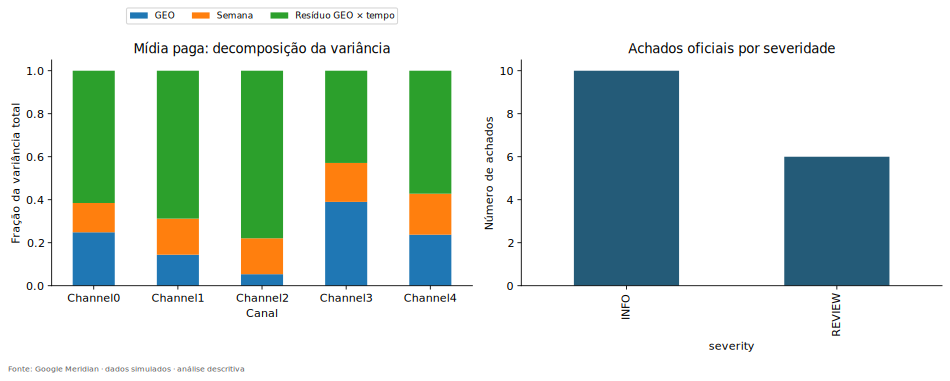

In [ ]:
show(report_07, part="evidence")


## Levar os resultados e continuar o TCC

Ao terminar uma execução, a célula abaixo reúne dados preparados, tabelas, figuras, relatórios e registros em um ZIP. A modelagem ainda não começou. As próximas etapas serão especificação e priors, baseline, convergência, ajuste, posterior, contribuição/ROI, curvas de resposta, análise geo, holdout, sensibilidade e otimização — cada uma só deverá aparecer como concluída quando realmente executada.

In [ ]:
import zipfile
archive_path = ROOT / 'EDA_RESULTS.zip'
with zipfile.ZipFile(archive_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for folder in ['outputs', 'docs', 'data/metadata', 'data/processed']:
        for path in (ROOT / folder).rglob('*'):
            if path.is_file() and '.mplcache' not in str(path):
                archive.write(path, path.relative_to(ROOT))
print(archive_path)
# No Colab, descomente para baixar:
# from google.colab import files
# files.download(str(archive_path))


## Registro da consolidação — 21 de outubro de 2026

As saídas históricas foram preservadas a partir do commit indicado no início. As funções analíticas foram transportadas com remoção dos imports relativos e do prefixo do módulo de gráficos. As adaptações novas se limitam à instalação, à escolha da pasta local, à proveniência independente e à exibição de todas as figuras. A comparação estrutural das funções e a validação dos arquivos são registradas em `docs/CONSOLIDACAO_VALIDACAO.md`.

**Não foi executada novamente a etapa oficial Meridian nesta consolidação.** Os seis REVIEW e as reconciliações exibidos são os resultados históricos preservados. A validação em sessão real do Google Colab também permanece pendente. Uma leitura com resultados salvos e uma execução integral em ambiente novo são evidências diferentes.

O repositório original foi apenas lido. A publicação no repositório novo ficou bloqueada por resposta 403 de permissão da integração; este pacote está preparado para publicação quando o acesso de escrita estiver disponível.

**Verificação desta consolidação:** 44 funções analíticas equivalentes por AST; seis etapas próprias (00–05) reexecutadas em pasta separada e 80 tabelas numericamente concordantes; 293 arquivos de origem copiados byte a byte. Proveniência testada para rejeitar arquivo alterado e função redefinida. Os resultados recalculados de verificação não substituíram as saídas históricas. As funções de análise foram chamadas sem os wrappers dependentes do ambiente Meridian completo; não houve Run all integral.